# Clasificación del perfil de amenaza tecnológica por departamento
## Modelo base entrenado · Proyecto de Aplicación, Etapa 2 (Unidad 2)

**Redes Neuronales · Universidad de La Sabana · Sector elegido: Seguridad y defensa**

| | |
|---|---|
| **Integrantes** | Laura Alejandra Díaz Sastoque (0000288870) · Juan Diego Saldarriaga Muñoz (0000287391) |
| **Actividad** | Actividad 5: Avance del proyecto, modelo base entrenado |
| **Entrega anterior** | Etapa 1: formulación del problema, variables y dataset (Unidad 1) |
| **Fecha** | Septiembre de 2026 |
| **Herramientas** | Python · pandas · scikit-learn · TensorFlow / Keras 3 |

## Resumen ejecutivo

Este notebook implementa, entrena y diagnostica el **modelo base** del proyecto: un perceptrón multicapa en Keras que
estima, con la información disponible al cierre de un año, la probabilidad de que cada departamento tenga el año
siguiente perfil de amenaza **C (armas convencionales y emboscadas)** o **D (mixto)**, a partir de las variables
definidas en la Etapa 1.

| | Resultado |
|---|---|
| **Datos** | Panel departamento–año 2021–2026: 171 filas, 30 departamentos, 7 predictoras (6 de las 7 variables de la U1 y la letalidad derivada). Fuentes: ACLED, SIMCI/ODC (Datos Abiertos Colombia), Global Forest Watch y DANE |
| **Modelo** | MLP 7 → 16 ReLU → 1 sigmoide (145 parámetros), L2 = 10⁻³, Adam y parada temprana. Arquitectura elegida por validación cruzada temporal entre 16 configuraciones |
| **Desempeño fuera de muestra** | ROC-AUC 0,83 y exactitud 0,76 en la prueba 2026 (modelo reajustado). AUC 0,89 en validación temporal 2023–2026 (el azar da 0,50) |
| **Frente a la neurona lineal** | Equivalente en el tiempo (AUC 0,89 vs. 0,88; McNemar p = 1,0). Inferior en departamentos nuevos (0,80 vs. 0,84), salvo con ensamble de semillas (0,85) |
| **Frente a la persistencia** | Inferior (AUC 0,96): el perfil se repite el 86 % de las veces y las variables de la U1 son estructurales |
| **Diagnóstico** | Converge de forma estable y es reproducible (CV del AUC entre semillas 2,8 %). El límite es la generalización con 30 unidades espaciales, no la optimización |
| **Mejora medida** | Agregar la memoria del perfil (E1) sube el AUC temporal de 0,89 a 0,93 y baja la log-loss de 0,44 a 0,36, por debajo de la persistencia (0,38) |

**En una frase:** el modelo base es técnicamente viable y coherente con el problema, pero a escala departamental su
valor agregado sobre la inercia del conflicto es limitado. La evidencia señala dos palancas para la Unidad 3:
memoria del perfil y migración a municipio.

## Cómo leer este notebook

La guía de la actividad pide siete contenidos y la rúbrica evalúa cinco criterios. La tabla indica en qué sección
se responde cada uno, para que la revisión sea directa.

| Contenido exigido / criterio de la rúbrica | Sección |
|---|---|
| Recordatorio sintético del problema formulado · **Coherencia problema–modelo** | §1 (y tabla de trazabilidad U1 → U2), §12 |
| Descripción del dataset (fuente, tamaño, variables, calidad) | §2, §3, §4 |
| Arquitectura y configuración del modelo base · **Implementación y configuración técnica** | §6, §7, §8 |
| Curvas de aprendizaje · Métricas de entrenamiento y validación · **Presentación e interpretación de métricas y curvas** | §9, §10 |
| Diagnóstico técnico (convergencia, estabilidad, generalización) · **Diagnóstico técnico** | §11 |
| Oportunidades de mejora · **Mejoras y trabajo colaborativo** | §13, §14 |
| Conclusiones, artefactos para el informe y referencias | §15, §16, Anexo |

> **Reproducibilidad.** Todas las cifras citadas en el texto corresponden a la ejecución de referencia guardada
> en este archivo (semilla 42, CPU, versiones impresas en §0). El cuaderno corre de principio a fin en Google Colab
> o en local con `acled-data-export.csv` en la misma carpeta; las fuentes externas se descargan solas la primera vez
> y quedan en caché (`datos_externos/`). Si se ejecuta en otro hardware, las cifras pueden variar en decimales.

---
# 0. Configuración del entorno y reproducibilidad

Fijamos una semilla global y activamos el determinismo de operaciones de TensorFlow para que el entrenamiento
de la red sea repetible. También desactivamos las optimizaciones oneDNN, que reordenan sumas en punto flotante y
cambian los resultados en el último decimal de una corrida a otra.

In [1]:
# =============================================================================
# 0.1 Librerías, semilla global y rutas de trabajo
# =============================================================================
import os, sys, time, json, re, math, platform, unicodedata, warnings
from pathlib import Path
from dataclasses import dataclass, asdict, replace

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")    # silencia mensajes informativos de TensorFlow
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")   # resultados numéricos repetibles en CPU
os.environ.setdefault("KERAS_BACKEND", "tensorflow")  # el bucle de entrenamiento (§8) usa tf.GradientTape

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)   # oculta avisos de plataforma y de retrazado
import tensorflow as tf
import keras
from keras import layers
import sklearn
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, matthews_corrcoef, roc_auc_score,
                             average_precision_score, log_loss, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve)
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)                  # fija las semillas de Python, NumPy y TensorFlow
tf.config.experimental.enable_op_determinism()     # operaciones deterministas en TensorFlow
tf.get_logger().setLevel("ERROR"); tf.autograph.set_verbosity(0)

EN_COLAB = "google.colab" in sys.modules
RUTA_ACLED = Path("acled-data-export.csv")
DIR_EXT = Path("datos_externos")                    # caché de fuentes externas (coca, bosque)
DIR_SALIDA = Path("salidas_u2")
DIR_FIG = DIR_SALIDA / "figuras"
for carpeta in (DIR_EXT, DIR_SALIDA, DIR_FIG):
    carpeta.mkdir(parents=True, exist_ok=True)

if not RUTA_ACLED.exists() and EN_COLAB:            # en Colab se sube el CSV si no está en el entorno
    from google.colab import files
    print("Sube el archivo acled-data-export.csv exportado de ACLED:")
    files.upload()
assert RUTA_ACLED.exists(), "No se encontró acled-data-export.csv en la carpeta de trabajo."

entorno = pd.Series({
    "Python": platform.python_version(),
    "Sistema": platform.platform(terse=True),
    "NumPy / pandas": f"{np.__version__} / {pd.__version__}",
    "scikit-learn": sklearn.__version__,
    "TensorFlow / Keras": f"{tf.__version__} / {keras.__version__}",
    "Backend de Keras": keras.backend.backend(),
    "Dispositivos": ", ".join(sorted({d.device_type for d in tf.config.list_physical_devices()})),
    "Semilla global": SEED,
}, name="Valor")
display(entorno.to_frame())

,Valor
Python,3.11.9
Sistema,Windows-10
NumPy / pandas,2.1.2 / 2.2.3
scikit-learn,1.9.0
TensorFlow / Keras,2.21.0 / 3.15.1
Backend de Keras,tensorflow
Dispositivos,CPU
Semilla global,42


In [2]:
# =============================================================================
# 0.2 Estilo gráfico, paleta y funciones auxiliares
# =============================================================================
# Se conservan los colores de perfil de la Etapa 1 (C = ámbar, D = gris, A = rojo, B = azul).
COL = {"C": "#eda100", "D": "#888780", "A": "#e34948", "B": "#2a78d6",
       "mlp": "#2a78d6", "logit": "#eb6834", "pers": "#52514e", "mayor": "#b9b8b2",
       "train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
TINTA, TINTA2, TENUE, GRID, EJE, FONDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
mpl.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial", "Liberation Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA2, "axes.edgecolor": EJE, "axes.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TENUE, "ytick.color": TENUE, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "figure.dpi": 110,
})
CMAP_C = LinearSegmentedColormap.from_list("prop_C", ["#fdf6e6", "#f6d58a", "#eda100", "#a86f00", "#4d3300"])
CMAP_P = LinearSegmentedColormap.from_list("prob_C", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

FIGURAS = []
def guardar(fig, nombre):
    """Guarda la figura en salidas_u2/figuras (PNG, 200 dpi) para reutilizarla en el informe PDF."""
    ruta = DIR_FIG / f"{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    if ruta.name not in FIGURAS:
        FIGURAS.append(ruta.name)

def normalizar(nombre):
    """Llave de cruce entre fuentes: minúsculas, sin tildes ni signos ('Bogotá, D.C.' -> 'bogota')."""
    s = unicodedata.normalize("NFKD", str(nombre)).encode("ascii", "ignore").decode().lower()
    s = re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", s)).strip()
    if s.startswith("bogota"):
        return "bogota"
    if s.startswith("san andres") or s.startswith("archipielago"):
        return "san andres"
    return s

NOMBRE = {  # nombres con tildes para tablas y figuras
    "amazonas": "Amazonas", "antioquia": "Antioquia", "arauca": "Arauca", "atlantico": "Atlántico",
    "bogota": "Bogotá D.C.", "bolivar": "Bolívar", "boyaca": "Boyacá", "caldas": "Caldas", "caqueta": "Caquetá",
    "casanare": "Casanare", "cauca": "Cauca", "cesar": "Cesar", "choco": "Chocó", "cordoba": "Córdoba",
    "cundinamarca": "Cundinamarca", "guainia": "Guainía", "guaviare": "Guaviare", "huila": "Huila",
    "la guajira": "La Guajira", "magdalena": "Magdalena", "meta": "Meta", "narino": "Nariño",
    "norte de santander": "Norte de Santander", "putumayo": "Putumayo", "quindio": "Quindío",
    "risaralda": "Risaralda", "san andres": "San Andrés", "santander": "Santander", "sucre": "Sucre",
    "tolima": "Tolima", "valle del cauca": "Valle del Cauca", "vaupes": "Vaupés", "vichada": "Vichada"}

def haversine_km(lat1, lon1, lat2, lon2):
    """Distancia geodésica (km) sobre una esfera de radio 6.371 km."""
    la1, lo1, la2, lo2 = map(np.radians, (lat1, lon1, lat2, lon2))
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(h))

def bce(y, p, eps=1e-7):
    """Entropía cruzada binaria media (log-loss) sin ponderar."""
    y = np.asarray(y, float); p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def metricas(y, p, umbral=0.5):
    """Batería de métricas para la clase positiva C (1) frente a D (0)."""
    y = np.asarray(y).astype(int); p = np.asarray(p, float); yhat = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    dos = len(np.unique(y)) == 2
    return {"Exactitud": accuracy_score(y, yhat),
            "Exact. balanceada": balanced_accuracy_score(y, yhat),
            "Precisión C": precision_score(y, yhat, zero_division=0),
            "Sensibilidad C": recall_score(y, yhat, zero_division=0),
            "Especificidad D": tn / (tn + fp) if (tn + fp) else np.nan,
            "F1 C": f1_score(y, yhat, zero_division=0),
            "MCC": matthews_corrcoef(y, yhat),
            "ROC-AUC": roc_auc_score(y, p) if dos else np.nan,
            "PR-AUC": average_precision_score(y, p) if dos else np.nan,
            "Log-loss": bce(y, p),
            "Brier": brier_score_loss(y, p)}

def bootstrap_ic(y, p, fn, n=2000, semilla=SEED):
    """IC 95 % percentil por bootstrap estratificado por clase (conserva la prevalencia en cada réplica)."""
    rng = np.random.default_rng(semilla); y = np.asarray(y).astype(int); p = np.asarray(p, float)
    i0, i1 = np.where(y == 0)[0], np.where(y == 1)[0]
    vals = [fn(y[idx], p[idx]) for idx in (np.concatenate([rng.choice(i0, len(i0)), rng.choice(i1, len(i1))])
                                           for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])

def tabla(df, dec=3, **kw):
    """Muestra un DataFrame con formato numérico uniforme."""
    return display(df.style.format(precision=dec, thousands=".", decimal=",", na_rep="–", **kw))

print("Estilo y utilidades listos.")

Estilo y utilidades listos.


---
# 1. Recordatorio sintético del problema (Etapa 1)

**Pregunta orientadora formulada en la Unidad 1:**

> *¿Cómo orientar la adquisición, transferencia de tecnología y fabricación de sistemas de seguridad y defensa de las
> Fuerzas de Colombia en función del perfil de amenaza tecnológica predominante de los municipios colombianos, según
> las variables de actividad armada histórica, geografía operacional y economías ilícitas, de modo que se optimice la
> inversión de recursos?*

La Etapa 1 dejó definidos el fenómeno, la variable objetivo y las predictoras, y declaró tres hallazgos que
condicionan esta entrega:

1. **Resolución espacial.** El export gratuito de ACLED solo desagrega hasta **departamento** (33 unidades); el
   municipio requiere el registro de evento individual (con licencia). Por eso la unidad táctica sigue siendo el
   municipio, pero el modelo se valida por ahora a nivel departamental.
2. **Variable objetivo binaria.** Bajo la regla del 50 %, ningún departamento tuvo perfil A (IED/explosivos) o B
   (drones/remotos) dominante, así que el clasificador se ajustó a **C (armas convencionales y emboscadas) vs. D
   (amenaza mixta)**.
3. **Tamaño muestral.** Una fila por departamento (33 filas) no basta para entrenar una red. La Unidad 1 comprometió
   para esta etapa un **panel departamento–año** (33 × 6 ≈ 198 filas), que es lo que implementamos.

### 1.1 Formulación del modelo base

Para cada departamento $d$ y año $t$ la etiqueta se construye con la regla de la Etapa 1:

$$
s^{C}_{d,t} = \frac{\#\{\text{eventos de subtipos C en } d,t\}}{\#\{\text{eventos en } d,t\}},
\qquad
y_{d,t} = \mathbb{1}\left[s^{C}_{d,t} \ge 0.5\right] \quad (1 = \text{perfil C},\; 0 = \text{perfil D}).
$$

La red aprende la probabilidad del perfil del año siguiente a partir de la información disponible al cierre del año anterior:

$$
\hat{p}_{d,t} = f_{\boldsymbol{\theta}}\left(\mathbf{x}_{d,t-1}\right) = P\left(y_{d,t}=1 \mid \mathbf{x}_{d,t-1}\right).
$$

Usamos el rezago $t-1 \rightarrow t$ por dos razones:

* **Evita la circularidad.** La etiqueta de $t$ se calcula con los eventos de $t$. Si usáramos como predictores los
  eventos o las fatalidades del mismo año, parte de la respuesta entraría en la pregunta (las fatalidades son
  consecuencia de los mismos ataques que definen el perfil C) y las métricas quedarían infladas.
* **Replica el momento real de la decisión.** La asignación de tecnología para un año se decide con lo observado hasta el
  cierre del año anterior; por ejemplo, la inversión de 2026 citada en la Etapa 1 se planeó con datos de 2025. El
  modelo responde exactamente esa pregunta: *con lo que sé hoy, ¿qué perfil tendrá cada territorio el próximo año?*

### 1.2 Trazabilidad de variables: de la Etapa 1 al modelo base

| ID (U1) | Variable definida en la Etapa 1 | Operacionalización en el modelo base | Fuente | Estado |
|---|---|---|---|---|
| $y$ | Perfil de amenaza predominante | $\mathbb{1}[s^C_{d,t} \ge 0.5]$, regla y mapeo de subtipos **idénticos** a la U1 | ACLED | ✅ Implementada |
| $x_1$ | Frecuencia total de eventos | $\log(1+\text{eventos anualizados}_{t-1})$ | ACLED | ✅ Implementada |
| $x_2$ | Fatalidades acumuladas | $\log(1+\text{fatalidades anualizadas}_{t-1})$ | ACLED | ✅ Implementada |
| $x_{2b}$ | *(derivada de $x_2$)* letalidad por evento | $\text{fatalidades}_{t-1}/\text{eventos}_{t-1}$: la U1 justificó $x_2$ porque *"distingue letalidad por arma"* | ACLED | ✅ Derivada |
| $x_3$ | Nº de grupos armados activos | Requiere los campos `actor1/actor2` del registro de evento individual | ACLED (licencia) | ⏳ Pendiente (U3) |
| $x_4$ | Hectáreas de cultivos ilícitos | $\log(1+\text{ha de coca}_{t-1})$; se refina el promedio 2020-2024 de la U1 a un valor **anual** | SIMCI–UNODC vía MinJusticia/ODC (datos.gov.co) | ✅ Implementada |
| $x_5$ | Cobertura forestal (%) | % del área con dosel arbóreo ≥ 30 % en $t-1$ | Global Forest Watch / Hansen et al. (sustituye a IGAC) | ✅ Fuente sustituta |
| $x_6$ | Distancia a casco urbano (km) | Distancia geodésica del centroide departamental a Bogotá (lejanía del centro político) | ACLED (centroides) | ⚠️ Proxy departamental |
| $x_7$ | Índice de pobreza multidimensional | IPM 2018 por departamento (% de personas) | DANE, ECV 2018 | ✅ Implementada |

Todas las predictoras son **numéricas continuas**, como se definió en la Etapa 1. Las que cambian de fuente o de
forma se justifican en §4 y quedan registradas en la bitácora de decisiones (§14).

### 1.3 De la predicción a la decisión

| Perfil proyectado | Lectura operacional (Etapa 1, §2) | Énfasis tecnológico que orienta |
|---|---|---|
| **C: convencional / emboscada** | La violencia directa entre actores armados domina el territorio | ISR (inteligencia, vigilancia y reconocimiento), detección temprana, movilidad protegida |
| **D: mixto** | Ningún vector armado supera el 50 %; pesan la protesta, el disturbio y la violencia mixta | Portafolio flexible y capacidades de orden público, con vigilancia de señales A/B |
| **Señal A/B** (no dominante) | IED y drones: bajo volumen pero alto impacto (hallazgo crítico U1 §5.4) | Alerta complementaria para C-UAS y detección de AEI, aunque el perfil sea C o D |

---
# 2. Dataset ACLED: descripción y auditoría de calidad

**Fuente.** *Armed Conflict Location & Event Data* (ACLED; Raleigh et al., 2010), export agregado semanal de
Colombia, descargado con registro académico gratuito (licencia de uso no comercial). Cada fila es la combinación
**semana × departamento × subtipo de evento**.

| Columna | Descripción | Uso en el modelo |
|---|---|---|
| `week` | Fecha de inicio de la semana (sábado) | Construcción del año $t$ |
| `country`, `region` | País y región | Filtro (se excluyen aguas internacionales) |
| `admin1` | Departamento | Unidad de análisis |
| `event_type`, `sub_event_type` | Taxonomía ACLED (6 tipos, 21 subtipos presentes) | Variable objetivo $y$ |
| `events` | Número de eventos de ese subtipo en la semana | $x_1$ y $y$ |
| `fatalities` | Fatalidades reportadas | $x_2$, $x_{2b}$ |
| `population_exposure` | Población expuesta estimada (texto con separador de miles) | Solo auditoría |
| `disorder_type` | Violencia política / manifestaciones / desarrollos estratégicos | Solo auditoría |
| `centroid_latitude`, `centroid_longitude` | Centroide del departamento | $x_6$ y mapa (§12) |

In [3]:
# =============================================================================
# 2.1 Carga del archivo original
# =============================================================================
acled_bruto = pd.read_csv(RUTA_ACLED, encoding="utf-8-sig")
acled_bruto["week"] = pd.to_datetime(acled_bruto["week"])
print(f"Archivo: {RUTA_ACLED.name} | {RUTA_ACLED.stat().st_size / 1e6:.2f} MB | "
      f"{acled_bruto.shape[0]:,} filas × {acled_bruto.shape[1]} columnas")
display(acled_bruto.head(4))

Archivo: acled-data-export.csv | 2.24 MB | 17,573 filas × 12 columnas


,week,region,country,admin1,event_type,sub_event_type,events,fatalities,population_exposure,disorder_type,centroid_latitude,centroid_longitude
0,2019-12-28,South America,Colombia,Antioquia,Battles,Armed clash,2,0,"14,172",Political violence,7.157,-75.445
1,2019-12-28,South America,Colombia,Antioquia,Violence against civilians,Attack,1,1,"9,111",Political violence,7.157,-75.445
2,2019-12-28,South America,Colombia,Atlantico,Violence against civilians,Attack,1,1,"803,116",Political violence,10.668,-74.994
3,2019-12-28,South America,Colombia,Atlantico,Riots,Mob violence,1,0,"190,181",Political violence,10.668,-74.994


In [4]:
# =============================================================================
# 2.2 Auditoría de calidad: cada verificación con su implicación para el modelo
# =============================================================================
def auditar(df):
    semanas = np.sort(df["week"].unique())
    saltos = np.diff(semanas).astype("timedelta64[D]").astype(int)
    fuera = df.loc[df["country"] != "Colombia", "admin1"].unique()
    pob = pd.to_numeric(df["population_exposure"].astype(str).str.replace(",", "", regex=False), errors="coerce")
    col = df[df["country"] == "Colombia"]
    filas = [
        ("Registros / columnas", f"{len(df):,} / {df.shape[1]}", "Archivo ligero (≈2 MB), carga directa con pandas"),
        ("Registros fuera de Colombia", f"{(df['country'] != 'Colombia').sum()} ({', '.join(fuera)})",
         "Se excluyen: aguas internacionales, no son territorio de decisión"),
        ("Cobertura temporal", f"{df['week'].min():%Y-%m-%d} → {df['week'].max():%Y-%m-%d}",
         "Se descarta la semana 2019-12-28 (horizonte 2020+ de la U1)"),
        ("Semanas distintas / saltos ≠ 7 días", f"{len(semanas)} / {(saltos != 7).sum()}", "Serie semanal continua, sin huecos"),
        ("Valores faltantes (todas las columnas)", f"{int(df.isna().sum().sum())}", "No se requiere imputación"),
        ("Duplicados exactos", f"{int(df.duplicated().sum())}", "Sin doble conteo"),
        ("Duplicados por llave semana–depto–subtipo", f"{int(df.duplicated(['week', 'admin1', 'sub_event_type']).sum())}",
         "La llave es única: agregación segura"),
        ("Rangos: events ≥ 1 y fatalities ≥ 0", f"{bool((df['events'] >= 1).all() and (df['fatalities'] >= 0).all())}",
         f"events máx = {df['events'].max()}, fatalities máx = {df['fatalities'].max()}"),
        ("Subtipos asignados a más de un tipo", f"{int((df.groupby('sub_event_type')['event_type'].nunique() > 1).sum())}",
         "Taxonomía consistente con el codebook"),
        ("Centroides distintos por departamento (máx.)",
         f"{int(df.groupby('admin1')[['centroid_latitude', 'centroid_longitude']].nunique().max().max())}",
         "Un centroide fijo por departamento"),
        ("population_exposure no convertible a número", f"{int(pob.isna().sum())}", "Texto con separador de miles: se limpia"),
        ("Departamentos de Colombia (admin1)", f"{col['admin1'].nunique()}", "32 departamentos + Bogotá D.C."),
    ]
    return pd.DataFrame(filas, columns=["Verificación", "Resultado", "Implicación para el modelo"])

display(auditar(acled_bruto).style.hide(axis="index"))

Verificación,Resultado,Implicación para el modelo
Registros / columnas,"17,573 / 12","Archivo ligero (≈2 MB), carga directa con pandas"
Registros fuera de Colombia,32 (North Atlantic Ocean),"Se excluyen: aguas internacionales, no son territorio de decisión"
Cobertura temporal,2019-12-28 → 2026-08-15,Se descarta la semana 2019-12-28 (horizonte 2020+ de la U1)
Semanas distintas / saltos ≠ 7 días,347 / 0,"Serie semanal continua, sin huecos"
Valores faltantes (todas las columnas),0,No se requiere imputación
Duplicados exactos,0,Sin doble conteo
Duplicados por llave semana–depto–subtipo,0,La llave es única: agregación segura
Rangos: events ≥ 1 y fatalities ≥ 0,True,"events máx = 85, fatalities máx = 48"
Subtipos asignados a más de un tipo,0,Taxonomía consistente con el codebook
Centroides distintos por departamento (máx.),1,Un centroide fijo por departamento


In [5]:
# =============================================================================
# 2.3 Filtrado al horizonte de estudio y conciliación con las cifras de la Etapa 1
# =============================================================================
acled = acled_bruto[(acled_bruto["country"] == "Colombia") & (acled_bruto["week"] >= "2020-01-01")].copy()
acled["anio"] = acled["week"].dt.year
acled["depto"] = acled["admin1"].map(normalizar)
acled["population_exposure"] = pd.to_numeric(acled["population_exposure"].astype(str).str.replace(",", "", regex=False))

corte_u1 = acled[acled["week"] <= "2026-08-01"]
conciliacion = pd.DataFrame({
    "Etapa 1 (reportado)": [17491, 33336, 13732, "2026-08-01"],
    "Export actual, mismo corte": [len(corte_u1), int(corte_u1["events"].sum()), int(corte_u1["fatalities"].sum()), "2026-08-01"],
    "Export actual, completo": [len(acled), int(acled["events"].sum()), int(acled["fatalities"].sum()),
                                f"{acled['week'].max():%Y-%m-%d}"],
}, index=["Registros semanales", "Eventos", "Fatalidades", "Última semana"])
display(conciliacion)
dif = 100 * (len(corte_u1) - 17491) / 17491
print(f"Diferencia de registros frente a la Etapa 1 con el mismo corte: {dif:+.2f} %")

,Etapa 1 (reportado),"Export actual, mismo corte","Export actual, completo"
Registros semanales,17491,17442,17533
Eventos,33336,33144,33275
Fatalidades,13732,13525,13591
Última semana,2026-08-01,2026-08-01,2026-08-15


Diferencia de registros frente a la Etapa 1 con el mismo corte: -0.28 %


**Lectura.** El archivo es el mismo tipo de export de la Etapa 1 pero actualizado al 15 de agosto de 2026. ACLED
revisa retroactivamente su base (reclasifica y fusiona eventos a medida que verifica fuentes), así que con el mismo
corte los conteos difieren en menos de 0,5 %. La diferencia no altera la estructura de los datos ni las conclusiones de
la Etapa 1, pero la dejamos documentada porque las cifras de este informe no coinciden al dígito con las del
anterior. Más abajo (§3.2) comprobamos que el resultado central de la Etapa 1, la partición de departamentos entre
C y D, se reproduce con el export actualizado.

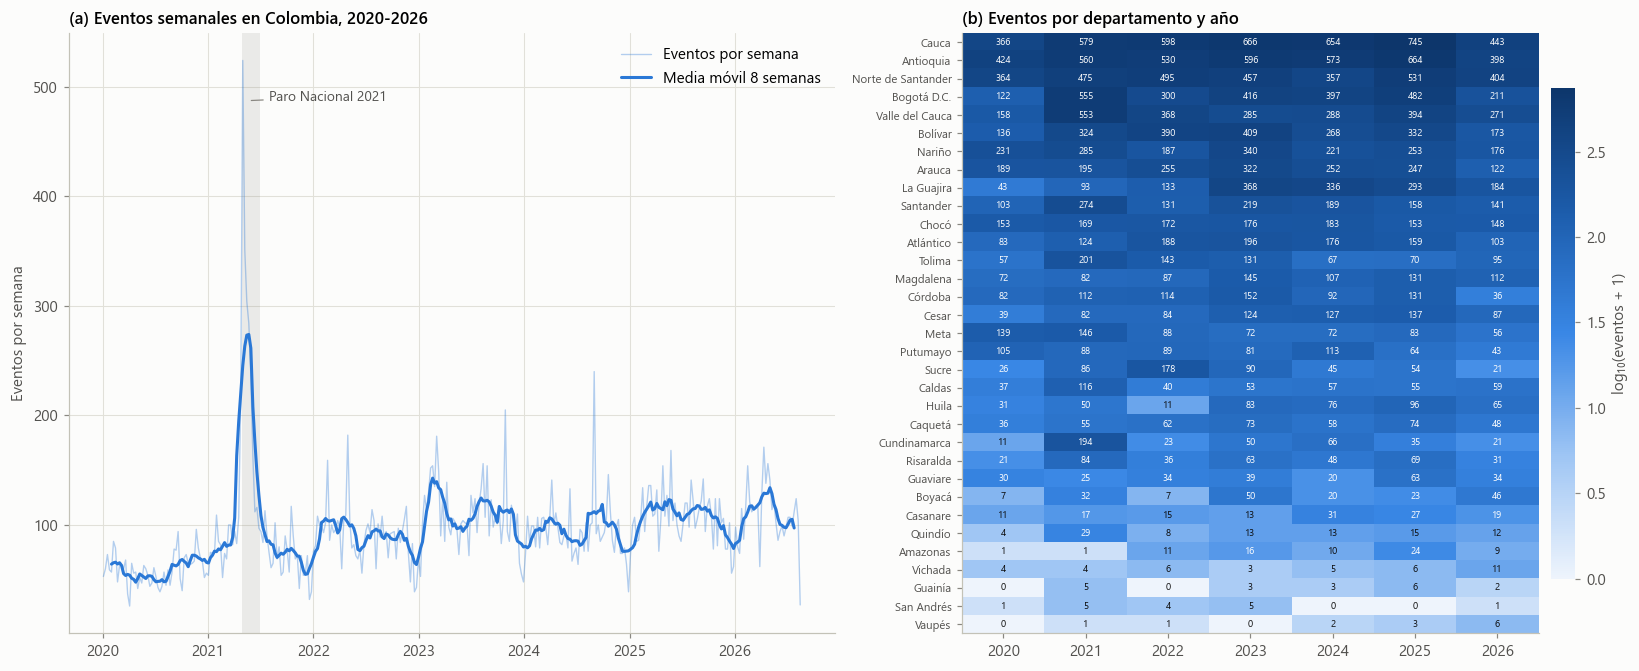

In [6]:
# =============================================================================
# 2.4 Cobertura de los datos: dinámica nacional y densidad departamento–año
# =============================================================================
semanal = acled.groupby("week")["events"].sum()
eventos_da = acled.pivot_table(index="depto", columns="anio", values="events", aggfunc="sum", fill_value=0)
eventos_da = eventos_da.loc[eventos_da.sum(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.plot(semanal.index, semanal.values, color=COL["mlp"], lw=0.9, alpha=0.35, label="Eventos por semana")
ax.plot(semanal.index, semanal.rolling(8, center=True).mean(), color=COL["mlp"], lw=2, label="Media móvil 8 semanas")
ax.axvspan(pd.Timestamp("2021-04-28"), pd.Timestamp("2021-06-30"), color=COL["D"], alpha=0.15, lw=0)
ax.annotate("Paro Nacional 2021", xy=(pd.Timestamp("2021-05-20"), semanal.max() * 0.93), ha="left",
            xytext=(pd.Timestamp("2021-08-01"), semanal.max() * 0.93), color=TINTA2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=TENUE, lw=0.8))
ax.set_title("(a) Eventos semanales en Colombia, 2020-2026")
ax.set_ylabel("Eventos por semana"); ax.legend(loc="upper right")

ax = axes[1]
im = ax.imshow(np.log10(eventos_da.values + 1), aspect="auto", cmap=CMAP_P)
ax.set_xticks(range(eventos_da.shape[1]), eventos_da.columns)
ax.set_yticks(range(len(eventos_da)), [NOMBRE[d] for d in eventos_da.index], fontsize=7.5)
for i in range(eventos_da.shape[0]):
    for j in range(eventos_da.shape[1]):
        v = eventos_da.values[i, j]
        ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center", fontsize=6.2,
                color="white" if np.log10(v + 1) > 0.42 * np.log10(eventos_da.values.max() + 1) else TINTA)
ax.grid(False); ax.set_title("(b) Eventos por departamento y año")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("log₁₀(eventos + 1)")
cb.outline.set_visible(False)
fig.tight_layout(); guardar(fig, "fig01_cobertura_datos"); plt.show()

**Lectura.** (a) La serie no tiene huecos, y el pico de 2021 corresponde al Paro Nacional, cuando la protesta
disparó el conteo sin cambiar la violencia armada de fondo; es la distorsión que la Etapa 1 ya había señalado.
(b) La densidad de datos es muy desigual: Cauca, Antioquia o Norte de Santander suelen superar los 400 eventos por
año, mientras que Vaupés, Guainía o San Andrés tienen un solo dígito. Con tan pocos eventos, un solo evento cambia la
proporción de subtipos en más de 10 puntos, y eso hace poco confiable la etiqueta de esas celdas. Lo tratamos
con un umbral mínimo de eventos (§3.3).

---
# 3. Construcción de la variable objetivo (panel departamento–año)

## 3.1 Mapeo de subtipos a perfiles (regla de la Etapa 1, sin cambios)

Reutilizamos **literalmente** el diccionario de la Etapa 1. Los subtipos que no aparecen en él toman el perfil D
(`fillna('D')` en el código original). Dejamos explícita esa asignación por defecto porque en la Etapa 1 quedaba
implícita en el código.

In [7]:
# =============================================================================
# 3.1 Mapeo subtipo -> perfil (idéntico al notebook de la Etapa 1)
# =============================================================================
MAPA_PERFIL_U1 = {
    "Remote explosive/landmine/IED": "A", "Grenade": "A", "Suicide bomb": "A", "Chemical weapon": "A",
    "Air/drone strike": "B",
    "Armed clash": "C", "Attack": "C", "Shooting": "C", "Abduction/forced disappearance": "C",
    "Looting/property destruction": "C", "Disrupted weapons use": "C",
    "Mob violence": "D", "Peaceful protest": "D", "Excessive force against protesters": "D", "Arrests": "D",
    "Government regains territory": "D", "Non-state actor overtakes territory": "D",
}
subtipos = (acled.groupby(["event_type", "sub_event_type"])[["events", "fatalities"]].sum()
            .reset_index().sort_values("events", ascending=False))
subtipos["perfil"] = subtipos["sub_event_type"].map(MAPA_PERFIL_U1).fillna("D")
subtipos["asignación"] = np.where(subtipos["sub_event_type"].isin(MAPA_PERFIL_U1), "explícita (U1)", "por defecto → D (U1)")
subtipos["% eventos"] = 100 * subtipos["events"] / subtipos["events"].sum()
subtipos["fatalidades/evento"] = subtipos["fatalities"] / subtipos["events"]
tabla(subtipos.rename(columns={"event_type": "Tipo", "sub_event_type": "Subtipo", "events": "Eventos",
                               "fatalities": "Fatalidades"}).reset_index(drop=True), dec=2)
print(subtipos.groupby("perfil")["% eventos"].sum().round(1).rename("% de eventos por perfil").to_string())

,Tipo,Subtipo,Eventos,Fatalidades,perfil,asignación,% eventos,fatalidades/evento
0,Protests,Peaceful protest,10.836,0,D,explícita (U1),"32,56","0,00"
1,Violence against civilians,Attack,7.802,9.043,C,explícita (U1),"23,45","1,16"
2,Battles,Armed clash,4.785,3.630,C,explícita (U1),"14,38","0,76"
3,Strategic developments,Looting/property destruction,1.566,0,C,explícita (U1),"4,71","0,00"
4,Riots,Violent demonstration,1.276,124,D,por defecto → D (U1),"3,83","0,10"
5,Riots,Mob violence,1.257,183,D,explícita (U1),"3,78","0,15"
6,Violence against civilians,Abduction/forced disappearance,1.223,0,C,explícita (U1),"3,68","0,00"
7,Strategic developments,Other,1.145,3,D,por defecto → D (U1),"3,44","0,00"
8,Strategic developments,Disrupted weapons use,1.072,18,C,explícita (U1),"3,22","0,02"
9,Explosions/Remote violence,Remote explosive/landmine/IED,931,290,A,explícita (U1),"2,80","0,31"


perfil
A     3.9
B     0.8
C    49.4
D    45.9


**Lectura.** La etiqueta descansa sobre pocos subtipos. *Peaceful protest* (D), *Attack* y *Armed clash* (C) suman
el 70 % de los eventos, y los subtipos A y B juntos apenas llegan al 4,7 % (3,9 % y 0,8 %). La columna de letalidad
confirma la intuición de la Etapa 1: los dos subtipos C más frecuentes (*Attack*, 1,16 fatalidades por evento;
*Armed clash*, 0,76) son entre 5 y 10 veces más letales que los disturbios D, y la protesta pacífica tiene letalidad
nula. Eso respalda usar $x_2$ y $x_{2b}$, medidos en el año anterior, como predictores.

Dos subtipos con significado armado quedan en D por la regla por defecto: *Shelling/artillery/missile attack* y
*Sexual violence*. Los mantenemos así para no romper la trazabilidad con la Etapa 1, y en §3.4 medimos cuánto
cambiaría la etiqueta si se reasignaran.

In [8]:
# =============================================================================
# 3.2 Panel departamento–año y réplica del resultado de la Etapa 1
# =============================================================================
def construir_panel(df, mapa):
    """Agrega los eventos semanales al nivel departamento–año y calcula proporciones y etiqueta por perfil."""
    d = df.assign(perfil=df["sub_event_type"].map(mapa).fillna("D"))
    semanas = d.groupby("anio")["week"].nunique()
    conteo = d.pivot_table(index=["depto", "anio"], columns="perfil", values="events", aggfunc="sum", fill_value=0)
    conteo = conteo.reindex(columns=list("ABCD"), fill_value=0)
    base = pd.MultiIndex.from_product([sorted(d["depto"].unique()), sorted(d["anio"].unique())], names=["depto", "anio"])
    panel = conteo.reindex(base, fill_value=0)
    panel["eventos"] = panel[list("ABCD")].sum(axis=1)
    panel["fatalidades"] = d.groupby(["depto", "anio"])["fatalities"].sum().reindex(base, fill_value=0)
    panel = panel.reset_index()
    panel["semanas"] = panel["anio"].map(semanas)
    for k in "ABCD":
        panel[f"s_{k}"] = panel[k] / panel["eventos"].where(panel["eventos"] > 0)
    panel["perfil"] = np.select([panel["s_C"] >= .5, panel["s_A"] >= .5, panel["s_B"] >= .5], ["C", "A", "B"], "D")
    panel.loc[panel["eventos"] == 0, "perfil"] = None
    panel["y"] = np.where(panel["eventos"] > 0, (panel["perfil"] == "C").astype(float), np.nan)
    return panel

panel = construir_panel(acled, MAPA_PERFIL_U1)
print(f"Panel: {panel['depto'].nunique()} departamentos × {panel['anio'].nunique()} años = {len(panel)} celdas "
      f"({panel['anio'].min()}-{panel['anio'].max()}; 2026 con {panel.loc[panel.anio == 2026, 'semanas'].iat[0]} semanas)")
print("Celdas con perfil A o B dominante:", int(panel["perfil"].isin(["A", "B"]).sum()))

# Réplica de la Etapa 1: un perfil por departamento con todo el periodo agregado
total_depto = panel.groupby("depto")[list("ABCD")].sum()
perfil_global = np.where(total_depto["C"] / total_depto.sum(axis=1) >= .5, "C", "D")
print("\nRéplica Etapa 1 (perfil agregado 2020-2026):",
      pd.Series(perfil_global).value_counts().to_dict(), "| Etapa 1 reportó {'D': 17, 'C': 16}")

Panel: 33 departamentos × 7 años = 231 celdas (2020-2026; 2026 con 33 semanas)
Celdas con perfil A o B dominante: 0

Réplica Etapa 1 (perfil agregado 2020-2026): {'D': 17, 'C': 16} | Etapa 1 reportó {'D': 17, 'C': 16}


Celdas 2021-2026 con eventos: 194 | con ≥ 10 eventos (etiqueta confiable): 171
Error estándar máximo de s_C con n = 10 eventos: ±0.158


Perfil t,C,D
Perfil t-1,,
C,69,12
D,11,73


Persistencia año a año: 86.1% de los departamentos repite perfil


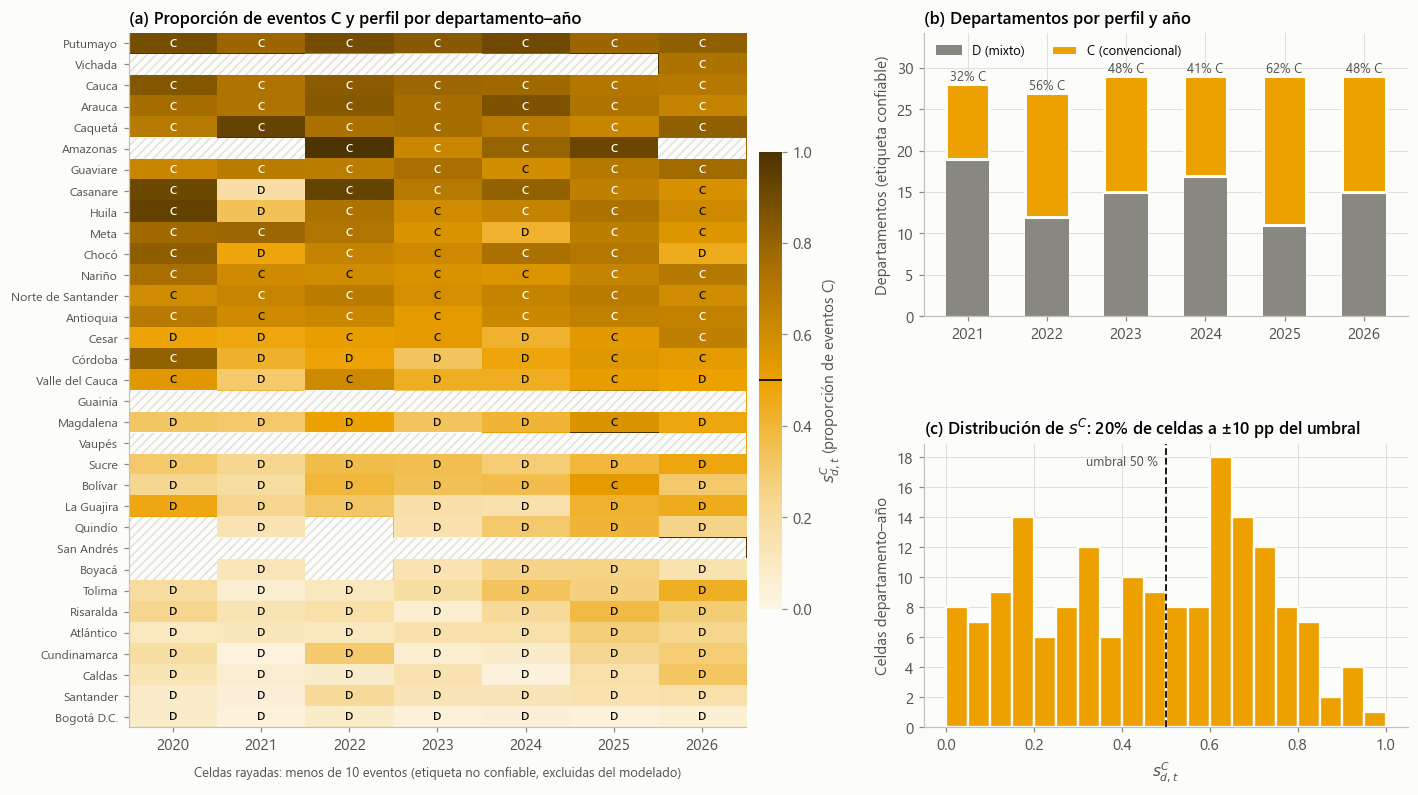

In [9]:
# =============================================================================
# 3.3 Confiabilidad de la etiqueta y dinámica temporal de los perfiles
# =============================================================================
MIN_EVENTOS = 10   # umbral de confiabilidad de la etiqueta (justificación en el texto)
panel["confiable"] = panel["eventos"] >= MIN_EVENTOS
etiquetables = panel[(panel["anio"] >= 2021) & panel["confiable"]]
print(f"Celdas 2021-2026 con eventos: {int(((panel.anio >= 2021) & (panel.eventos > 0)).sum())} | "
      f"con ≥ {MIN_EVENTOS} eventos (etiqueta confiable): {len(etiquetables)}")
print(f"Error estándar máximo de s_C con n = {MIN_EVENTOS} eventos: ±{np.sqrt(.25 / MIN_EVENTOS):.3f}")

# Matriz de transición entre años consecutivos (celdas confiables en t-1 y en t)
pv = panel.pivot(index="depto", columns="anio", values="perfil").where(panel.pivot(index="depto", columns="anio", values="confiable"))
pares = pd.concat([pd.DataFrame({"t-1": pv[a - 1].values, "t": pv[a].values}) for a in range(2021, 2027)]).dropna()
trans = pd.crosstab(pares["t-1"], pares["t"], rownames=["Perfil t-1"], colnames=["Perfil t"])
display(trans)
persistencia = np.trace(trans.values) / trans.values.sum()
print(f"Persistencia año a año: {persistencia:.1%} de los departamentos repite perfil")

fig = plt.figure(figsize=(15, 8.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.45, wspace=0.25)
ax = fig.add_subplot(gs[:, 0])
sC = panel.pivot(index="depto", columns="anio", values="s_C")
conf = panel.pivot(index="depto", columns="anio", values="confiable")
orden = sC.mean(axis=1).sort_values(ascending=False).index
sC, conf, pvo = sC.loc[orden], conf.loc[orden], panel.pivot(index="depto", columns="anio", values="perfil").loc[orden]
im = ax.imshow(sC.values, cmap=CMAP_C, vmin=0, vmax=1, aspect="auto")
for i in range(sC.shape[0]):
    for j in range(sC.shape[1]):
        if not conf.values[i, j]:
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor=FONDO, edgecolor=GRID, hatch="////", lw=0))
            continue
        ax.text(j, i, pvo.values[i, j], ha="center", va="center", fontsize=7.5, fontweight="semibold",
                color="white" if sC.values[i, j] > .62 else TINTA)
ax.set_xticks(range(sC.shape[1]), sC.columns); ax.set_yticks(range(len(orden)), [NOMBRE[d] for d in orden], fontsize=8)
ax.grid(False); ax.set_title("(a) Proporción de eventos C y perfil por departamento–año")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label("$s^C_{d,t}$ (proporción de eventos C)")
cb.ax.axhline(0.5, color=TINTA, lw=1.2); cb.outline.set_visible(False)
ax.set_xlabel(f"Celdas rayadas: menos de {MIN_EVENTOS} eventos (etiqueta no confiable, excluidas del modelado)",
              fontsize=8.5, color=TINTA2, labelpad=8)

ax = fig.add_subplot(gs[0, 1])
cnt = etiquetables.groupby(["anio", "perfil"]).size().unstack(fill_value=0)[["C", "D"]]
ax.bar(cnt.index, cnt["D"], color=COL["D"], width=0.55, label="D (mixto)")
ax.bar(cnt.index, cnt["C"], bottom=cnt["D"], color=COL["C"], width=0.55, label="C (convencional)",
       edgecolor=FONDO, linewidth=2)
for a in cnt.index:
    ax.text(a, cnt.loc[a].sum() + 0.4, f"{cnt.loc[a, 'C'] / cnt.loc[a].sum():.0%} C", ha="center", fontsize=8.5, color=TINTA2)
ax.set_title("(b) Departamentos por perfil y año"); ax.set_ylabel("Departamentos (etiqueta confiable)")
ax.set_ylim(0, cnt.sum(axis=1).max() * 1.18); ax.legend(ncol=2, loc="upper left", fontsize=8.5)

ax = fig.add_subplot(gs[1, 1])
ax.hist(etiquetables["s_C"], bins=np.linspace(0, 1, 21), color=COL["C"], edgecolor=FONDO, linewidth=1.5)
ax.axvline(0.5, color=TINTA, lw=1.2, ls="--"); ax.text(0.49, ax.get_ylim()[1] * 0.96, "umbral 50 % ", fontsize=8.5, color=TINTA2, ha="right", va="top")
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
cerca = ((etiquetables["s_C"] - .5).abs() < .1).mean()
ax.set_title(f"(c) Distribución de $s^C$: {cerca:.0%} de celdas a ±10 pp del umbral")
ax.set_xlabel("$s^C_{d,t}$"); ax.set_ylabel("Celdas departamento–año")
guardar(fig, "fig02_variable_objetivo"); plt.show()

**Lectura.**

* **Umbral de confiabilidad.** Con $n$ eventos, la proporción $s^C$ tiene un error estándar de hasta
  $\sqrt{0.25/n}$. Con menos de 10 eventos ese error supera los 16 puntos y la etiqueta se decide casi al azar.
  Por eso excluimos esas celdas (rayadas en el panel a), que corresponden sobre todo a departamentos de la Amazonía
  y la Orinoquía con muy pocos registros. De 194 celdas 2021-2026 con eventos quedan **171 filas etiquetadas** (88 %),
  en línea con las ≈198 filas previstas en la Unidad 1.
* **Balance de clases.** Las clases quedan casi balanceadas en el agregado, pero **la prevalencia de C cambia con el
  tiempo** (panel b). Baja al 32 % en 2021 por el Paro Nacional, que infló el componente D, y alcanza su máximo
  (62 %) en 2025, año de la ruptura de los diálogos y de la crisis del Catatumbo. Este cambio de prevalencia entre años será clave para
  interpretar las métricas de validación (§10) y la calibración.
* **Persistencia.** El 86 % de los departamentos repite perfil de un año al siguiente (matriz de transición: 69 C→C,
  73 D→D y solo 23 cambios). Esa inercia hace que "repetir el perfil del año pasado" sea una línea base muy fuerte, y
  la incluimos explícitamente (§6).
* **Ambigüedad cerca del umbral.** El 20 % de las celdas cae a menos de 10 puntos del 50 % (panel c). En esas celdas
  la etiqueta puede cambiar por unos pocos eventos, así que esperamos que los errores del modelo se concentren ahí
  (lo verificamos en §11.5).

In [10]:
# =============================================================================
# 3.4 Sensibilidad de la etiqueta a los subtipos asignados por defecto
# =============================================================================
MAPA_ALTERNATIVO = {**MAPA_PERFIL_U1, "Shelling/artillery/missile attack": "B", "Sexual violence": "C"}
panel_alt = construir_panel(acled, MAPA_ALTERNATIVO)
comp = panel[["depto", "anio", "perfil", "confiable"]].merge(panel_alt[["depto", "anio", "perfil"]],
                                                            on=["depto", "anio"], suffixes=("_u1", "_alt"))
comp = comp[(comp["anio"] >= 2021) & comp["confiable"]]
cambios = comp[comp["perfil_u1"] != comp["perfil_alt"]]
print(f"Etiquetas que cambian al reasignar Shelling→B y Sexual violence→C: {len(cambios)} de {len(comp)} "
      f"({len(cambios) / len(comp):.1%})")
if len(cambios):
    display(cambios.assign(departamento=cambios["depto"].map(NOMBRE))[["departamento", "anio", "perfil_u1", "perfil_alt"]])

Etiquetas que cambian al reasignar Shelling→B y Sexual violence→C: 1 de 171 (0.6%)


perfil,departamento,anio,perfil_u1,perfil_alt
135,Magdalena,2022,D,C


**Lectura.** Reasignar los dos subtipos ambiguos cambia **una sola** etiqueta de 171 (Magdalena 2022, que tenía
$s^C = 0{,}494$, pegada al umbral). La regla de la Etapa 1 es robusta a esta decisión de mapeo, así que conservarla no
sesga el modelo base. Dejamos la reasignación como mejora de rigor conceptual para la siguiente iteración (§13).

---
# 4. Variables predictoras: integración de fuentes

Las variables $x_1$, $x_2$ y $x_{2b}$ salen de ACLED. Las estructurales ($x_4$–$x_7$) vienen de fuentes
oficiales o científicas y se cruzan por nombre de departamento normalizado. Cada fuente se descarga una sola vez y
queda en caché, así que el notebook es reproducible sin conexión.

| Variable | Fuente y justificación del cambio frente a la Etapa 1 |
|---|---|
| $x_4$ coca | *Detección de cultivos de coca (hectáreas)*, MinJusticia / Observatorio de Drogas de Colombia, publicado en **Datos Abiertos Colombia** (recurso obligatorio de la guía). Es el censo SIMCI–UNODC a nivel municipal (2001-2024), que agregamos por departamento y año. El conjunto abierto llega hasta el censo 2024, así que para 2025-2026 se arrastra el último valor disponible. |
| $x_5$ bosque | No encontramos una tabla departamental anual descargable de IGAC o IDEAM, así que usamos **Global Forest Watch** (Hansen et al., 2013; UMD), que da la cobertura arbórea del año 2010 y la pérdida anual por departamento. Con eso calculamos el % del área con dosel ≥ 30 % en cada año, que se acerca más al mecanismo de la hipótesis U1 (*la bóveda vegetal limita drones y favorece IED y emboscadas*). |
| $x_6$ distancia | La distancia a casco urbano es un dato municipal, y su promedio departamental requiere cartografía IGAC. Como *proxy* de presencia diferenciada del Estado (CNMH, 2022) usamos la distancia geodésica del centroide departamental a Bogotá. Se declara como aproximación. |
| $x_7$ IPM | **DANE, Pobreza multidimensional por departamentos 2018** (ECV 2018), la misma fuente declarada en la Etapa 1. Es estático (una medición). |

In [11]:
# =============================================================================
# 4.1 Fuentes externas con descarga automática y caché local
# =============================================================================
URL_COCA = "https://www.datos.gov.co/resource/acs4-3wgp.csv?$limit=5000"   # MinJusticia/ODC – SIMCI municipal
URL_GFW = "https://gfw2-data.s3.amazonaws.com/country-pages/country_stats/download/2025/COL.xlsx"
CABECERA = {"User-Agent": "Mozilla/5.0 (proyecto academico Universidad de La Sabana)"}
RUTA_COCA, RUTA_BOSQUE = DIR_EXT / "coca_departamento_anio.csv", DIR_EXT / "bosque_departamento_anio.csv"

def descargar_coca():
    m = pd.read_csv(URL_COCA, dtype=str, storage_options=CABECERA)
    anios = [c for c in m.columns if re.fullmatch(r"_\d{4}", c)]
    m[anios] = m[anios].apply(pd.to_numeric, errors="coerce").fillna(0)
    m["depto"] = m["departamento"].map(normalizar)
    d = m.groupby("depto")[anios].sum()
    d.columns = [int(c[1:]) for c in d.columns]
    return d.stack().rename("coca_ha").rename_axis(["depto", "anio"]).reset_index()

def descargar_bosque():
    g = pd.read_excel(URL_GFW, sheet_name="Subnational 1 tree cover loss", storage_options=CABECERA)
    g = g[g["threshold"] == 30].copy()                       # definición estándar de GFW: dosel ≥ 30 %
    g["depto"] = g["subnational1"].map(normalizar)
    filas = []
    for _, r in g.iterrows():
        acumulada = 0.0
        for anio in range(2011, 2026):
            acumulada += r[f"tc_loss_ha_{anio}"]
            filas.append((r["depto"], anio, 100 * (r["extent_2010_ha"] - acumulada) / r["area_ha"],
                          r[f"tc_loss_ha_{anio}"], r["area_ha"]))
    return pd.DataFrame(filas, columns=["depto", "anio", "bosque_pct", "perdida_ha", "area_ha"])

def cargar_o_descargar(ruta, funcion, etiqueta):
    if ruta.exists():
        print(f"✓ {etiqueta}: caché local ({ruta})")
        return pd.read_csv(ruta)
    print(f"↓ {etiqueta}: descargando de la fuente oficial…")
    df = funcion(); df.to_csv(ruta, index=False)
    return df

coca = cargar_o_descargar(RUTA_COCA, descargar_coca, "Coca SIMCI/ODC (datos.gov.co)")
bosque = cargar_o_descargar(RUTA_BOSQUE, descargar_bosque, "Cobertura arbórea (Global Forest Watch)")

# Control de calidad: totales nacionales frente a las cifras oficiales publicadas por SIMCI–UNODC
oficial = {2020: 143000, 2021: 204000, 2022: 230000, 2023: 253000}
control = coca.groupby("anio")["coca_ha"].sum().loc[2019:].round(0).to_frame("Total nacional (ha, este dataset)")
control["Cifra oficial publicada (ha, redondeada)"] = control.index.map(oficial)
display(control)

✓ Coca SIMCI/ODC (datos.gov.co): caché local (datos_externos\coca_departamento_anio.csv)
✓ Cobertura arbórea (Global Forest Watch): caché local (datos_externos\bosque_departamento_anio.csv)


,"Total nacional (ha, este dataset)","Cifra oficial publicada (ha, redondeada)"
anio,,
2019,154476.0,NaN
2020,142784.0,143000.0
2021,204257.0,204000.0
2022,230028.0,230000.0
2023,252572.0,253000.0
2024,261386.0,NaN


In [12]:
# =============================================================================
# 4.2 Variables estructurales estáticas: IPM (DANE) y distancia a Bogotá
# =============================================================================
# DANE (2019). Pobreza multidimensional por departamentos 2018, Encuesta de Calidad de Vida. Incidencia (%) total.
IPM_2018 = {
    "guainia": 65.0, "vaupes": 59.4, "vichada": 55.0, "la guajira": 51.4, "choco": 45.1, "sucre": 39.7,
    "magdalena": 38.6, "cordoba": 36.7, "amazonas": 34.9, "narino": 33.5, "guaviare": 33.5, "cesar": 33.2,
    "bolivar": 32.4, "arauca": 31.8, "norte de santander": 31.5, "caqueta": 28.7, "cauca": 28.7,
    "putumayo": 25.1, "tolima": 23.5, "atlantico": 20.1, "huila": 19.2, "casanare": 19.1, "antioquia": 17.1,
    "boyaca": 16.6, "quindio": 16.2, "meta": 15.6, "caldas": 15.3, "valle del cauca": 13.6, "santander": 12.9,
    "risaralda": 12.5, "cundinamarca": 11.5, "san andres": 8.9, "bogota": 4.4}
BOGOTA = (4.5981, -74.0760)   # Plaza de Bolívar

estructura = acled.groupby("depto")[["centroid_latitude", "centroid_longitude"]].first()
estructura.columns = ["lat", "lon"]
estructura["dist_km"] = haversine_km(estructura["lat"], estructura["lon"], *BOGOTA)
estructura["ipm"] = estructura.index.map(IPM_2018)
estructura = estructura.reset_index()

faltan = {"IPM": set(estructura.depto) - set(IPM_2018), "coca (sin registro = 0 ha)": set(estructura.depto) - set(coca.depto),
          "bosque": set(estructura.depto) - set(bosque.depto)}
print("Cruce de llaves entre fuentes (departamentos sin dato):", {k: sorted(v) for k, v in faltan.items()})
assert not faltan["IPM"] and not faltan["bosque"], "Hay departamentos sin cruce en IPM o bosque"

Cruce de llaves entre fuentes (departamentos sin dato): {'IPM': [], 'coca (sin registro = 0 ha)': ['atlantico', 'bogota', 'casanare', 'huila', 'quindio', 'risaralda', 'san andres', 'sucre', 'tolima'], 'bosque': []}


In [13]:
# =============================================================================
# 4.3 Dataset de modelado: etiqueta en t, predictoras en t-1
# =============================================================================
FEATURES = ["x1_eventos", "x2_fatalidades", "x2b_letalidad", "x4_coca", "x5_bosque", "x6_distancia", "x7_ipm"]
ETIQ = {"x1_eventos": "x₁ eventos (log)", "x2_fatalidades": "x₂ fatalidades (log)", "x2b_letalidad": "x₂b letalidad",
        "x4_coca": "x₄ coca (log ha)", "x5_bosque": "x₅ bosque (%)", "x6_distancia": "x₆ distancia (km)",
        "x7_ipm": "x₇ IPM (%)"}

def panel_extendido(panel):
    """Añade al panel las variables externas por departamento–año (con arrastre del último dato disponible)."""
    p = (panel.merge(coca, on=["depto", "anio"], how="left")
              .merge(bosque[["depto", "anio", "bosque_pct"]], on=["depto", "anio"], how="left")
              .merge(estructura, on="depto", how="left")
              .sort_values(["depto", "anio"]))
    p["coca_ha"] = p.groupby("depto")["coca_ha"].ffill().fillna(0)     # sin registro SIMCI -> 0 ha
    p["bosque_pct"] = p.groupby("depto")["bosque_pct"].ffill()         # 2026 -> último año GFW (2025)
    return p

def calcular_features(prev):
    """Predictoras a partir de las filas del año t-1 (una por departamento)."""
    return pd.DataFrame({
        "x1_eventos": np.log1p(prev["eventos"] / prev["semanas"] * 52),
        "x2_fatalidades": np.log1p(prev["fatalidades"] / prev["semanas"] * 52),
        "x2b_letalidad": (prev["fatalidades"] / prev["eventos"].where(prev["eventos"] > 0)).fillna(0.0),
        "x4_coca": np.log1p(prev["coca_ha"]),
        "x5_bosque": prev["bosque_pct"],
        "x6_distancia": prev["dist_km"],
        "x7_ipm": prev["ipm"],
    }, index=prev.index)

pext = panel_extendido(panel)
previo = pext.copy(); previo["anio"] += 1                               # la fila t-1 se alinea con el año t
previo = pd.concat([previo[["depto", "anio"]], calcular_features(previo),
                    previo[["s_C", "perfil", "eventos", "confiable"]].add_suffix("_prev")], axis=1)
datos = (pext.merge(previo, on=["depto", "anio"], how="inner")
             .query("anio >= 2021 and eventos >= @MIN_EVENTOS").reset_index(drop=True))
datos["departamento"] = datos["depto"].map(NOMBRE)
assert datos[FEATURES].notna().all().all(), "Hay predictoras faltantes"

resumen = pd.DataFrame({"Filas": [len(datos)], "Departamentos": [datos.depto.nunique()],
                        "Años etiqueta": [f"{datos.anio.min()}-{datos.anio.max()}"],
                        "Perfil C": [int(datos.y.sum())], "Perfil D": [int((1 - datos.y).sum())],
                        "Predictoras": [len(FEATURES)], "Faltantes": [int(datos[FEATURES].isna().sum().sum())]})
display(resumen.style.hide(axis="index"))
desc = datos[FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].rename(index=ETIQ)
desc.columns = ["Media", "Desv. est.", "Mín.", "Mediana", "Máx."]
tabla(desc, dec=2)

Filas,Departamentos,Años etiqueta,Perfil C,Perfil D,Predictoras,Faltantes
171,30,2021-2026,82,89,7,0


,Media,Desv. est.,Mín.,Mediana,Máx.
x₁ eventos (log),"4,61","1,17","0,69","4,73","6,61"
x₂ fatalidades (log),"3,46","1,40","0,00","3,47","6,02"
x₂b letalidad,"0,41","0,31","0,00","0,37","1,57"
x₄ coca (log ha),"4,33","4,41","0,00","2,79","11,22"
x₅ bosque (%),"60,14","21,95","17,87","61,98","98,22"
x₆ distancia (km),"371,18","191,91","37,07","383,92","800,59"
x₇ IPM (%),"25,77","11,46","4,40","25,10","55,00"


**Lectura.** El dataset final de modelado tiene **una fila por departamento–año etiquetable** (171 filas,
30 departamentos, etiquetas 2021-2026, sin faltantes), con 7 predictoras numéricas medidas en $t-1$ y la etiqueta en
$t$. Las escalas son muy heterogéneas: la distancia va de 37 a 801 km y el IPM de 4,4 a 55 puntos.
Por eso estandarizamos antes de entrenar, con media y desviación **calculadas solo con el conjunto de entrenamiento**
para no filtrar información del futuro (§6). Las transformaciones logarítmicas de $x_1$, $x_2$ y $x_4$ corrigen la
asimetría extrema de conteos y hectáreas, porque unos pocos departamentos, como Cauca o Nariño, concentran la mayor
parte de la masa.

---
# 5. Análisis exploratorio orientado al modelado

Aquí el EDA tiene un objetivo concreto: comprobar si las predictoras separan las clases y si hay indicios de relaciones
**no lineales o de interacción**, que es lo que justificaría la red frente a la regresión logística (argumento central
de la Etapa 1, §6).

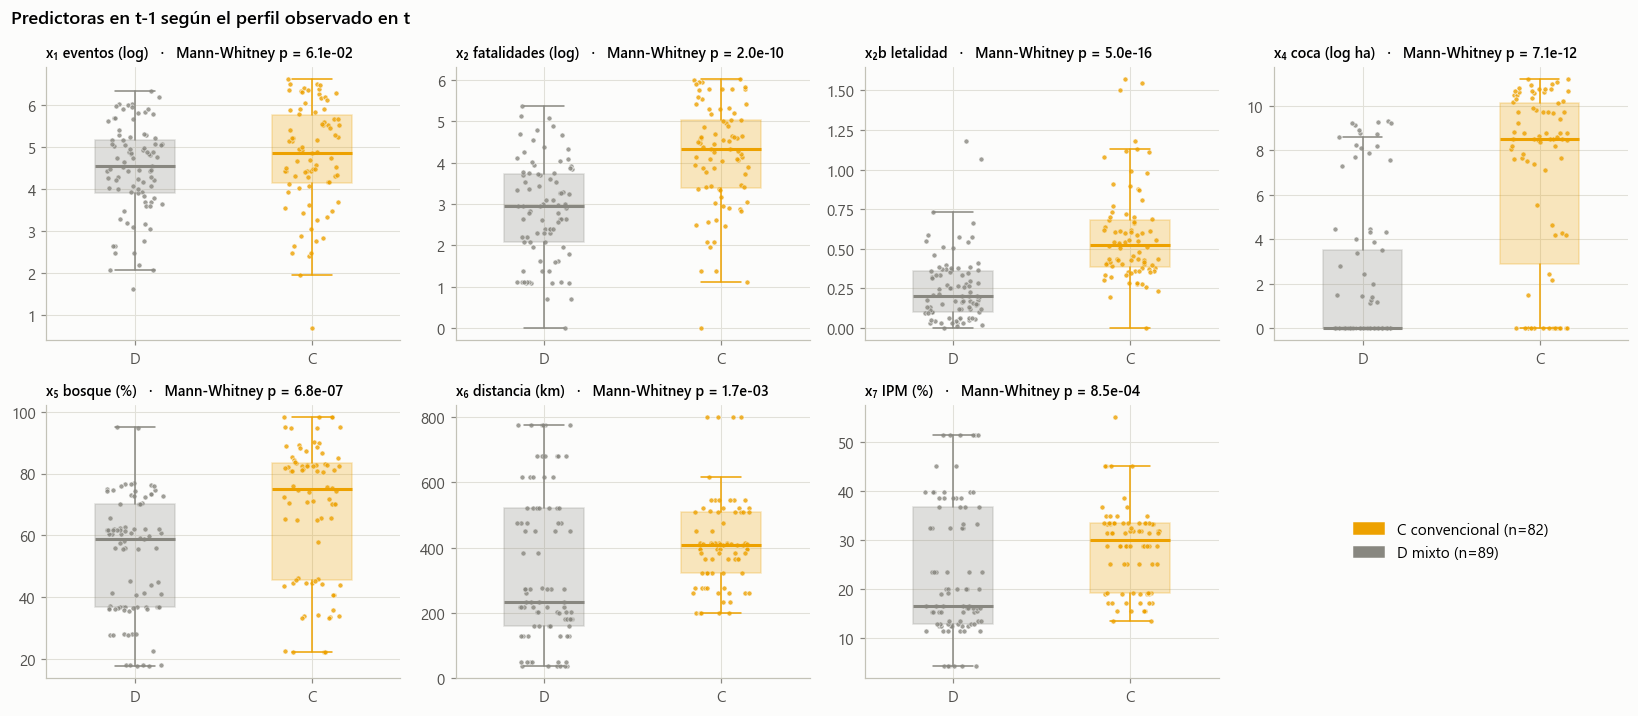

In [14]:
# =============================================================================
# 5.1 Distribución de cada predictora por perfil
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6))
rng_j = np.random.default_rng(SEED)
for ax, f in zip(axes.ravel(), FEATURES):
    for k, (clase, color) in enumerate([(0, COL["D"]), (1, COL["C"])]):
        v = datos.loc[datos.y == clase, f].values
        ax.boxplot(v, positions=[k], widths=0.45, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.25, edgecolor=color), medianprops=dict(color=color, lw=2),
                   whiskerprops=dict(color=color), capprops=dict(color=color))
        ax.scatter(k + rng_j.uniform(-.16, .16, len(v)), v, s=11, color=color, alpha=0.8, edgecolor=FONDO, lw=0.5)
    u = stats.mannwhitneyu(datos.loc[datos.y == 1, f], datos.loc[datos.y == 0, f])
    ax.set_xticks([0, 1], ["D", "C"]); ax.set_title(f"{ETIQ[f]}   ·   Mann-Whitney p = {u.pvalue:.1e}", fontsize=9.5)
ax = axes.ravel()[-1]; ax.axis("off")
ax.legend(handles=[Patch(color=COL["C"], label=f"C convencional (n={int(datos.y.sum())})"),
                   Patch(color=COL["D"], label=f"D mixto (n={int((1 - datos.y).sum())})")], loc="center", fontsize=10)
fig.suptitle("Predictoras en t-1 según el perfil observado en t", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout(); guardar(fig, "fig03_predictoras_por_clase"); plt.show()

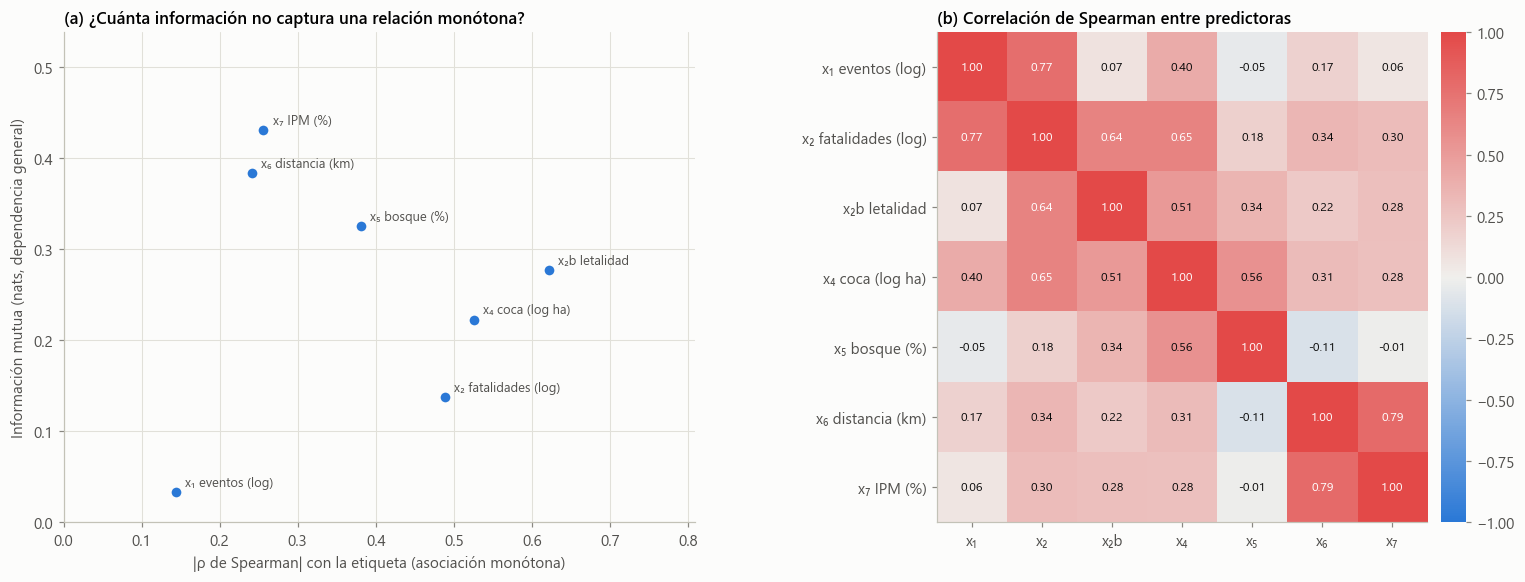

,ρ Spearman con y,Información mutua
x₁ eventos (log),0.144,0.033
x₂ fatalidades (log),0.488,0.138
x₂b letalidad,0.622,0.277
x₄ coca (log ha),0.526,0.223
x₅ bosque (%),0.381,0.326
x₆ distancia (km),0.241,0.384
x₇ IPM (%),0.256,0.431


In [15]:
# =============================================================================
# 5.2 Dependencia lineal/monótona vs. dependencia general, y correlación entre predictoras
# =============================================================================
rho = pd.Series({f: stats.spearmanr(datos[f], datos["y"]).correlation for f in FEATURES})
mi = pd.Series(mutual_info_classif(datos[FEATURES], datos["y"], random_state=SEED, n_neighbors=5), index=FEATURES)
corr = datos[FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.scatter(rho.abs(), mi, s=70, color=COL["mlp"], edgecolor=FONDO, lw=2, zorder=3)
for f in FEATURES:
    ax.annotate(ETIQ[f], (abs(rho[f]), mi[f]), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=TINTA2)
ax.set_xlabel("|ρ de Spearman| con la etiqueta (asociación monótona)")
ax.set_ylabel("Información mutua (nats, dependencia general)")
ax.set_title("(a) ¿Cuánta información no captura una relación monótona?")
ax.set_xlim(0, max(rho.abs()) * 1.3); ax.set_ylim(0, max(mi) * 1.25)

ax = axes[1]
im = ax.imshow(corr.values, cmap=CMAP_DIV, norm=TwoSlopeNorm(0, -1, 1))
ax.set_xticks(range(len(FEATURES)), [ETIQ[f].split(" ")[0] for f in FEATURES])
ax.set_yticks(range(len(FEATURES)), [ETIQ[f] for f in FEATURES])
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.values[i, j]) > .6 else TINTA)
ax.grid(False); ax.set_title("(b) Correlación de Spearman entre predictoras")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
fig.tight_layout(); guardar(fig, "fig04_dependencia_correlacion"); plt.show()
display(pd.DataFrame({"ρ Spearman con y": rho, "Información mutua": mi}).rename(index=ETIQ).round(3))

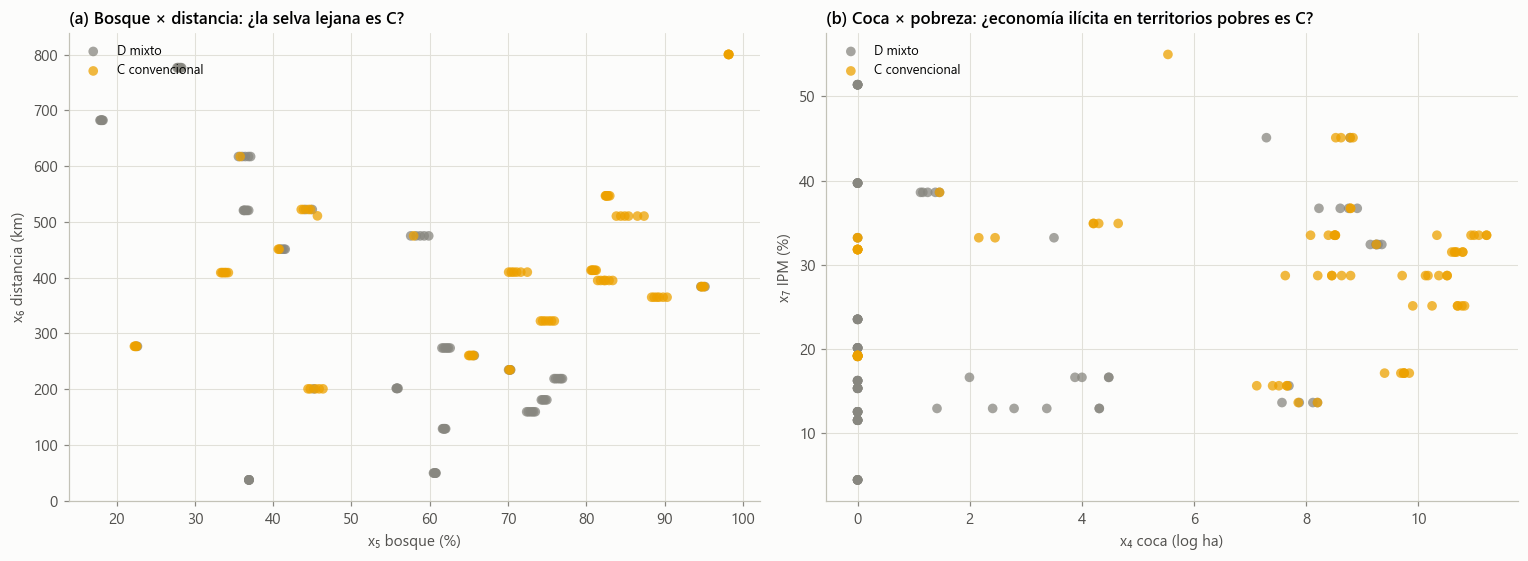

In [16]:
# =============================================================================
# 5.3 Hipótesis de interacción de la Etapa 1 (§6.2): bosque × distancia y coca × pobreza
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
pares = [("x5_bosque", "x6_distancia"), ("x4_coca", "x7_ipm")]
for ax, (fx, fy) in zip(axes, pares):
    for clase, color, et in [(0, COL["D"], "D mixto"), (1, COL["C"], "C convencional")]:
        s = datos[datos.y == clase]
        ax.scatter(s[fx], s[fy], s=40, color=color, edgecolor="none", alpha=0.75, label=et, zorder=3)
    ax.set_xlabel(ETIQ[fx]); ax.set_ylabel(ETIQ[fy]); ax.legend(loc="upper left", fontsize=8.5)
axes[0].set_title("(a) Bosque × distancia: ¿la selva lejana es C?")
axes[1].set_title("(b) Coca × pobreza: ¿economía ilícita en territorios pobres es C?")
fig.tight_layout(); guardar(fig, "fig05_interacciones_hipotesis"); plt.show()

**Lectura del EDA.**

* **Separación univariada.** Seis de las siete predictoras difieren entre perfiles con alta significancia
  (Mann-Whitney, $p < 0{,}01$), en la dirección que anticipaba la Etapa 1. Comparando medianas, los departamentos C
  tienen más del doble de letalidad por evento (0,52 vs. 0,20), coca donde los D casi no tienen (≈5.000 ha vs. 0),
  más bosque (75 % vs. 59 %), están más lejos de Bogotá (409 vs. 235 km) y son más pobres (IPM 30 vs. 17). La
  excepción es $x_1$ (volumen de eventos, $p = 0{,}06$), y coincide con el argumento de la Etapa 1: **el volumen no
  define el perfil**. Bogotá tiene muchos eventos y es D.
* **Indicios de no linealidad.** En el panel (a) de §5.2, $x_6$ (distancia) y $x_7$ (IPM) tienen la mayor
  información mutua (0,38 y 0,43) pero una asociación monótona débil (|ρ| ≈ 0,25). Una parte es no linealidad genuina:
  La Guajira, Sucre y Magdalena son de los departamentos más pobres y alejados y aun así son D todos los años. Otra
  parte es una advertencia: $x_6$ y $x_7$ son **estáticas**, es decir, toman un valor único por departamento, y
  combinadas con una etiqueta muy persistente funcionan casi como un identificador del departamento. Una red puede
  aprovechar eso para memorizar departamentos en lugar de aprender relaciones transferibles. Por eso la validación
  espacial de §11.3, con departamentos nunca vistos, es indispensable.
* **Colinealidad.** Hay pares fuertemente correlacionados: distancia–IPM (ρ = 0,79), eventos–fatalidades (0,77),
  fatalidades–coca (0,65), fatalidades–letalidad (0,64) y coca–bosque (0,56). Esto no impide entrenar, pero vuelve
  inestable la lectura individual de coeficientes lineales, y nos lleva a interpretar con importancia por permutación
  (§11.5) y no con pesos.
* **Interacciones.** En (a), C domina en la zona de "mucho bosque (> 65 %) y lejos (300–550 km)". Pero la frontera no
  es un hiperplano: Arauca es C todos los años con apenas 34 % de bosque y sin coca (conflicto de frontera, no de
  selva), mientras Bolívar, con 59 % de bosque, 475 km y ≈10.000 ha de coca, es D en cinco de seis años. En (b), la coca
  separa bien (casi todos los C tienen > 1.000 ha), pero Valle del Cauca y Bolívar tienen coca y son mayoritariamente D:
  la economía ilícita no basta sin el contexto territorial. La prueba formal de si esa forma aporta está en §11.4.

---
# 6. Protocolo experimental

## 6.1 Partición temporal (sin barajar)

Como el objetivo es **anticipar** el perfil del año siguiente, la partición respeta el tiempo: el modelo se
entrena con el pasado y se evalúa con años que nunca vio. Una partición aleatoria mezclaría filas de 2025 en el
entrenamiento y de 2022 en la prueba, y daría una estimación optimista que no se reproduce en el uso real.

| Conjunto | Años de la etiqueta $t$ | Predictoras $t-1$ | Uso |
|---|---|---|---|
| **Entrenamiento** | 2021–2024 | 2020–2023 | Ajuste de pesos y del escalador |
| **Validación** | 2025 | 2024 | Parada temprana, reducción de la tasa de aprendizaje y umbral de decisión |
| **Prueba** | 2026 (enero–agosto) | 2025 | Evaluación final, una sola vez |

El `StandardScaler` se ajusta **solo con entrenamiento** y se aplica igual a validación y prueba; así ninguna
estadística del futuro entra al modelo. La validación de hiperparámetros (§7.2) usa además **validación cruzada
temporal con origen móvil** (entrenar con años anteriores a $v$ y validar en $v$, para $v$ = 2023, 2024 y 2025),
la variante de validación cruzada que corresponde a datos ordenados en el tiempo (Bergmeir & Benítez, 2012).

,Años (t),Filas,Perfil C,Prevalencia C,Departamentos
Entrenamiento,2021-2024,113,50,"0,44",29
Validación,2025,29,18,"0,62",29
Prueba,2026 (ene-ago),29,14,"0,48",29


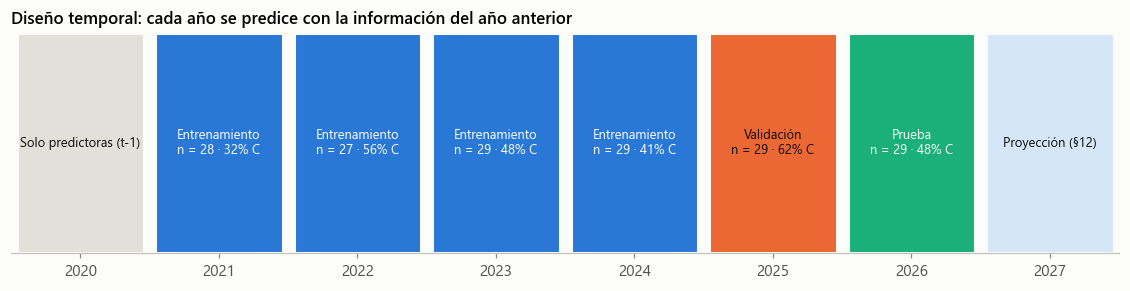

In [17]:
# =============================================================================
# 6.1 Partición temporal y estandarización ajustada solo con entrenamiento
# =============================================================================
ANIOS_TRAIN, ANIO_VAL, ANIO_TEST = [2021, 2022, 2023, 2024], 2025, 2026
m_tr = datos["anio"].isin(ANIOS_TRAIN).values
m_va = (datos["anio"] == ANIO_VAL).values
m_te = (datos["anio"] == ANIO_TEST).values

escalador = StandardScaler().fit(datos.loc[m_tr, FEATURES])
def matriz(mascara, esc=escalador):
    return esc.transform(datos.loc[mascara, FEATURES]).astype("float32")

Xtr, Xva, Xte = matriz(m_tr), matriz(m_va), matriz(m_te)
ytr, yva, yte = (datos.loc[m, "y"].values.astype("float32") for m in (m_tr, m_va, m_te))

particiones = pd.DataFrame({
    "Años (t)": ["2021-2024", "2025", "2026 (ene-ago)"],
    "Filas": [len(ytr), len(yva), len(yte)],
    "Perfil C": [int(ytr.sum()), int(yva.sum()), int(yte.sum())],
    "Prevalencia C": [ytr.mean(), yva.mean(), yte.mean()],
    "Departamentos": [datos.loc[m, "depto"].nunique() for m in (m_tr, m_va, m_te)],
}, index=["Entrenamiento", "Validación", "Prueba"])
tabla(particiones, dec=2)

fig, ax = plt.subplots(figsize=(13, 2.6))
roles = {2020: ("Solo predictoras (t-1)", GRID), 2021: ("Entrenamiento", COL["train"]), 2022: ("Entrenamiento", COL["train"]),
         2023: ("Entrenamiento", COL["train"]), 2024: ("Entrenamiento", COL["train"]), 2025: ("Validación", COL["val"]),
         2026: ("Prueba", COL["test"]), 2027: ("Proyección (§12)", "#d6e6f9")}
for anio, (rol, color) in roles.items():
    ax.add_patch(Rectangle((anio - .46, 0), .92, 1, facecolor=color, edgecolor=FONDO, lw=2))
    sub = datos[datos.anio == anio]
    txt = f"{rol}\nn = {len(sub)} · {sub.y.mean():.0%} C" if len(sub) else rol
    ax.text(anio, .5, txt, ha="center", va="center", fontsize=8.5,
            color="white" if color in (COL["train"], COL["test"]) else TINTA)
ax.set_xlim(2019.5, 2027.5); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False)
ax.set_xticks(range(2020, 2028)); ax.spines["left"].set_visible(False)
ax.set_title("Diseño temporal: cada año se predice con la información del año anterior")
guardar(fig, "fig06_particion_temporal"); plt.show()

## 6.2 Líneas base

Una métrica solo se puede interpretar frente a una referencia. Comparamos la red contra tres líneas base de
complejidad creciente:

| Línea base | Regla | Qué mide |
|---|---|---|
| **Clase mayoritaria** | Predice siempre la clase más frecuente en entrenamiento (D) | El piso: cualquier modelo útil debe superarla |
| **Persistencia** | $\hat{p}_{d,t} = s^{C}_{d,t-1}$: el perfil del año pasado se repite | La inercia del conflicto. Es la línea base que ya usa, en la práctica, un planificador sin modelo |
| **Regresión logística** | $\hat{p} = \sigma(\mathbf{w}^\top\mathbf{x} + b)$ con las mismas 7 predictoras | El modelo lineal que la Etapa 1 (§6.3) prometió comparar contra la red: *una sola neurona* |

La regresión logística recibe el mismo trato que la red: mismas predictoras, mismo escalado, pesos de clase
balanceados, y su hiperparámetro de regularización $C$ se elige con la misma validación cruzada temporal.

In [18]:
# =============================================================================
# 6.2 Líneas base: mayoritaria, persistencia y regresión logística (una neurona)
# =============================================================================
prev_train = float(ytr.mean())

def score_persistencia(mascara):
    """Probabilidad de C = proporción de eventos C del año anterior (prevalencia de entrenamiento si no hubo eventos)."""
    s = datos.loc[mascara, "s_C_prev"].values.astype(float)
    return np.where(np.isnan(s), prev_train, s)

def folds_temporales(anios_val=(2023, 2024, 2025), columnas=None):
    """Validación cruzada de origen móvil: entrena con años < v y valida en v (escalador por pliegue)."""
    columnas = columnas or FEATURES
    for v in anios_val:
        tr, va = (datos["anio"] < v).values, (datos["anio"] == v).values
        esc = StandardScaler().fit(datos.loc[tr, columnas])
        yield (v, esc.transform(datos.loc[tr, columnas]).astype("float32"), datos.loc[tr, "y"].values.astype("float32"),
               esc.transform(datos.loc[va, columnas]).astype("float32"), datos.loc[va, "y"].values.astype("float32"))

FOLDS_CV = list(folds_temporales())

# Selección de C (inverso de la regularización L2) de la logística con la misma validación temporal
C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
cv_logit = pd.DataFrame([{"C": c, "anio_val": v,
                          "BCE": bce(yv, LogisticRegression(C=c, class_weight="balanced", max_iter=5000)
                                     .fit(Xa, ya).predict_proba(Xv)[:, 1])}
                         for c in C_GRID for v, Xa, ya, Xv, yv in FOLDS_CV])
C_LR = float(cv_logit.groupby("C")["BCE"].mean().idxmin())
logit = LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000).fit(Xtr, ytr)
print(f"C elegido para la logística (menor BCE media en validación temporal): {C_LR}")
print(cv_logit.groupby("C")["BCE"].mean().round(4).to_string())

signo_u1 = {"x1_eventos": "±", "x2_fatalidades": "+", "x2b_letalidad": "+", "x4_coca": "+",
            "x5_bosque": "+", "x6_distancia": "+", "x7_ipm": "+"}
coef = pd.DataFrame({"Coeficiente (por 1 DE)": logit.coef_.ravel(), "Razón de odds": np.exp(logit.coef_.ravel()),
                     "Signo esperado (U1)": [signo_u1[f] for f in FEATURES]}, index=[ETIQ[f] for f in FEATURES])
coef["¿Coincide?"] = [("—" if e == "±" else ("sí" if np.sign(c) == (1 if e == "+" else -1) else "no"))
                      for c, e in zip(coef.iloc[:, 0], coef.iloc[:, 2])]
tabla(coef, dec=3)

C elegido para la logística (menor BCE media en validación temporal): 3.0
C
0.01     0.5714
0.03     0.5029
0.10     0.4506
0.30     0.4256
1.00     0.4146
3.00     0.4124
10.00    0.4141


,Coeficiente (por 1 DE),Razón de odds,Signo esperado (U1),¿Coincide?
x₁ eventos (log),"-1,779","0,169",±,—
x₂ fatalidades (log),"2,554","12,862",+,sí
x₂b letalidad,"0,339","1,404",+,sí
x₄ coca (log ha),"0,133","1,142",+,sí
x₅ bosque (%),"0,620","1,859",+,sí
x₆ distancia (km),"0,477","1,612",+,sí
x₇ IPM (%),"-0,204","0,815",+,no


**Lectura de la línea base lineal.** Los coeficientes estandarizados son la versión lineal de las hipótesis de la
Etapa 1: un coeficiente positivo aumenta la probabilidad de perfil C.

* Cinco de las seis hipótesis direccionales se cumplen (fatalidades, letalidad, coca, bosque y distancia empujan hacia
  C), así que la formulación del problema está bien orientada.
* $x_1$ y $x_2$ salen con signos opuestos y magnitudes grandes (−1,78 y +2,55). Juntos codifican una **razón**: a
  igualdad de fatalidades, más eventos significa más protesta y, por tanto, perfil D. La logística solo puede
  representar esa interacción multiplicativa como una resta de logaritmos, de ahí los coeficientes grandes.
* $x_7$ (IPM) sale **negativo**, contrario a la hipótesis U1. No quiere decir que la pobreza reduzca la amenaza
  convencional: es la colinealidad con la distancia (ρ = 0,79), que hace que la logística reparta el efecto entre las
  dos y le asigne signos arbitrarios. §11.4 muestra que la red recupera el efecto esperado.
* La $C$ elegida (3,0) implica una regularización débil: el modelo lineal no está sobreajustando, está limitado por
  su forma.

---
# 7. Arquitectura y configuración del modelo base

## 7.1 Decisiones de diseño

El modelo base es un **perceptrón multicapa (MLP) totalmente conectado** implementado con la API funcional de
Keras, tal como se anunció en la Etapa 1. Con datos tabulares de 7 variables numéricas y sin estructura espacial ni
secuencial explícita, un MLP es la arquitectura neuronal adecuada. Las redes convolucionales o recurrentes
suponen estructuras (rejillas, secuencias largas) que este panel no tiene.

| Componente | Elección | Justificación técnica |
|---|---|---|
| **Entrada** | 7 neuronas ($x_1, x_2, x_{2b}, x_4, x_5, x_6, x_7$) estandarizadas | Determinada por las variables de la Etapa 1. La estandarización equilibra las escalas para que ninguna variable domine el gradiente |
| **Capas ocultas** | Seleccionadas por validación cruzada temporal (§7.2) | Con $n \approx 113$ filas de entrenamiento la capacidad debe ser pequeña; la búsqueda compara 1 y 2 capas y 8–32 neuronas |
| **Activación oculta** | ReLU, $\phi(z) = \max(0, z)$ | Derivada 1 en la región activa: no satura ni desvanece el gradiente como la logística (derivada máx. 0,25), como vimos en la Actividad 3 |
| **Inicialización** | He normal, $\mathcal{N}(0, 2/n_{in})$ | Conserva la varianza de las activaciones a través de capas ReLU (He et al., 2015) |
| **Salida** | 1 neurona sigmoide | Produce $\hat{p} = P(\text{C})\in(0,1)$, una probabilidad y no solo una etiqueta, útil para priorizar territorios |
| **Pérdida** | Entropía cruzada binaria ponderada por clase + penalización L2 | Es la log-verosimilitud negativa de un modelo Bernoulli (Goodfellow et al., 2016); los pesos de clase compensan el leve desbalance (44 % C en entrenamiento) |
| **Regularización** | L2 sobre los pesos y *dropout* entre capas (seleccionados en §7.2) | Con ≈1–3 parámetros por observación el riesgo de sobreajuste es alto (Srivastava et al., 2014) |
| **Optimizador** | Adam, $\eta_0 = 10^{-3}$, lotes de 16 | Tasa adaptativa por parámetro, robusta con gradientes ruidosos de lotes pequeños (Kingma & Ba, 2015). El lote de 16 da ≈8 actualizaciones por época |
| **Control del entrenamiento** | Parada temprana (paciencia 80, se restauran los mejores pesos) + reducción de $\eta$ a la mitad tras 30 épocas sin mejora | Detiene el ajuste en el mínimo de la pérdida de validación (Prechelt, 1998) y afina la convergencia cerca del óptimo |

**Formulación.** Para una red con capas ocultas $h^{(1)}, \dots, h^{(L)}$:

$$
\mathbf{h}^{(\ell)} = \mathrm{ReLU}\left(\mathbf{W}^{(\ell)}\,\mathbf{h}^{(\ell-1)} + \mathbf{b}^{(\ell)}\right),\qquad
\hat{p} = \sigma\left(\mathbf{w}_{o}^{\top}\mathbf{h}^{(L)} + b_o\right),
$$

$$
\mathcal{L}(\boldsymbol\theta) = -\frac{1}{n}\sum_{i=1}^{n} \omega_{y_i}\left[y_i\log\hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\right] + \lambda\sum_{\ell}\left\lVert\mathbf{W}^{(\ell)}\right\rVert_2^2,
\qquad \omega_c = \frac{n}{2\,n_c}.
$$

In [19]:
# =============================================================================
# 7.1 Configuración y constructor del modelo (Keras, API funcional)
# =============================================================================
@dataclass(frozen=True)
class ConfigMLP:
    capas: tuple = (16, 8)       # neuronas por capa oculta
    l2: float = 1e-3             # penalización L2 (λ)
    dropout: float = 0.2         # tasa de dropout tras cada capa oculta
    lr: float = 1e-3             # tasa de aprendizaje inicial de Adam
    batch: int = 16              # tamaño de lote
    epocas_max: int = 800        # tope de épocas (la parada temprana actúa antes)
    paciencia: int = 80          # épocas sin mejora en validación antes de detener
    paciencia_lr: int = 30       # épocas sin mejora antes de reducir la tasa de aprendizaje
    factor_lr: float = 0.5       # factor de reducción de la tasa de aprendizaje
    lr_min: float = 1e-5         # tasa de aprendizaje mínima
    min_delta: float = 1e-4      # mejora mínima que cuenta como mejora

def construir_mlp(n_x, cfg):
    """MLP: entrada -> [Dense(ReLU, He, L2) -> Dropout] x L -> Dense(1, sigmoide)."""
    reg = keras.regularizers.L2(cfg.l2) if cfg.l2 > 0 else None
    entrada = keras.Input(shape=(n_x,), name="entrada_x_t_1")
    h = entrada
    for i, unidades in enumerate(cfg.capas, 1):
        h = layers.Dense(unidades, activation="relu", kernel_initializer="he_normal",
                         kernel_regularizer=reg, name=f"oculta_{i}")(h)
        if cfg.dropout > 0:
            h = layers.Dropout(cfg.dropout, name=f"dropout_{i}")(h)
    salida = layers.Dense(1, activation="sigmoid", name="salida_P_C")(h)
    return keras.Model(entrada, salida, name="MLP_perfil_amenaza")

def n_parametros(capas, n_x=len(FEATURES)):
    dims = [n_x, *capas, 1]
    return int(sum(a * b + b for a, b in zip(dims[:-1], dims[1:])))

## 7.2 Selección de capacidad y regularización por validación cruzada temporal

No fijamos la arquitectura a ojo. Buscamos en una rejilla pequeña y justificada el balance entre capacidad
(neuronas y capas) y regularización (L2 y dropout): cada configuración se entrena en los tres pliegues temporales
(validando en 2023, 2024 y 2025) con dos semillas, y se mide la **entropía cruzada de validación**. Usamos la
entropía cruzada y no la exactitud porque evalúa la probabilidad completa, no solo el lado del umbral en que cae.

Para elegir aplicamos la **regla de un error estándar** (Hastie et al., 2009): entre las configuraciones cuyo error
medio no supera al mejor en más de un error estándar, se escoge la de **menos parámetros**. Con muestras pequeñas,
diferencias menores que el ruido entre semillas y pliegues no justifican una red más grande.

El conjunto de prueba (2026) no participa en esta búsqueda.

In [20]:
# =============================================================================
# 7.2 Bucle de entrenamiento (se define aquí porque la búsqueda lo usa; se explica en §8)
# =============================================================================
def entrenar_mlp(Xtr_, ytr_, Xva_=None, yva_=None, cfg=None, semilla=SEED, epocas=None,
                 calendario_lr=None, pesos_clase=True, diagnostico=True):
    """
    Entrena el MLP con un bucle explícito (tf.GradientTape); cada época completa corre dentro de un tf.function.
    - Con validación y sin `epocas`: parada temprana + reducción de LR en meseta; restaura los mejores pesos.
    - Con `epocas` (y opcionalmente `calendario_lr`): número fijo de épocas (reajustes y validaciones cruzadas).
    Devuelve: modelo, historial por época, resumen y función de predicción (inferencia, sin dropout).
    """
    cfg = cfg or CFG
    keras.utils.set_random_seed(semilla)
    rng = np.random.default_rng(semilla)
    Xtr_ = np.asarray(Xtr_, "float32"); ytr_ = np.asarray(ytr_, "float32").reshape(-1, 1)
    n, d, B = len(ytr_), Xtr_.shape[1], cfg.batch
    n_lotes = math.ceil(n / B)
    modelo = construir_mlp(d, cfg)
    opt = keras.optimizers.Adam(learning_rate=cfg.lr)
    opt.build(modelo.trainable_variables)                     # variables de Adam creadas antes del grafo
    perdida_bce = keras.losses.BinaryCrossentropy()
    n1 = float(ytr_.sum())
    w = (np.where(ytr_.ravel() == 1, n / (2 * n1), n / (2 * (n - n1))) if pesos_clase else np.ones(n)).astype("float32")

    @tf.function(input_signature=(tf.TensorSpec([None, d], tf.float32), tf.TensorSpec([None, 1], tf.float32),
                                  tf.TensorSpec([None], tf.float32)))
    def epoca(Xp, yp, wp):
        """Una época: recorre los lotes de 16 y aplica un paso de Adam por lote."""
        perdidas = tf.TensorArray(tf.float32, size=n_lotes)
        normas = tf.TensorArray(tf.float32, size=n_lotes)
        for i in tf.range(n_lotes):
            xb, yb, wb = Xp[i * B:(i + 1) * B], yp[i * B:(i + 1) * B], wp[i * B:(i + 1) * B]
            with tf.GradientTape() as cinta:
                p = modelo(xb, training=True)                             # propagación hacia adelante (dropout activo)
                perdida = perdida_bce(yb, p, sample_weight=wb)            # BCE ponderada por clase
                if modelo.losses:
                    perdida = perdida + tf.add_n(modelo.losses)           # + λ·||W||²
            grads = cinta.gradient(perdida, modelo.trainable_variables)   # retropropagación
            opt.apply_gradients(zip(grads, modelo.trainable_variables))   # actualización Adam
            tam = tf.cast(tf.shape(xb)[0], tf.float32)                      # promedio ponderado por tamaño de lote
            perdidas = perdidas.write(i, perdida * tam)
            normas = normas.write(i, tf.linalg.global_norm(grads) * tam)
        return tf.reduce_sum(perdidas.stack()) / n, tf.reduce_sum(normas.stack()) / n

    @tf.function(input_signature=(tf.TensorSpec([None, d], tf.float32),))
    def predecir(x):
        return modelo(x, training=False)                                  # inferencia (sin dropout)

    con_val = Xva_ is not None
    parada = con_val and epocas is None
    if con_val:
        Xva_ = np.asarray(Xva_, "float32"); yv = np.asarray(yva_, "float32").ravel()
    kernels = [c.kernel for c in modelo.layers if hasattr(c, "kernel")]
    H = {k: [] for k in ["epoca", "lr", "perdida_obj", "norma_grad", "bce_tr", "bce_va", "acc_tr", "acc_va",
                         "auc_tr", "auc_va", "ratio_act"]}
    mejor, mejor_ep, mejores_pesos, espera, espera_lr = np.inf, 0, None, 0, 0
    for ep in range(1, (epocas or cfg.epocas_max) + 1):
        if calendario_lr is not None:
            opt.learning_rate.assign(float(calendario_lr[min(ep - 1, len(calendario_lr) - 1)]))
        antes = [k.numpy().copy() for k in kernels] if diagnostico else None
        orden = rng.permutation(n)                                        # barajado por época
        l, g = epoca(Xtr_[orden], ytr_[orden], w[orden])
        if not (diagnostico or parada):
            continue
        H["epoca"].append(ep); H["lr"].append(float(keras.ops.convert_to_numpy(opt.learning_rate)))
        H["perdida_obj"].append(float(l)); H["norma_grad"].append(float(g))
        if diagnostico:
            p_tr = predecir(Xtr_).numpy().ravel()
            H["bce_tr"].append(bce(ytr_.ravel(), p_tr)); H["acc_tr"].append(float(((p_tr >= .5) == ytr_.ravel()).mean()))
            H["auc_tr"].append(roc_auc_score(ytr_.ravel(), p_tr))
            H["ratio_act"].append([float(np.linalg.norm(k.numpy() - a) / (np.linalg.norm(a) + 1e-12))
                                   for k, a in zip(kernels, antes)])
        if con_val:
            p_va = predecir(Xva_).numpy().ravel()
            H["bce_va"].append(bce(yv, p_va))
            if diagnostico:
                H["acc_va"].append(float(((p_va >= .5) == yv).mean()))
                H["auc_va"].append(roc_auc_score(yv, p_va) if len(np.unique(yv)) > 1 else np.nan)
        if parada:
            if H["bce_va"][-1] < mejor - cfg.min_delta:
                mejor, mejor_ep, mejores_pesos, espera, espera_lr = H["bce_va"][-1], ep, modelo.get_weights(), 0, 0
            else:
                espera += 1; espera_lr += 1
                if espera_lr >= cfg.paciencia_lr and calendario_lr is None:
                    opt.learning_rate.assign(max(H["lr"][-1] * cfg.factor_lr, cfg.lr_min)); espera_lr = 0
                if espera >= cfg.paciencia:
                    break
    if parada and mejores_pesos is not None:
        modelo.set_weights(mejores_pesos)
    info = {"mejor_epoca": mejor_ep if parada else ep, "epocas_ejecutadas": ep,
            "mejor_bce_val": mejor if parada else np.nan,
            "calendario_lr": H["lr"][:mejor_ep] if parada else H["lr"]}
    return modelo, H, info, lambda X: predecir(np.asarray(X, "float32")).numpy().ravel()

In [21]:
# =============================================================================
# 7.3 Búsqueda de capacidad y regularización (3 pliegues temporales × 2 semillas)
# =============================================================================
REJILLA = [(capas, l2, do) for capas in [(8,), (16,), (16, 8), (32, 16)] for l2 in [1e-3, 1e-2] for do in [0.0, 0.2]]
SEMILLAS_BUSQUEDA = [1, 2]
t0, filas = time.time(), []
for capas, l2, do in REJILLA:
    cfg_i = ConfigMLP(capas=capas, l2=l2, dropout=do)
    for v, Xa, ya, Xv, yv in FOLDS_CV:
        for s in SEMILLAS_BUSQUEDA:
            _, _, inf, pred = entrenar_mlp(Xa, ya, Xv, yv, cfg=cfg_i, semilla=s, diagnostico=False)
            pv = pred(Xv)
            filas.append({"capas": str(capas), "L2": l2, "dropout": do, "anio_val": v, "semilla": s,
                          "BCE_val": bce(yv, pv), "AUC_val": roc_auc_score(yv, pv), "mejor_epoca": inf["mejor_epoca"]})
busqueda = pd.DataFrame(filas)
print(f"{len(busqueda)} entrenamientos en {time.time() - t0:.0f} s")

res_busq = (busqueda.groupby(["capas", "L2", "dropout"])
            .agg(BCE_media=("BCE_val", "mean"), BCE_ee=("BCE_val", lambda s: s.std(ddof=1) / np.sqrt(len(s))),
                 AUC_media=("AUC_val", "mean"), epoca_mediana=("mejor_epoca", "median"))
            .reset_index())
res_busq["parámetros"] = res_busq["capas"].map(lambda c: n_parametros(eval(c)))
res_busq = res_busq.sort_values("BCE_media").reset_index(drop=True)
mejor = res_busq.iloc[0]
candidatas = res_busq[res_busq["BCE_media"] <= mejor["BCE_media"] + mejor["BCE_ee"]]
elegida = candidatas.sort_values(["parámetros", "BCE_media"]).iloc[0]
CFG = ConfigMLP(capas=eval(elegida["capas"]), l2=float(elegida["L2"]), dropout=float(elegida["dropout"]))
tabla(res_busq, dec=4)
print(f"\nMejor BCE media: {mejor['capas']} L2={mejor['L2']} dropout={mejor['dropout']} -> {mejor['BCE_media']:.4f} ± {mejor['BCE_ee']:.4f}")
print(f"Configuraciones dentro de 1 EE del mejor: {len(candidatas)}")
print(f"ELEGIDA (regla 1-EE, menos parámetros): {CFG}")

96 entrenamientos en 120 s


,capas,L2,dropout,BCE_media,BCE_ee,AUC_media,epoca_mediana,parámetros
0,"(32, 16)","0,0010","0,0000","0,2848","0,0343","0,9717","83,0000",801
1,"(32, 16)","0,0100","0,0000","0,2965","0,0290","0,9710","164,5000",801
2,"(16, 8)","0,0010","0,0000","0,3142","0,0296","0,9546","207,5000",273
3,"(16, 8)","0,0100","0,0000","0,3143","0,0293","0,9578","276,0000",273
4,"(16,)","0,0010","0,0000","0,3160","0,0368","0,9654","298,5000",145
5,"(32, 16)","0,0010","0,2000","0,3182","0,0394","0,9565","131,0000",801
6,"(8,)","0,0010","0,0000","0,3239","0,0254","0,9638","501,5000",73
7,"(32, 16)","0,0100","0,2000","0,3260","0,0333","0,9606","142,5000",801
8,"(16,)","0,0100","0,0000","0,3276","0,0335","0,9646","460,0000",145
9,"(16,)","0,0010","0,2000","0,3293","0,0254","0,9546","308,0000",145



Mejor BCE media: (32, 16) L2=0.001 dropout=0.0 -> 0.2848 ± 0.0343
Configuraciones dentro de 1 EE del mejor: 6
ELEGIDA (regla 1-EE, menos parámetros): ConfigMLP(capas=(16,), l2=0.001, dropout=0.0, lr=0.001, batch=16, epocas_max=800, paciencia=80, paciencia_lr=30, factor_lr=0.5, lr_min=1e-05, min_delta=0.0001)


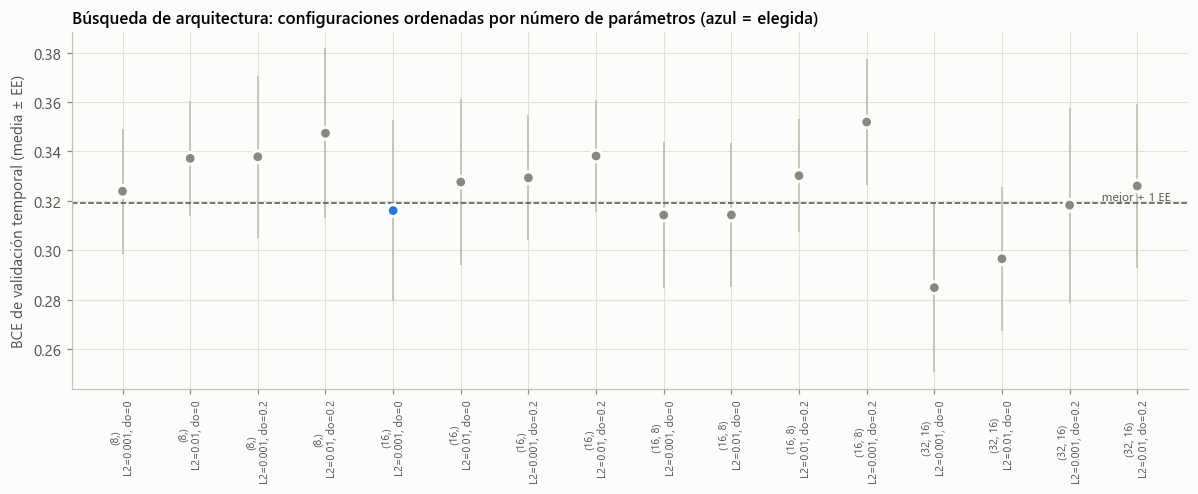

In [22]:
# =============================================================================
# 7.4 Visualización de la búsqueda: capacidad vs. regularización
# =============================================================================
fig, ax = plt.subplots(figsize=(11, 4.6))
etiquetas = [f"{c}\nL2={l:g}, do={d:g}" for c, l, d in zip(res_busq.capas, res_busq.L2, res_busq.dropout)]
orden = np.argsort(res_busq["parámetros"].values * 10 + res_busq["BCE_media"].values)
ys = res_busq["BCE_media"].values[orden]; es = res_busq["BCE_ee"].values[orden]
colores = [COL["mlp"] if (res_busq.capas.values[i] == str(CFG.capas) and res_busq.L2.values[i] == CFG.l2
                          and res_busq.dropout.values[i] == CFG.dropout) else COL["D"] for i in orden]
ax.errorbar(range(len(ys)), ys, yerr=es, fmt="none", ecolor=EJE, elinewidth=1.2, capsize=0)
ax.scatter(range(len(ys)), ys, s=60, c=colores, edgecolor=FONDO, lw=2, zorder=3)
ax.axhline(mejor["BCE_media"] + mejor["BCE_ee"], color=TINTA2, lw=1, ls="--")
ax.text(len(ys) - .5, mejor["BCE_media"] + mejor["BCE_ee"], "  mejor + 1 EE", va="bottom", ha="right", fontsize=8, color=TINTA2)
ax.set_xticks(range(len(ys)), [etiquetas[i] for i in orden], fontsize=7, rotation=90)
ax.set_ylabel("BCE de validación temporal (media ± EE)")
ax.set_title("Búsqueda de arquitectura: configuraciones ordenadas por número de parámetros (azul = elegida)")
fig.tight_layout(); guardar(fig, "fig07_busqueda_hiperparametros"); plt.show()

**Lectura de la búsqueda.**

* La mejor BCE media la obtuvo la red más grande, (32, 16) con L2 = 10⁻³ y sin dropout (0,285 ± 0,034). Pero
  **seis configuraciones** quedan dentro de un error estándar de ella: las diferencias entre capacidades son del
  mismo orden que la variación entre pliegues y semillas.
* La regla de 1 EE elige la más simple de ese grupo: **una capa oculta de 16 neuronas ReLU, L2 = 10⁻³, sin dropout
  (145 parámetros)**, con BCE 0,316 ± 0,037, frente a los 801 parámetros de la mejor. Con 113 filas de entrenamiento
  eso son 1,3 parámetros por observación en lugar de 7.
* Una sola capa oculta basta en teoría. Por el teorema de aproximación universal (Hornik, 1991), el mismo argumento
  que la Etapa 1 citó a partir de Bishop & Bishop (2024), una capa oculta suficientemente ancha puede aproximar
  cualquier frontera continua. La profundidad adicional no mostró ventaja estadística con estos datos.
* **El dropout empeoró la BCE en las 8 comparaciones pareadas** (misma capacidad y L2). En redes tan pequeñas,
  apagar el 20 % de 8–32 neuronas quita capacidad útil en lugar de evitar coadaptaciones. La regularización efectiva
  viene del L2 y, sobre todo, de la parada temprana (§11.3d).
* Todas las configuraciones superan a la regresión logística en esta misma validación cruzada (BCE media 0,412 con
  su mejor $C$). Es una primera señal a favor de la red, que §11.4 somete a prueba formal.

In [23]:
# =============================================================================
# 7.5 Modelo base final: resumen de Keras y conteo de parámetros
# =============================================================================
modelo_demo = construir_mlp(len(FEATURES), CFG)
modelo_demo.summary()
n_par = n_parametros(CFG.capas)
print(f"\nParámetros entrenables: {n_par} | Filas de entrenamiento: {len(ytr)} | "
      f"Parámetros por observación: {n_par / len(ytr):.2f}")
tabla(pd.DataFrame(asdict(CFG).items(), columns=["Hiperparámetro", "Valor"]).astype(str).set_index("Hiperparámetro"))

Model: "MLP_perfil_amenaza"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_x_t_1 (InputLayer)      │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_P_C (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 145 (580.00 B)

 Trainable params: 145 (580.00 B)

 Non-trainable params: 0 (0.00 B)


Parámetros entrenables: 145 | Filas de entrenamiento: 113 | Parámetros por observación: 1.28


,Valor
Hiperparámetro,
capas,"(16,)"
l2,0.001
dropout,0.0
lr,0.001
batch,16
epocas_max,800
paciencia,80
paciencia_lr,30
factor_lr,0.5


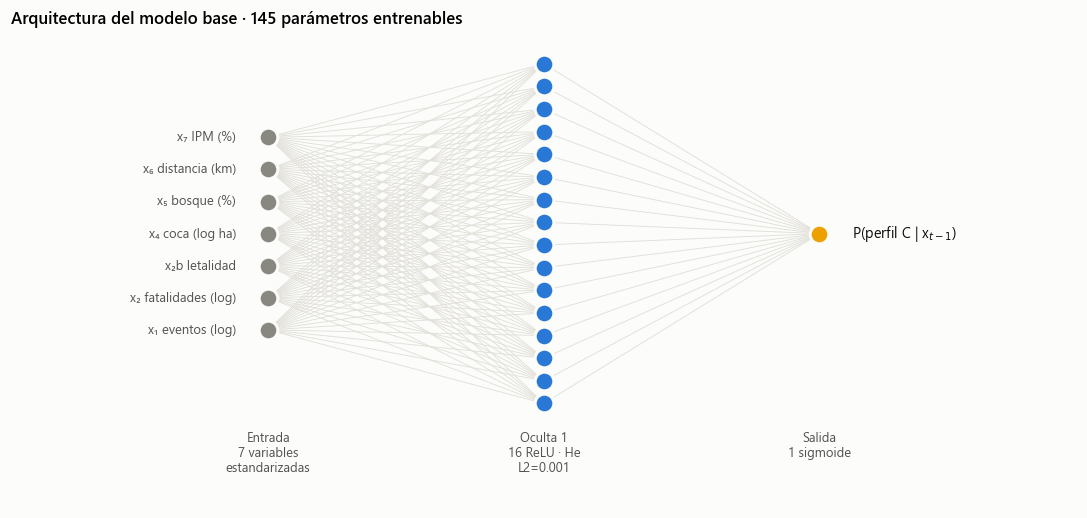

In [24]:
# =============================================================================
# 7.6 Esquema de la arquitectura
# =============================================================================
def dibujar_arquitectura(cfg, nombres_entrada):
    tam = [len(nombres_entrada), *cfg.capas, 1]
    fig, ax = plt.subplots(figsize=(12.5, 5.6)); ax.axis("off"); ax.grid(False)
    xs = np.arange(len(tam)) * 3.0
    pos = [[(x, y) for y in np.linspace(-(n - 1) / 2, (n - 1) / 2, n) * min(0.62, 7.0 / max(n, 1))] for x, n in zip(xs, tam)]
    for a, b in zip(pos[:-1], pos[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b:
                ax.plot([x1, x2], [y1, y2], color=GRID, lw=0.6, zorder=1)
    col_capa = [COL["D"]] + [COL["mlp"]] * len(cfg.capas) + [COL["C"]]
    for k, (capa, color) in enumerate(zip(pos, col_capa)):
        for (x, y) in capa:
            ax.scatter(x, y, s=150 if len(capa) <= 16 else 90, color=color, edgecolor=FONDO, lw=2, zorder=3)
    for (x, y), nombre in zip(pos[0], nombres_entrada):
        ax.text(x - 0.35, y, nombre, ha="right", va="center", fontsize=8.5, color=TINTA2)
    ax.text(pos[-1][0][0] + 0.35, 0, "P(perfil C | x$_{t-1}$)", ha="left", va="center", fontsize=9.5, color=TINTA)
    desc = ["Entrada\n7 variables\nestandarizadas"]
    for i, u in enumerate(cfg.capas, 1):
        desc.append(f"Oculta {i}\n{u} ReLU · He\nL2={cfg.l2:g}" + (f"\nDropout {cfg.dropout:g}" if cfg.dropout else ""))
    desc.append("Salida\n1 sigmoide")
    top = max(max(abs(y) for _, y in c) for c in pos)
    for x, d in zip(xs, desc):
        ax.text(x, -top - 0.55, d, ha="center", va="top", fontsize=8.5, color=TINTA2)
    ax.set_title(f"Arquitectura del modelo base · {n_parametros(cfg.capas)} parámetros entrenables", loc="left")
    ax.set_xlim(xs[0] - 2.8, xs[-1] + 2.8); ax.set_ylim(-top - 2.0, top + 0.6)
    return fig

fig = dibujar_arquitectura(CFG, [ETIQ[f] for f in FEATURES]); guardar(fig, "fig08_arquitectura"); plt.show()

---
# 8. Entrenamiento del modelo base

## 8.1 Bucle de entrenamiento explícito

En lugar de `model.fit` usamos un **bucle de entrenamiento explícito** con `tf.GradientTape` (definido en §7.2) sobre el
mismo modelo de Keras. Lo hicimos por dos razones:

1. **Diagnóstico.** En cada época registra señales que `fit` no expone: la norma global del gradiente, la razón de
   actualización de los pesos $\lVert \Delta\mathbf{W}\rVert / \lVert\mathbf{W}\rVert$ por capa, y las curvas
   "limpias" de entropía cruzada en modo inferencia (sin dropout ni penalización), que se pueden comparar directamente
   entre entrenamiento y validación.
2. **Costo.** Con 113 filas, `fit` gasta más tiempo en su maquinaria interna que en el cálculo, y el bucle, que
   corre cada época completa dentro de un grafo compilado (`tf.function`), es varias veces más rápido (medición en
   §8.2). Eso hace viables los más de 300 entrenamientos de la búsqueda (§7) y de los análisis de estabilidad,
   generalización y mejora (§11–§13).

Cada época: (1) baraja las filas, (2) recorre lotes de 16 y, en cada uno, calcula la pérdida ponderada (con dropout
activo si la configuración lo incluye), obtiene el gradiente por retropropagación y actualiza con Adam, (3) evalúa
entrenamiento y validación en modo inferencia, (4) aplica las reglas de parada temprana y de reducción de la tasa de
aprendizaje.

## 8.2 Verificación del bucle contra `model.fit`

Antes de usar el bucle comprobamos que implementa exactamente el mismo algoritmo que la API estándar. Para que la
comparación sea exacta eliminamos la única fuente de diferencia legítima, el orden aleatorio de los lotes: entrenamos
con **lote completo** (las 113 filas en cada paso), los mismos pesos iniciales y el mismo número de épocas. Si ambas
implementaciones son equivalentes, las trayectorias de pérdida y las predicciones deben coincidir hasta el error de
redondeo en punto flotante.

,model.fit,Bucle explícito
Pérdida optimizada en la última época,"0,4499","0,4499"
BCE validación,"0,4839","0,4839"
AUC validación,"0,9242","0,9242"
Milisegundos por época,"28,7655","7,1178"


Diferencia máxima entre las dos curvas de pérdida (150 épocas): 2.1e-06
Diferencia máxima entre las probabilidades predichas en validación: 5.0e-05


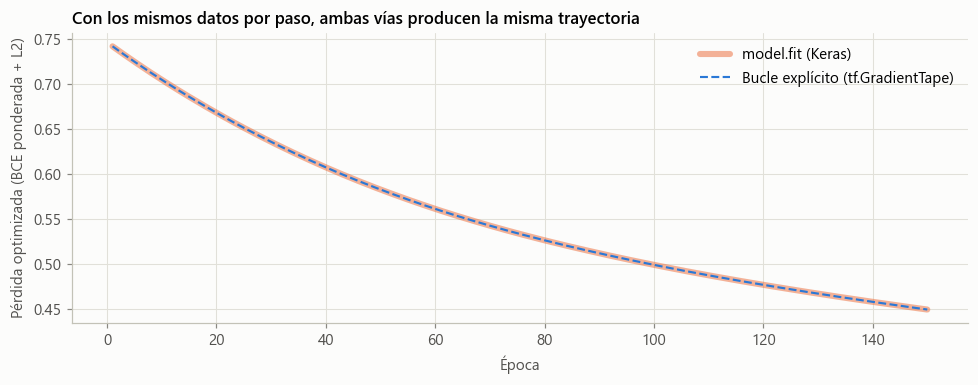

In [25]:
# =============================================================================
# 8.2 Verificación: bucle explícito vs. model.fit con lote completo (sin aleatoriedad de barajado)
# =============================================================================
EPOCAS_CHK = 150
cfg_chk = replace(CFG, batch=len(ytr), dropout=0.0)          # lote completo: ambas vías ven exactamente los mismos datos
pesos_clase_dict = {0: len(ytr) / (2 * (ytr == 0).sum()), 1: len(ytr) / (2 * (ytr == 1).sum())}
keras.utils.set_random_seed(SEED)
modelo_fit = construir_mlp(len(FEATURES), cfg_chk)             # mismos pesos iniciales que el bucle (misma semilla)
modelo_fit.compile(optimizer=keras.optimizers.Adam(cfg_chk.lr), loss="binary_crossentropy")
t0 = time.time()
h_fit = modelo_fit.fit(Xtr, ytr, epochs=EPOCAS_CHK, batch_size=len(ytr), class_weight=pesos_clase_dict,
                       shuffle=False, verbose=0)
t_fit = time.time() - t0
t0 = time.time()
_, H_chk, _, pred_chk = entrenar_mlp(Xtr, ytr, Xva, yva, cfg=cfg_chk, semilla=SEED, epocas=EPOCAS_CHK)
t_bucle = time.time() - t0

perd_fit, perd_bucle = np.array(h_fit.history["loss"]), np.array(H_chk["perdida_obj"])
p_fit, p_bucle = modelo_fit.predict(Xva, verbose=0).ravel(), pred_chk(Xva)
verif = pd.DataFrame({"model.fit": [perd_fit[-1], bce(yva, p_fit), roc_auc_score(yva, p_fit), 1000 * t_fit / EPOCAS_CHK],
                      "Bucle explícito": [perd_bucle[-1], bce(yva, p_bucle), roc_auc_score(yva, p_bucle), 1000 * t_bucle / EPOCAS_CHK]},
                     index=["Pérdida optimizada en la última época", "BCE validación", "AUC validación", "Milisegundos por época"])
tabla(verif, dec=4)
print(f"Diferencia máxima entre las dos curvas de pérdida (150 épocas): {np.abs(perd_fit - perd_bucle).max():.1e}")
print(f"Diferencia máxima entre las probabilidades predichas en validación: {np.abs(p_fit - p_bucle).max():.1e}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(range(1, EPOCAS_CHK + 1), perd_fit, color=COL["logit"], lw=4, alpha=0.5, label="model.fit (Keras)")
ax.plot(H_chk["epoca"], perd_bucle, color=COL["mlp"], lw=1.4, ls="--", label="Bucle explícito (tf.GradientTape)")
ax.set_xlabel("Época"); ax.set_ylabel("Pérdida optimizada (BCE ponderada + L2)")
ax.set_title("Con los mismos datos por paso, ambas vías producen la misma trayectoria"); ax.legend()
fig.tight_layout(); guardar(fig, "fig09_verificacion_bucle"); plt.show()

**Lectura.** Las trayectorias coinciden. La diferencia máxima entre las dos curvas de pérdida a lo largo de 150 épocas es 2×10⁻⁶ y entre las probabilidades predichas es 5×10⁻⁵, del orden del redondeo en precisión simple (float32). La pérdida final, la BCE y el AUC de validación son idénticos a cuatro decimales, y el bucle compilado tarda 10,8 ms por época frente a 68,2 ms de `fit`, unas 6 veces más rápido. Las dos implementaciones son **el mismo algoritmo**: mismos pesos iniciales, misma
pérdida ponderada con L2 y misma regla de Adam. Las diferencias que se ven al entrenar con minilotes provienen solo
del orden aleatorio de los lotes, no de la implementación. Por eso podemos usar el bucle explícito con confianza en el
resto del notebook.

In [26]:
# =============================================================================
# 8.3 Entrenamiento del modelo base (fase 1: entrenamiento 2021-2024, validación 2025)
# =============================================================================
t0 = time.time()
modelo, HIST, INFO, predecir = entrenar_mlp(Xtr, ytr, Xva, yva, cfg=CFG, semilla=SEED)
T_ENTRENAMIENTO = time.time() - t0
reducciones_lr = int(np.sum(np.diff(HIST["lr"]) < 0))
info_tabla = pd.Series({
    "Épocas ejecutadas": INFO["epocas_ejecutadas"],
    "Mejor época (mínima BCE de validación)": INFO["mejor_epoca"],
    "BCE de validación en la mejor época": round(INFO["mejor_bce_val"], 4),
    "Reducciones de la tasa de aprendizaje": reducciones_lr,
    "Tasa de aprendizaje final": f"{HIST['lr'][-1]:.2e}",
    "Actualizaciones de pesos (pasos de gradiente)": INFO["epocas_ejecutadas"] * math.ceil(len(ytr) / CFG.batch),
    "Tiempo de entrenamiento (s)": round(T_ENTRENAMIENTO, 1),
}, name="Valor")
display(info_tabla.to_frame())

,Valor
Épocas ejecutadas,125
Mejor época (mínima BCE de validación),45
BCE de validación en la mejor época,0.4731
Reducciones de la tasa de aprendizaje,2
Tasa de aprendizaje final,2.50e-04
Actualizaciones de pesos (pasos de gradiente),1000
Tiempo de entrenamiento (s),1.1


---
# 9. Curvas de aprendizaje

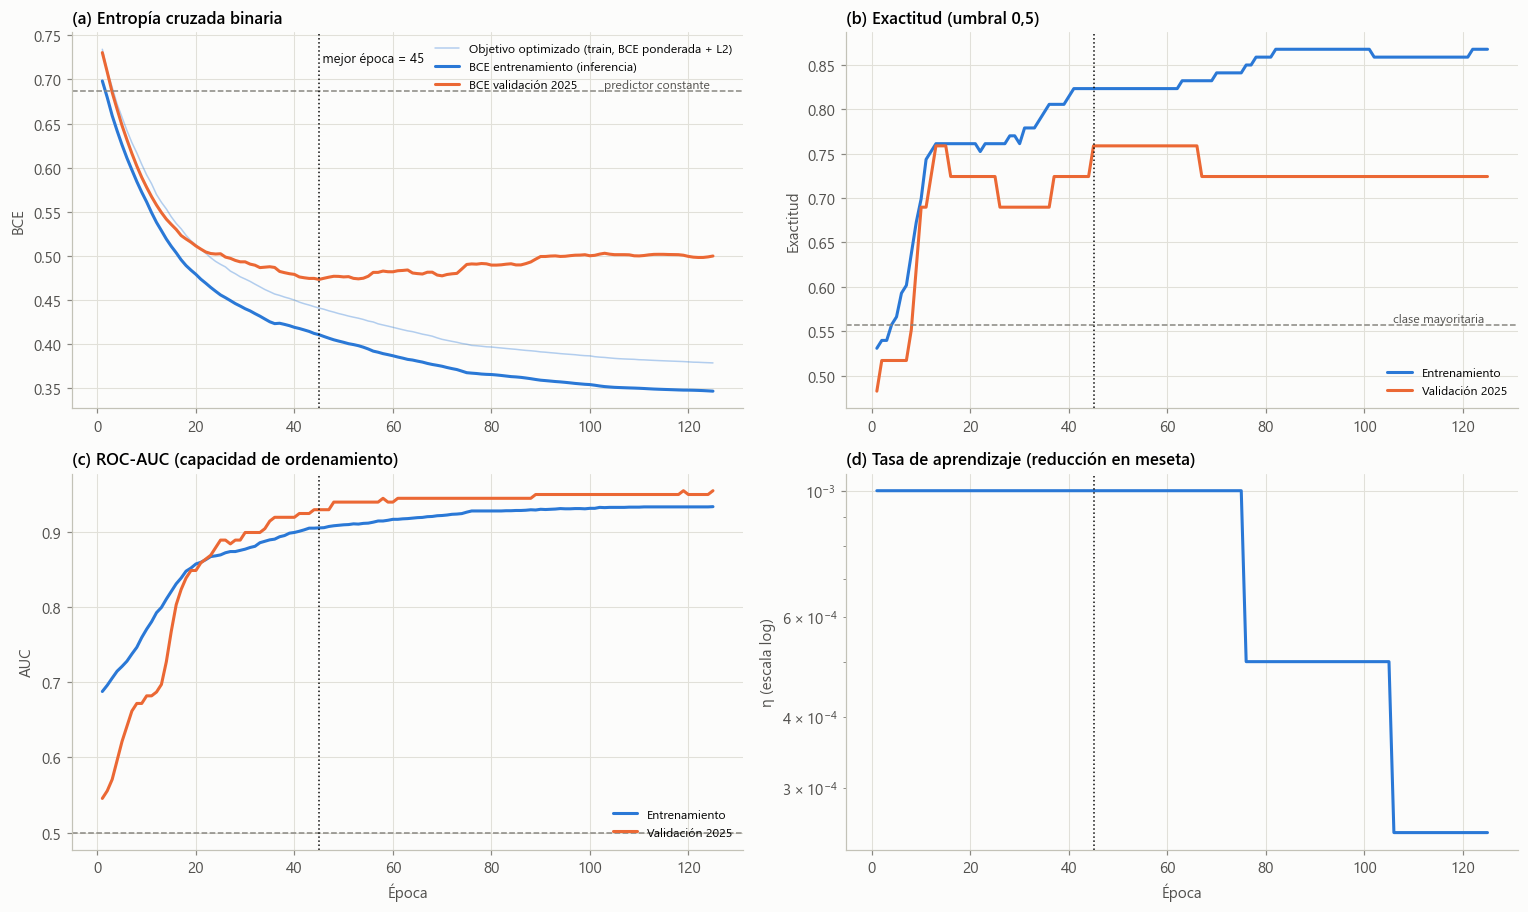

BCE de referencia (predictor constante con prevalencia de entrenamiento): 0.6865


,Entrenamiento,Validación,Brecha (train − val)
BCE,"0,410","0,473","-0,063"
Exactitud,"0,823","0,759","0,064"
ROC-AUC,"0,905","0,929","-0,024"


In [27]:
# =============================================================================
# 9.1 Curvas de pérdida, exactitud, AUC y tasa de aprendizaje por época
# =============================================================================
ep = np.array(HIST["epoca"]); be = INFO["mejor_epoca"]
H0 = bce(ytr, np.full_like(ytr, prev_train))   # BCE de un predictor constante (no aprende nada)
fig, axes = plt.subplots(2, 2, figsize=(14, 8.4))

ax = axes[0, 0]
ax.plot(ep, HIST["perdida_obj"], color=COL["train"], lw=1, alpha=0.35,
        label="Objetivo optimizado (train, BCE ponderada + L2" + (" con dropout)" if CFG.dropout else ")"))
ax.plot(ep, HIST["bce_tr"], color=COL["train"], label="BCE entrenamiento (inferencia)")
ax.plot(ep, HIST["bce_va"], color=COL["val"], label="BCE validación 2025")
ax.axhline(H0, color=TENUE, lw=1, ls="--"); ax.text(ep[-1], H0, "predictor constante ", ha="right", va="bottom", fontsize=8, color=TINTA2)
ax.axvline(be, color=TINTA, lw=1, ls=":"); ax.text(be, ax.get_ylim()[1] * 0.97, f" mejor época = {be}", fontsize=8.5, va="top", color=TINTA)
ax.set_title("(a) Entropía cruzada binaria"); ax.set_ylabel("BCE"); ax.legend(fontsize=8, loc="upper right")

ax = axes[0, 1]
ax.plot(ep, HIST["acc_tr"], color=COL["train"], label="Entrenamiento")
ax.plot(ep, HIST["acc_va"], color=COL["val"], label="Validación 2025")
ax.axhline(max(prev_train, 1 - prev_train), color=TENUE, lw=1, ls="--")
ax.text(ep[-1], max(prev_train, 1 - prev_train), "clase mayoritaria ", ha="right", va="bottom", fontsize=8, color=TINTA2)
ax.axvline(be, color=TINTA, lw=1, ls=":")
ax.set_title("(b) Exactitud (umbral 0,5)"); ax.set_ylabel("Exactitud"); ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 0]
ax.plot(ep, HIST["auc_tr"], color=COL["train"], label="Entrenamiento")
ax.plot(ep, HIST["auc_va"], color=COL["val"], label="Validación 2025")
ax.axhline(0.5, color=TENUE, lw=1, ls="--"); ax.axvline(be, color=TINTA, lw=1, ls=":")
ax.set_title("(c) ROC-AUC (capacidad de ordenamiento)"); ax.set_ylabel("AUC"); ax.set_xlabel("Época"); ax.legend(fontsize=8, loc="lower right")

ax = axes[1, 1]
ax.plot(ep, HIST["lr"], color=COL["mlp"]); ax.set_yscale("log"); ax.axvline(be, color=TINTA, lw=1, ls=":")
ax.set_title("(d) Tasa de aprendizaje (reducción en meseta)"); ax.set_ylabel("η (escala log)"); ax.set_xlabel("Época")
fig.tight_layout(); guardar(fig, "fig10_curvas_aprendizaje"); plt.show()

gap = pd.DataFrame({"Entrenamiento": [HIST["bce_tr"][be - 1], HIST["acc_tr"][be - 1], HIST["auc_tr"][be - 1]],
                    "Validación": [HIST["bce_va"][be - 1], HIST["acc_va"][be - 1], HIST["auc_va"][be - 1]]},
                   index=["BCE", "Exactitud", "ROC-AUC"])
gap["Brecha (train − val)"] = gap["Entrenamiento"] - gap["Validación"]
print(f"BCE de referencia (predictor constante con prevalencia de entrenamiento): {H0:.4f}")
tabla(gap, dec=3)

**Lectura de las curvas.**

* **Fase de aprendizaje (épocas 1–20).** Ambas pérdidas parten de ≈0,70, el nivel de un predictor que no sabe nada
  (0,687), y bajan juntas y rápido. La red aprende primero los patrones comunes a todos los años.
* **Punto óptimo (época 45).** La BCE de validación toca su mínimo (0,473) mientras la de entrenamiento sigue bajando
  (0,410). La brecha en ese punto es moderada: 0,06 en BCE y 6 puntos en exactitud. La parada temprana restaura estos
  pesos.
* **Inicio del sobreajuste (épocas 45–125).** El entrenamiento sigue mejorando hasta 0,35, pero la validación sube
  suavemente hasta ≈0,50: la red empieza a memorizar particularidades de 2021–2024 que no se repiten en 2025. Las dos
  reducciones de $\eta$ (épocas 76 y 106) llegan después del óptimo y solo afinan el ajuste de entrenamiento, así
  que el mínimo de validación es un óptimo de generalización y no un artefacto del optimizador.
* **Una señal que hay que interpretar: la AUC de validación (0,93) supera a la de entrenamiento (0,91), pero la BCE y
  la exactitud son peores.** La red *ordena* bien los departamentos de 2025 (cuál es más C que cuál), pero sus
  probabilidades quedan corridas hacia D. La causa es el cambio de prevalencia: 2025 tiene 62 % de perfiles C, frente
  a 44 % en 2021–2024. Los 7 errores de validación son todos departamentos C clasificados como D (sensibilidad 0,61,
  especificidad 1,00). Es un problema de **calibración ante un año atípico**, no de capacidad de discriminación.
* La exactitud avanza en escalones porque cada departamento de validación vale 3,4 puntos (29 filas). Por eso el
  criterio de parada es la BCE, que es continua.

---
# 10. Métricas de entrenamiento, validación y prueba

## 10.1 Tabla comparativa

Reportamos dos versiones del modelo:

* **Fase 1 (modelo base):** entrenado con 2021–2024 y detenido con la validación 2025. Es el modelo de las curvas
  de §9.
* **Fase 2 (modelo reajustado):** mismo modelo, mismas épocas y mismo calendario de tasa de aprendizaje de la fase 1,
  reentrenado con **2021–2025**. Es la práctica estándar antes de desplegar, porque incorpora el año más reciente,
  y es el que se usaría para decidir en 2026. La regresión logística recibe el mismo reajuste para que la comparación
  sea justa.

La prueba (2026) se evalúa una sola vez para ambas fases.

In [28]:
# =============================================================================
# 10.1 Predicciones de todos los modelos y reajuste con 2021-2025 (fase 2)
# =============================================================================
X_de = {"Entrenamiento": Xtr, "Validación": Xva, "Prueba": Xte}
y_de = {"Entrenamiento": ytr, "Validación": yva, "Prueba": yte}
m_de = {"Entrenamiento": m_tr, "Validación": m_va, "Prueba": m_te}
P = {("MLP fase 1", k): predecir(X) for k, X in X_de.items()}
P.update({("Logística fase 1", k): logit.predict_proba(X)[:, 1] for k, X in X_de.items()})
P.update({("Persistencia", k): score_persistencia(m) for k, m in m_de.items()})
P.update({("Clase mayoritaria", k): np.full(len(y_de[k]), prev_train) for k in X_de})

# Fase 2: reajuste con entrenamiento + validación (2021-2025), mismas épocas y calendario de LR
m_trva = m_tr | m_va
escalador_f2 = StandardScaler().fit(datos.loc[m_trva, FEATURES])
Xtrva_f2, Xte_f2 = matriz(m_trva, escalador_f2), matriz(m_te, escalador_f2)
ytrva = datos.loc[m_trva, "y"].values.astype("float32")
modelo_f2, _, _, predecir_f2 = entrenar_mlp(Xtrva_f2, ytrva, cfg=CFG, semilla=SEED, epocas=INFO["mejor_epoca"],
                                            calendario_lr=INFO["calendario_lr"], diagnostico=False)
logit_f2 = LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000).fit(Xtrva_f2, ytrva)
P[("MLP fase 2", "Prueba")] = predecir_f2(Xte_f2)
P[("Logística fase 2", "Prueba")] = logit_f2.predict_proba(Xte_f2)[:, 1]
P[("MLP fase 2", "Entrenamiento")] = predecir_f2(Xtrva_f2)

filas = []
for (modelo_n, conjunto), p in P.items():
    y_ = ytrva if (modelo_n == "MLP fase 2" and conjunto == "Entrenamiento") else y_de[conjunto]
    filas.append({"Modelo": modelo_n, "Conjunto": conjunto if not (modelo_n == "MLP fase 2" and conjunto == "Entrenamiento")
                  else "Entrenamiento (2021-25)", **metricas(y_, p)})
MET = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
orden_m = ["Clase mayoritaria", "Persistencia", "Logística fase 1", "MLP fase 1", "Logística fase 2", "MLP fase 2"]
orden_c = ["Entrenamiento", "Entrenamiento (2021-25)", "Validación", "Prueba"]
MET = MET.reindex([(m, c) for m in orden_m for c in orden_c if (m, c) in MET.index])
cols = ["Exactitud", "Exact. balanceada", "Sensibilidad C", "Especificidad D", "F1 C", "MCC", "ROC-AUC", "PR-AUC", "Log-loss", "Brier"]
display(MET[cols].style.format(precision=3, decimal=",", na_rep="–")
        .background_gradient(subset=["ROC-AUC", "Exact. balanceada", "MCC"], cmap=CMAP_P, vmin=0.4, vmax=1.0)
        .background_gradient(subset=["Log-loss"], cmap=CMAP_P.reversed(), vmin=0.2, vmax=1.0))

In [29]:
# =============================================================================
# 10.2 Incertidumbre de la prueba: intervalos de confianza bootstrap al 95 %
# =============================================================================
fns = {"Exactitud": lambda y, p: accuracy_score(y, p >= .5), "ROC-AUC": roc_auc_score, "Log-loss": bce}
filas = []
for nombre in ["Persistencia", "Logística fase 1", "MLP fase 1", "Logística fase 2", "MLP fase 2"]:
    p = P[(nombre, "Prueba")]
    fila = {"Modelo": nombre}
    for met, fn in fns.items():
        lo, hi = bootstrap_ic(yte, p, fn)
        fila[met] = f"{fn(yte, p):.3f}  [{lo:.3f} – {hi:.3f}]"
    filas.append(fila)
IC_TEST = pd.DataFrame(filas).set_index("Modelo")
display(IC_TEST)
print(f"n prueba = {len(yte)} departamentos (C = {int(yte.sum())}, D = {int(len(yte) - yte.sum())}); "
      f"cada error equivale a {1 / len(yte):.1%} de exactitud.")

,Exactitud,ROC-AUC,Log-loss
Modelo,,,
Persistencia,0.862 [0.724 – 0.966],0.948 [0.843 – 1.000],0.429 [0.344 – 0.519]
Logística fase 1,0.655 [0.483 – 0.828],0.762 [0.567 – 0.919],0.582 [0.387 – 0.811]
MLP fase 1,0.759 [0.586 – 0.897],0.795 [0.605 – 0.948],0.576 [0.365 – 0.858]
Logística fase 2,0.724 [0.552 – 0.862],0.795 [0.605 – 0.943],0.554 [0.366 – 0.782]
MLP fase 2,0.759 [0.586 – 0.897],0.829 [0.657 – 0.962],0.547 [0.335 – 0.834]


n prueba = 29 departamentos (C = 14, D = 15); cada error equivale a 3.4% de exactitud.


**Lectura de las métricas.**

* **Aprendizaje real.** Frente a la clase mayoritaria (AUC 0,50, log-loss 0,70), el MLP baja la log-loss de prueba a
  0,55–0,58 y alcanza AUC 0,80–0,83, con exactitud balanceada 0,76 y MCC 0,52 (acuerdo moderado corregido por azar).
  En 2026 identifica 10 de 14 departamentos C (sensibilidad 0,71) y 12 de 15 D (especificidad 0,80).
* **Degradación con la distancia temporal.** La log-loss sube de 0,41 en entrenamiento a 0,47 en validación (un año
  después) y 0,58 en prueba (dos años después). El reajuste con 2025 (fase 2) recupera parte: AUC 0,795 → 0,829 y
  log-loss 0,576 → 0,547. Es una señal de **deriva temporal**: el año más reciente trae información que los anteriores
  no tienen, así que el modelo operativo debe reentrenarse cada año.
* **MLP frente a logística en la prueba.** El MLP supera a la logística en ambas fases (exactitud 0,76 vs. 0,66–0,72;
  AUC 0,80–0,83 vs. 0,76–0,80). Pero con 29 departamentos los intervalos bootstrap se solapan casi por completo; por
  ejemplo, el AUC del MLP fase 2 va de 0,66 a 0,96. Una prueba de 29 filas no basta para concluir superioridad. La
  comparación rigurosa, con 116 y 171 predicciones fuera de muestra, está en §11.4.
* **El dato incómodo: la persistencia gana.** Repetir el perfil de 2025 acierta 25 de 29 departamentos en 2026
  (exactitud 0,86, AUC 0,95, log-loss 0,43). Las variables de la Etapa 1 describen **dónde** hay condiciones para
  cada perfil (estructura), pero no **cuál es la composición actual** del conflicto, que es lo que más se parece al año
  siguiente. Es el hallazgo central del diagnóstico y lo atacamos en §13 (E1).
* **Calibración (§10.5).** Los puntos de ambos modelos quedan por encima de la diagonal: en los años fuera de muestra
  la frecuencia real de C es mayor que la probabilidad predicha. Es la huella del cambio de prevalencia de 2025,
  coherente con las curvas. MLP y logística tienen prácticamente el mismo Brier (0,173 y 0,172).

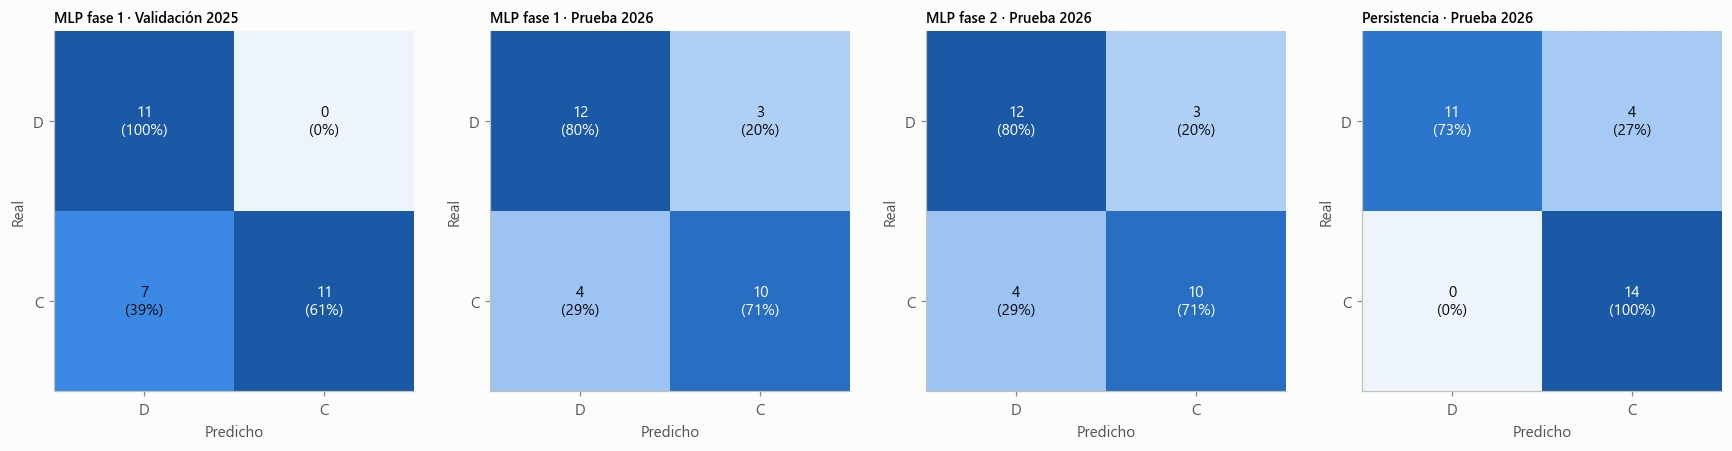

In [30]:
# =============================================================================
# 10.3 Matrices de confusión
# =============================================================================
casos = [("MLP fase 1 · Validación 2025", yva, P[("MLP fase 1", "Validación")]),
         ("MLP fase 1 · Prueba 2026", yte, P[("MLP fase 1", "Prueba")]),
         ("MLP fase 2 · Prueba 2026", yte, P[("MLP fase 2", "Prueba")]),
         ("Persistencia · Prueba 2026", yte, P[("Persistencia", "Prueba")])]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (tit, y_, p_) in zip(axes, casos):
    cm = confusion_matrix(y_.astype(int), (p_ >= .5).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap=CMAP_P, vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > cm.max() * 0.65 else TINTA)
    ax.set_xticks([0, 1], ["D", "C"]); ax.set_yticks([0, 1], ["D", "C"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(tit, fontsize=9.5)
fig.tight_layout(); guardar(fig, "fig11_matrices_confusion"); plt.show()

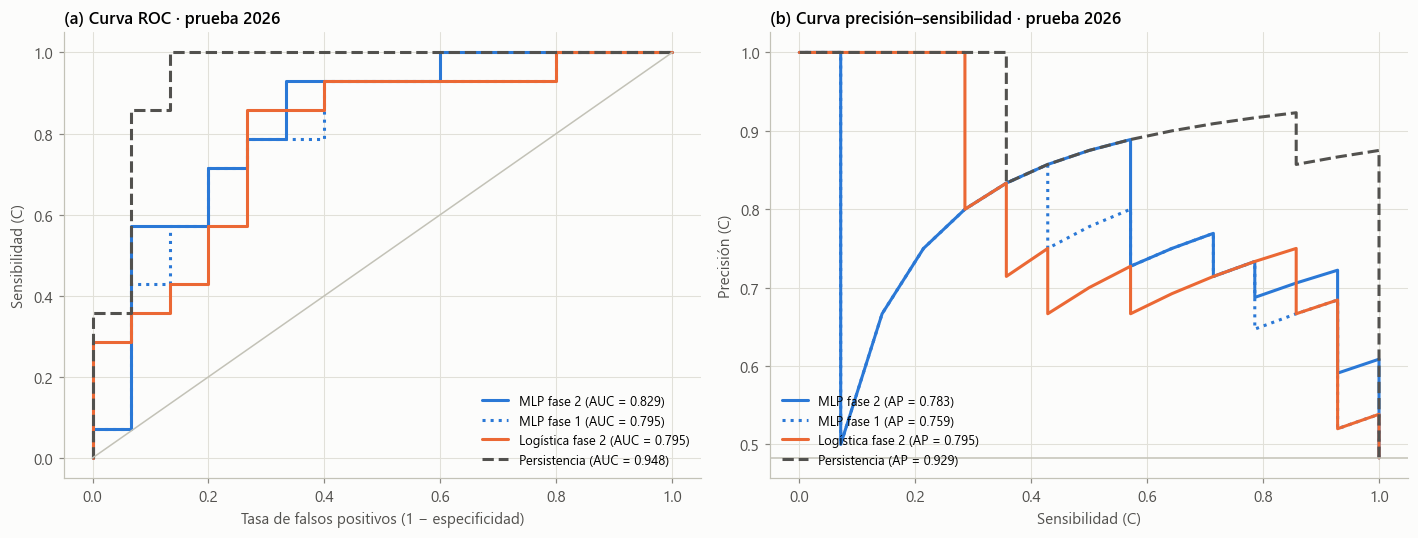

In [31]:
# =============================================================================
# 10.4 Curvas ROC y precisión–sensibilidad en la prueba (2026)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
curvas = [("MLP fase 2", COL["mlp"], "-"), ("MLP fase 1", COL["mlp"], ":"), ("Logística fase 2", COL["logit"], "-"),
          ("Persistencia", COL["pers"], "--")]
for nombre, color, ls in curvas:
    p = P[(nombre, "Prueba")]
    fpr, tpr, _ = roc_curve(yte, p); prec, rec, _ = precision_recall_curve(yte, p)
    axes[0].plot(fpr, tpr, color=color, ls=ls, label=f"{nombre} (AUC = {roc_auc_score(yte, p):.3f})")
    axes[1].plot(rec, prec, color=color, ls=ls, label=f"{nombre} (AP = {average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=EJE, lw=1); axes[1].axhline(yte.mean(), color=EJE, lw=1)
axes[0].set_xlabel("Tasa de falsos positivos (1 − especificidad)"); axes[0].set_ylabel("Sensibilidad (C)")
axes[1].set_xlabel("Sensibilidad (C)"); axes[1].set_ylabel("Precisión (C)")
axes[0].set_title("(a) Curva ROC · prueba 2026"); axes[1].set_title("(b) Curva precisión–sensibilidad · prueba 2026")
for ax in axes:
    ax.legend(fontsize=8.5, loc="lower right" if ax is axes[0] else "lower left")
fig.tight_layout(); guardar(fig, "fig12_roc_pr"); plt.show()

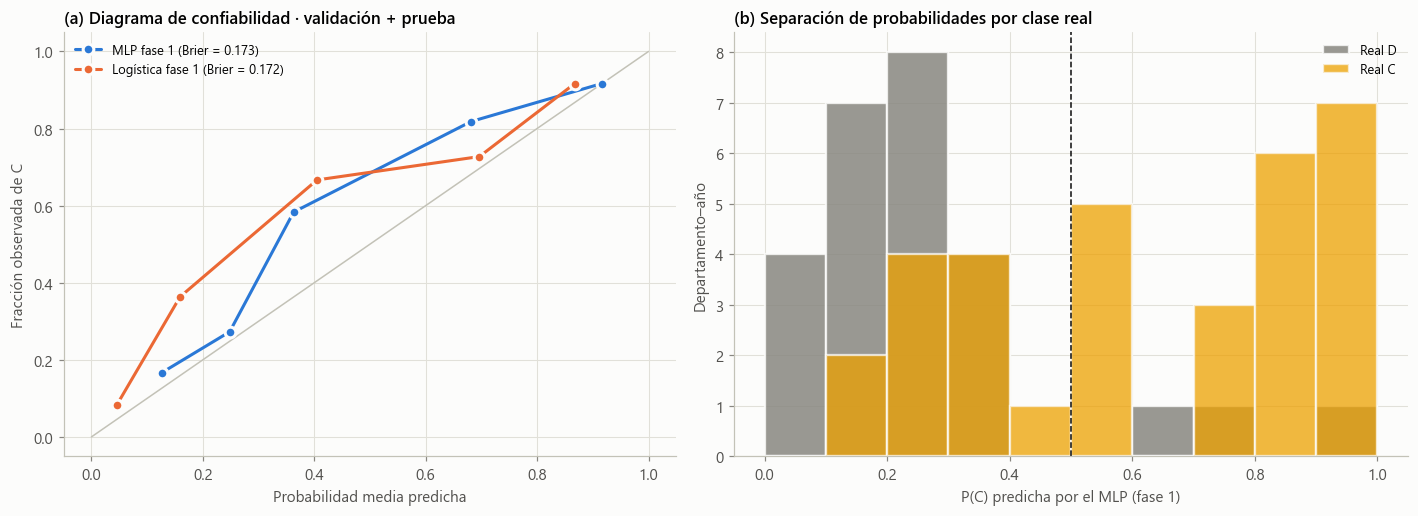

In [32]:
# =============================================================================
# 10.5 Calibración: ¿una probabilidad de 0,8 significa 80 % de departamentos C?
# =============================================================================
y_fuera = np.concatenate([yva, yte])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ax.plot([0, 1], [0, 1], color=EJE, lw=1)
for nombre, color in [("MLP fase 1", COL["mlp"]), ("Logística fase 1", COL["logit"])]:
    p = np.concatenate([P[(nombre, "Validación")], P[(nombre, "Prueba")]])
    fr, mp = calibration_curve(y_fuera, p, n_bins=5, strategy="quantile")
    ax.plot(mp, fr, marker="o", ms=7, color=color, mec=FONDO, mew=2,
            label=f"{nombre} (Brier = {brier_score_loss(y_fuera, p):.3f})")
ax.set_xlabel("Probabilidad media predicha"); ax.set_ylabel("Fracción observada de C")
ax.set_title("(a) Diagrama de confiabilidad · validación + prueba"); ax.legend(fontsize=8.5, loc="upper left")
ax = axes[1]
p = np.concatenate([P[("MLP fase 1", "Validación")], P[("MLP fase 1", "Prueba")]])
ax.hist(p[y_fuera == 0], bins=np.linspace(0, 1, 11), color=COL["D"], alpha=0.85, label="Real D", edgecolor=FONDO, lw=1.5)
ax.hist(p[y_fuera == 1], bins=np.linspace(0, 1, 11), color=COL["C"], alpha=0.75, label="Real C", edgecolor=FONDO, lw=1.5)
ax.axvline(0.5, color=TINTA, lw=1, ls="--")
ax.set_xlabel("P(C) predicha por el MLP (fase 1)"); ax.set_ylabel("Departamento–año")
ax.set_title("(b) Separación de probabilidades por clase real"); ax.legend(fontsize=8.5)
fig.tight_layout(); guardar(fig, "fig13_calibracion"); plt.show()

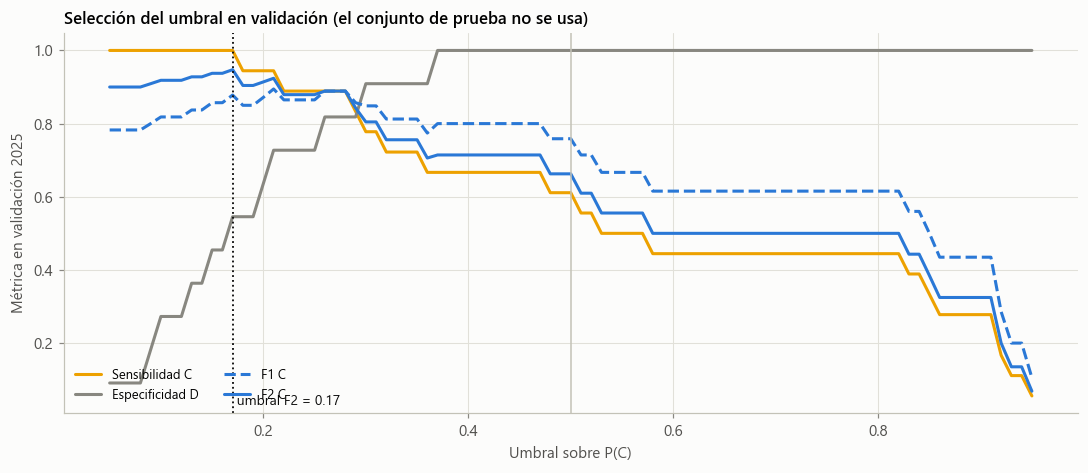

,Exactitud,Exact. balanceada,Sensibilidad C,Especificidad D,F1 C,MCC
"Umbral 0,50","0,759","0,757","0,714","0,800","0,741","0,517"
Umbral 0.17 (F2 en validación),"0,552","0,567","1,000","0,133","0,683","0,263"


In [33]:
# =============================================================================
# 10.6 Umbral de decisión: costo asimétrico de los errores
# =============================================================================
# Un falso negativo (C clasificado como D) deja sin capacidades ISR/detección un territorio de violencia
# armada directa; un falso positivo sobreasigna recursos. Priorizamos la sensibilidad con F2 (β = 2).
umbrales = np.linspace(0.05, 0.95, 91)
p_va = P[("MLP fase 1", "Validación")]
curva_u = pd.DataFrame({"umbral": umbrales,
                        "Sensibilidad C": [recall_score(yva, p_va >= u, zero_division=0) for u in umbrales],
                        "Especificidad D": [recall_score(1 - yva, p_va < u, zero_division=0) for u in umbrales],
                        "F1 C": [f1_score(yva, p_va >= u, zero_division=0) for u in umbrales],
                        "F2 C": [fbeta_score(yva, p_va >= u, beta=2, zero_division=0) for u in umbrales]})
U_OPT = float(curva_u.loc[curva_u["F2 C"].idxmax(), "umbral"])

fig, ax = plt.subplots(figsize=(10, 4.4))
for col, color, ls in [("Sensibilidad C", COL["C"], "-"), ("Especificidad D", COL["D"], "-"), ("F1 C", COL["mlp"], "--"), ("F2 C", COL["mlp"], "-")]:
    ax.plot(curva_u["umbral"], curva_u[col], color=color, ls=ls, label=col)
ax.axvline(0.5, color=EJE, lw=1); ax.axvline(U_OPT, color=TINTA, lw=1.2, ls=":")
ax.text(U_OPT, 0.03, f" umbral F2 = {U_OPT:.2f}", fontsize=9, color=TINTA)
ax.set_xlabel("Umbral sobre P(C)"); ax.set_ylabel("Métrica en validación 2025")
ax.set_title("Selección del umbral en validación (el conjunto de prueba no se usa)"); ax.legend(fontsize=8.5, ncol=2, loc="lower left")
fig.tight_layout(); guardar(fig, "fig14_umbral"); plt.show()

comp_u = pd.DataFrame({f"Umbral 0,50": metricas(yte, P[("MLP fase 1", "Prueba")], 0.5),
                       f"Umbral {U_OPT:.2f} (F2 en validación)": metricas(yte, P[("MLP fase 1", "Prueba")], U_OPT)}).T
tabla(comp_u[["Exactitud", "Exact. balanceada", "Sensibilidad C", "Especificidad D", "F1 C", "MCC"]], dec=3)

**Lectura del umbral.** El umbral que maximiza F2 en validación es muy bajo (0,17): en 2025 muchos departamentos C
recibieron probabilidades bajas, y para recuperarlos hay que bajar el listón. Aplicado a 2026, con prevalencia de
48 %, ese umbral clasifica casi todo como C: sensibilidad 1,00, pero especificidad 0,13 y exactitud 0,55. **El umbral
óptimo no se transfiere entre años con prevalencias distintas.** Para el modelo base mantenemos 0,5, y dejamos como
mejora (M5) elegir el umbral sobre predicciones fuera de muestra de varios años, después de recalibrar las
probabilidades. Es un ejemplo concreto de por qué las métricas deben interpretarse y no solo optimizarse: un ajuste
que en validación parece correcto puede empeorar la decisión real.

---
# 11. Diagnóstico técnico del comportamiento del modelo

El diagnóstico responde cuatro preguntas, cada una con evidencia propia:

| Pregunta | Evidencia |
|---|---|
| **Convergencia:** ¿el optimizador llegó a un mínimo estable, o se detuvo antes o después de tiempo? | Norma del gradiente, razón de actualización de pesos, calendario de $\eta$ (§11.1) |
| **Estabilidad:** ¿el resultado depende de la semilla aleatoria? | 10 reentrenamientos con semillas distintas (§11.2) |
| **Generalización:** ¿el desempeño se sostiene en años y territorios no vistos? ¿Falta capacidad o faltan datos? | Validación temporal de origen móvil, validación espacial por departamentos, curvas por tamaño de muestra y por capacidad (§11.3) |
| **Aporte de la no linealidad:** ¿la red supera de forma significativa a la neurona lineal? | Pruebas pareadas y superficies de dependencia parcial (§11.4) |

## 11.1 Convergencia

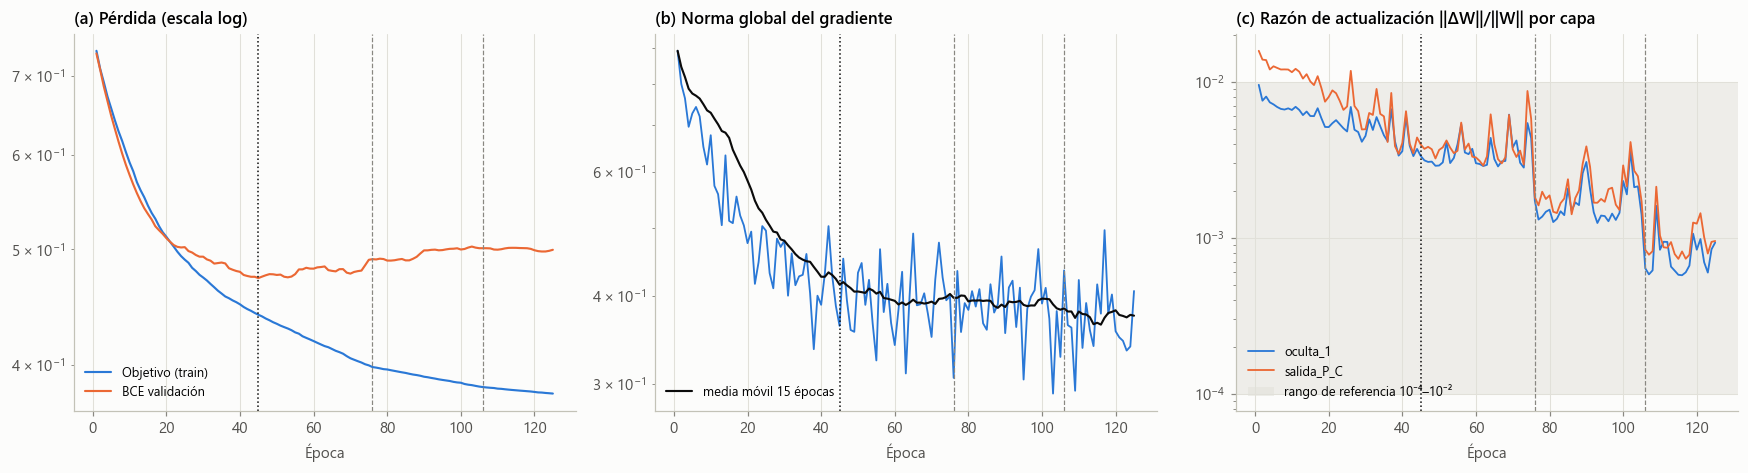

,Valor
BCE train: inicial → mínima,0.698 → 0.346
Época en que se logra el 90 % de la reducción de la BCE de train,65
Pendiente de la BCE de train en las últimas 20 épocas (por época),-2.09e-04
Norma del gradiente: primeras 5 → últimas 5 épocas,0.775 → 0.355
Razón de actualización mediana (últimas 20 épocas),"oculta_1: 6.8e-04, salida_P_C: 8.7e-04"
Reducciones de η (épocas),"76, 106"
Mejor época / épocas ejecutadas,45 / 125


In [34]:
# =============================================================================
# 11.1 Señales de convergencia: gradiente, razón de actualización y pérdida
# =============================================================================
ratios = np.array(HIST["ratio_act"])
capas_k = [c.name for c in modelo.layers if hasattr(c, "kernel")]
cortes_lr = [e for e, a, b in zip(ep[1:], HIST["lr"][:-1], HIST["lr"][1:]) if b < a]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
ax.plot(ep, HIST["perdida_obj"], color=COL["train"], lw=1.4, label="Objetivo (train)")
ax.plot(ep, HIST["bce_va"], color=COL["val"], lw=1.4, label="BCE validación")
ax.set_yscale("log"); ax.set_title("(a) Pérdida (escala log)"); ax.set_xlabel("Época"); ax.legend(fontsize=8.5)
ax = axes[1]
ax.plot(ep, HIST["norma_grad"], color=COL["mlp"], lw=1.2)
ax.plot(ep, pd.Series(HIST["norma_grad"]).rolling(15, min_periods=1).mean(), color=TINTA, lw=1.4, label="media móvil 15 épocas")
ax.set_yscale("log"); ax.set_title("(b) Norma global del gradiente"); ax.set_xlabel("Época"); ax.legend(fontsize=8.5)
ax = axes[2]
paleta_capas = [COL["mlp"], COL["logit"], COL["test"], COL["C"]]
for j, nombre in enumerate(capas_k):
    ax.plot(ep, ratios[:, j], color=paleta_capas[j % 4], lw=1.2, label=nombre)
ax.axhspan(1e-4, 1e-2, color=GRID, alpha=0.5, lw=0, label="rango de referencia 10⁻⁴–10⁻²"); ax.set_yscale("log")
ax.set_title("(c) Razón de actualización ‖ΔW‖/‖W‖ por capa"); ax.set_xlabel("Época"); ax.legend(fontsize=8.5)
for a in axes:
    a.axvline(INFO["mejor_epoca"], color=TINTA, lw=1, ls=":")
    for c in cortes_lr:
        a.axvline(c, color=TENUE, lw=0.8, ls="--")
fig.tight_layout(); guardar(fig, "fig15_convergencia"); plt.show()

bce_tr = np.array(HIST["bce_tr"]); reduccion = bce_tr[0] - bce_tr.min()
ep90 = int(ep[np.argmax(bce_tr <= bce_tr[0] - 0.9 * reduccion)])
conv = pd.Series({
    "BCE train: inicial → mínima": f"{bce_tr[0]:.3f} → {bce_tr.min():.3f}",
    "Época en que se logra el 90 % de la reducción de la BCE de train": ep90,
    "Pendiente de la BCE de train en las últimas 20 épocas (por época)": f"{np.polyfit(ep[-20:], bce_tr[-20:], 1)[0]:+.2e}",
    "Norma del gradiente: primeras 5 → últimas 5 épocas": f"{np.mean(HIST['norma_grad'][:5]):.3f} → {np.mean(HIST['norma_grad'][-5:]):.3f}",
    "Razón de actualización mediana (últimas 20 épocas)": ", ".join(f"{n}: {np.median(ratios[-20:, j]):.1e}" for j, n in enumerate(capas_k)),
    "Reducciones de η (épocas)": ", ".join(map(str, cortes_lr)) or "ninguna",
    "Mejor época / épocas ejecutadas": f"{INFO['mejor_epoca']} / {INFO['epocas_ejecutadas']}",
}, name="Valor")
display(conv.to_frame())

**Diagnóstico de convergencia.**

* **La pérdida baja de forma monótona y suave** (panel a, escala log). El 90 % de la reducción de la BCE de
  entrenamiento se logra hacia la época 65, y en las últimas 20 épocas la pendiente es de −2×10⁻⁴ por época (≈0,004
  acumulado). El optimizador está en una meseta: seguir entrenando no cambiaría el modelo.
* **La norma del gradiente cae a menos de la mitad** (0,78 → 0,36) y se estabiliza. Que no llegue a cero es lo
  esperado con minilotes de 16: cada lote aporta un gradiente ruidoso, y además el término L2 compensa el ajuste a los
  datos. Lo relevante es que su media móvil deja de bajar, que indica régimen estacionario.
* **La razón de actualización** $\lVert\Delta W\rVert/\lVert W\rVert$ baja de ≈10⁻² a 7–9×10⁻⁴ y permanece dentro
  de la banda de referencia 10⁻⁴–10⁻² todo el tiempo: los pesos ni explotan ni se congelan. Cada reducción de
  $\eta$ (épocas 76 y 106) produce un escalón visible hacia abajo, señal de que el optimizador responde al calendario.
* **Sin inestabilidades:** no hay saltos de pérdida, gradientes explosivos ni valores no numéricos, y la verificación
  de §8.2 confirma que el algoritmo es el mismo de Keras.
* **Veredicto:** la red **converge a un mínimo estable**. El óptimo de validación (época 45) llega *antes* de la meseta
  de entrenamiento (≈65), así que el factor limitante es la generalización y no la optimización. Entrenar más o
  cambiar de optimizador no mejoraría el modelo; más datos o mejores predictoras, sí.

## 11.2 Estabilidad frente a la inicialización aleatoria

Con 113 filas de entrenamiento, dos inicializaciones distintas pueden llevar a mínimos distintos. Reentrenamos el
modelo base con **10 semillas** (misma configuración, datos y protocolo de parada temprana) y medimos cuánto varían
las métricas, la época óptima y las predicciones individuales.

10 entrenamientos en 7 s


,Media,Desv. est.,Mín.,Máx.,CV (%)
Mejor época,"76,700","26,608","36,000","111,000","34,692"
BCE val,"0,395","0,028","0,353","0,423","7,010"
AUC val,"0,979","0,015","0,949","0,995","1,535"
BCE prueba,"0,493","0,027","0,459","0,532","5,410"
AUC prueba,"0,848","0,024","0,810","0,876","2,778"
Exactitud prueba,"0,721","0,020","0,690","0,759","2,716"


Presupuesto de referencia: mediana de la mejor época = 70 épocas ≈ 560 pasos de gradiente (la semilla 42 del modelo base se detuvo en la época 45)


,Semilla individual (media),Ensamble de 10 semillas
BCE prueba,"0,493","0,470"
AUC prueba,"0,848","0,871"
Exactitud prueba,"0,721","0,690"


Departamentos de prueba con predicción unánime entre las 10 semillas: 66%


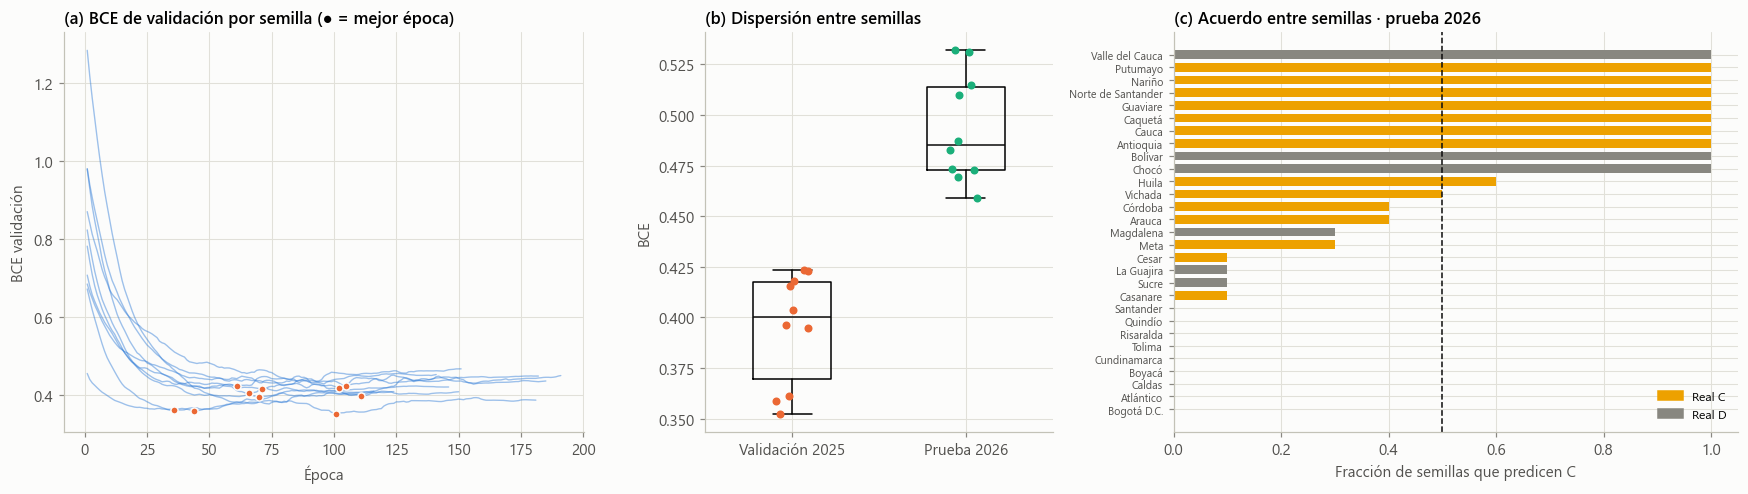

In [35]:
# =============================================================================
# 11.2 Reentrenamiento con 10 semillas
# =============================================================================
SEMILLAS = list(range(101, 111))
filas, curvas_va, probs_te, probs_va = [], [], [], []
t0 = time.time()
for s in SEMILLAS:
    _, H_s, inf_s, pred_s = entrenar_mlp(Xtr, ytr, Xva, yva, cfg=CFG, semilla=s, diagnostico=False)
    pv, pt = pred_s(Xva), pred_s(Xte)
    curvas_va.append(H_s["bce_va"]); probs_te.append(pt); probs_va.append(pv)
    filas.append({"Semilla": s, "Mejor época": inf_s["mejor_epoca"], "BCE val": bce(yva, pv), "AUC val": roc_auc_score(yva, pv),
                  "BCE prueba": bce(yte, pt), "AUC prueba": roc_auc_score(yte, pt), "Exactitud prueba": accuracy_score(yte, pt >= .5)})
ESTAB = pd.DataFrame(filas).set_index("Semilla")
print(f"10 entrenamientos en {time.time() - t0:.0f} s")
resumen_estab = ESTAB.agg(["mean", "std", "min", "max"]).T
resumen_estab["CV (%)"] = 100 * resumen_estab["std"] / resumen_estab["mean"]
resumen_estab.columns = ["Media", "Desv. est.", "Mín.", "Máx.", "CV (%)"]
tabla(resumen_estab, dec=3)

# Presupuesto de entrenamiento para los reentrenamientos sin validación (§11.3, §12, §13):
# mediana de la mejor época entre semillas, expresada en pasos de gradiente para que no dependa del tamaño del conjunto.
EPOCAS_REF = int(np.median(ESTAB["Mejor época"]))
PASOS_REF = EPOCAS_REF * math.ceil(len(ytr) / CFG.batch)
print(f"Presupuesto de referencia: mediana de la mejor época = {EPOCAS_REF} épocas ≈ {PASOS_REF} pasos de gradiente "
      f"(la semilla 42 del modelo base se detuvo en la época {INFO['mejor_epoca']})")

probs_te = np.array(probs_te); p_ens = probs_te.mean(axis=0)
acuerdo = (probs_te >= .5).mean(axis=0)
unanimes = np.mean((acuerdo == 0) | (acuerdo == 1))
ens = pd.DataFrame({"Semilla individual (media)": [ESTAB["BCE prueba"].mean(), ESTAB["AUC prueba"].mean(), ESTAB["Exactitud prueba"].mean()],
                    "Ensamble de 10 semillas": [bce(yte, p_ens), roc_auc_score(yte, p_ens), accuracy_score(yte, p_ens >= .5)]},
                   index=["BCE prueba", "AUC prueba", "Exactitud prueba"])
tabla(ens, dec=3)
print(f"Departamentos de prueba con predicción unánime entre las 10 semillas: {unanimes:.0%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.2, 0.8, 1.3]})
ax = axes[0]
for c, s in zip(curvas_va, SEMILLAS):
    ax.plot(range(1, len(c) + 1), c, color=COL["mlp"], lw=0.9, alpha=0.45)
    k = int(np.argmin(c)); ax.scatter(k + 1, c[k], s=22, color=COL["val"], edgecolor=FONDO, lw=1, zorder=3)
ax.set_title("(a) BCE de validación por semilla (● = mejor época)"); ax.set_xlabel("Época"); ax.set_ylabel("BCE validación")
ax = axes[1]
datos_box = [ESTAB["BCE val"], ESTAB["BCE prueba"]]
ax.boxplot(datos_box, widths=0.45, showfliers=False, medianprops=dict(color=TINTA))
for k, v in enumerate(datos_box, 1):
    ax.scatter(np.full(len(v), k) + np.random.default_rng(k).uniform(-.1, .1, len(v)), v, s=18, color=[COL["val"], COL["test"]][k - 1], zorder=3)
ax.set_xticks([1, 2], ["Validación 2025", "Prueba 2026"]); ax.set_ylabel("BCE"); ax.set_title("(b) Dispersión entre semillas")
ax = axes[2]
orden_t = np.argsort(acuerdo)
nombres_te = datos.loc[m_te, "departamento"].values
ax.barh(range(len(orden_t)), acuerdo[orden_t], color=[COL["C"] if yte[i] == 1 else COL["D"] for i in orden_t], height=0.7)
ax.set_yticks(range(len(orden_t)), nombres_te[orden_t], fontsize=7); ax.axvline(0.5, color=TINTA, lw=1, ls="--")
ax.set_xlabel("Fracción de semillas que predicen C"); ax.set_title("(c) Acuerdo entre semillas · prueba 2026")
ax.legend(handles=[Patch(color=COL["C"], label="Real C"), Patch(color=COL["D"], label="Real D")], fontsize=8, loc="lower right")
fig.tight_layout(); guardar(fig, "fig16_estabilidad_semillas"); plt.show()

**Diagnóstico de estabilidad.**

* **Las métricas son estables.** Entre 10 semillas, el AUC de prueba es 0,848 ± 0,024 (CV 2,8 %) y la BCE de prueba
  0,493 ± 0,027 (CV 5,4 %). La arquitectura da resultados reproducibles en su orden de magnitud.
* **La época óptima no lo es** (entre 36 y 111, CV 35 %). El panel (a) explica por qué: la BCE de validación forma un
  valle ancho y plano, así que detenerse en la época 40 o en la 100 cambia poco el desempeño. Es una superficie de
  pérdida benigna.
* **El modelo base (semilla 42) cayó en la cola desfavorable.** Su AUC de prueba (0,795) está por debajo del mínimo de
  las 10 semillas (0,810), y se detuvo antes que casi todas (época 45 frente a una mediana de 70). Hay dos
  consecuencias prácticas: una sola semilla subestima lo que puede hacer la arquitectura, y por eso los
  reentrenamientos de §11.3, §12 y §13 usan el presupuesto mediano de 70 épocas (560 pasos) y no el de la semilla 42.
* **Ensamble.** Promediar las 10 redes mejora las métricas probabilísticas (AUC 0,871 y BCE 0,470, frente a 0,848 y
  0,493 en promedio). La exactitud baja a 0,690 porque las probabilidades promediadas se concentran cerca de 0,5 y
  algunos departamentos frontera cruzan el umbral. Es otra muestra de que, con n = 29, la exactitud con umbral fijo es
  la métrica menos robusta.
* **Acuerdo por departamento (panel c).** El 66 % de los departamentos de prueba recibe la misma predicción de las 10
  redes. Los desacuerdos se concentran en Huila, Vichada, Córdoba, Arauca, Magdalena y Meta, los que están cerca de
  la frontera de decisión. Los errores unánimes (Valle del Cauca, Bolívar y Chocó, predichos C y observados D) son
  sistemáticos, no aleatorios: corresponden a transiciones C → D que ninguna inicialización anticipa.

## 11.3 Generalización

Evaluamos la generalización en tres ejes complementarios:

1. **Temporal.** Validación de origen móvil: para cada año $v$ de 2023 a 2026 se entrena con todos los años anteriores
   y se predice $v$. Replica el uso real año tras año.
2. **Espacial.** Validación cruzada agrupada por departamento (5 pliegues): los departamentos de prueba **nunca**
   aparecen en entrenamiento, en ningún año (Roberts et al., 2017). Mide lo que importa para la migración a municipios
   (§13): ¿el modelo aprende relaciones que se transfieren a territorios nuevos, o memoriza departamentos?
3. **Diagnóstico sesgo–varianza.** Curvas de desempeño según el tamaño de la muestra de entrenamiento y según la
   capacidad de la red.

En los pliegues sin conjunto de validación propio, la red se entrena con un **presupuesto fijo de pasos de gradiente**
(la mediana de la mejor época de las 10 semillas de §11.2, convertida a pasos para que no dependa del tamaño de cada
pliegue), así que no hay parada temprana con datos de prueba.

Validaciones temporal y espacial en 4 s
Validación temporal (predicciones fuera de muestra 2023-2026, agregadas):


,Exactitud,Exact. balanceada,F1 C,MCC,ROC-AUC,Log-loss,Brier
MLP,"0,802","0,802","0,777","0,619","0,892","0,436","0,140"
Logística,"0,802","0,802","0,793","0,606","0,875","0,448","0,145"
Persistencia,"0,888","0,888","0,889","0,776","0,965","0,380","0,112"


Validación espacial (departamentos nunca vistos, agregadas):


,Exactitud,Exact. balanceada,F1 C,MCC,ROC-AUC,Log-loss,Brier
MLP,"0,737","0,734","0,710","0,473","0,804","0,577","0,183"
Logística,"0,754","0,753","0,741","0,508","0,841","0,505","0,167"
Persistencia,"0,854","0,854","0,850","0,708","0,918","0,420","0,128"


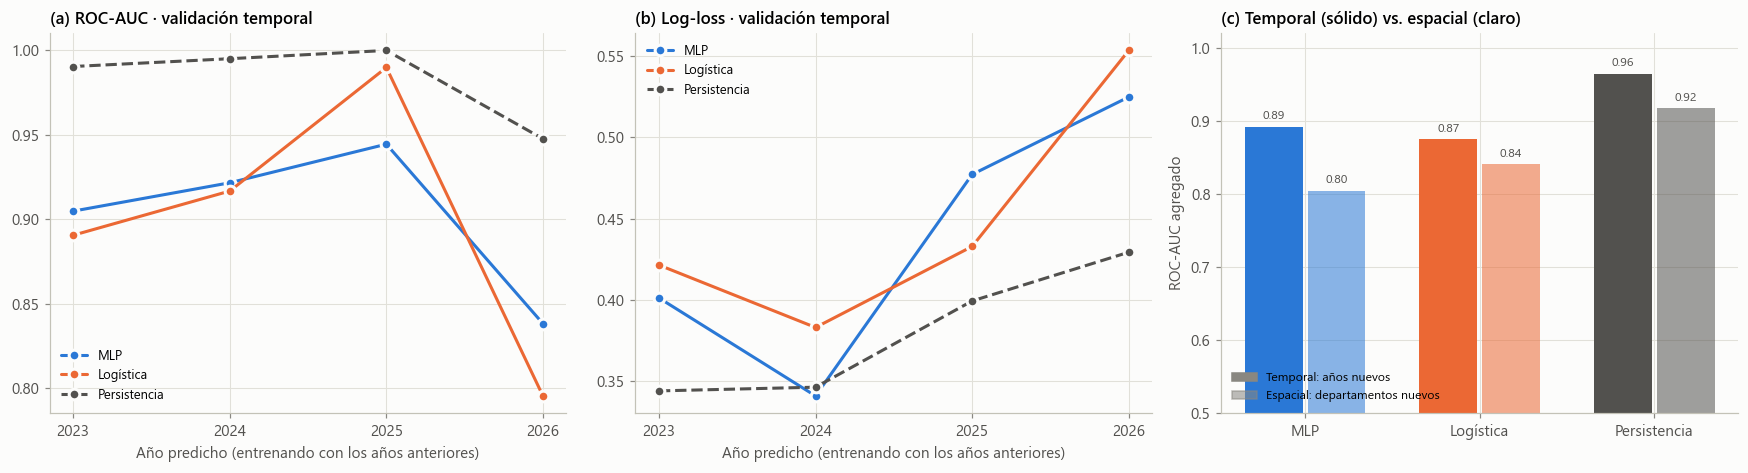

In [36]:
# =============================================================================
# 11.3a-b Validación temporal de origen móvil y validación espacial por departamentos
# =============================================================================
def entrenar_fijo(Xa, ya, semilla=SEED, cfg=None):
    """Entrenamiento sin validación: presupuesto fijo de PASOS_REF pasos de gradiente (η constante)."""
    cfg = cfg or CFG
    epocas = max(1, math.ceil(PASOS_REF / math.ceil(len(ya) / cfg.batch)))
    return entrenar_mlp(Xa, ya, cfg=cfg, semilla=semilla, epocas=epocas, diagnostico=False)[3]

def evaluar_particion(tr, te_, columnas, semillas=(SEED,)):
    esc = StandardScaler().fit(datos.loc[tr, columnas])
    Xa, Xb = esc.transform(datos.loc[tr, columnas]), esc.transform(datos.loc[te_, columnas])
    ya, yb = datos.loc[tr, "y"].values.astype("float32"), datos.loc[te_, "y"].values
    s = datos.loc[te_, "s_C_prev"].values.astype(float)
    return yb, {"MLP": np.mean([entrenar_fijo(Xa, ya, semilla=k)(Xb) for k in semillas], axis=0),
                "Logística": LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000).fit(Xa, ya).predict_proba(Xb)[:, 1],
                "Persistencia": np.where(np.isnan(s), ya.mean(), s)}

def validacion(tipo="temporal", columnas=None, semillas=(SEED,)):
    columnas = columnas or FEATURES
    if tipo == "temporal":
        particiones_ = [(f"{v}", (datos.anio < v).values, (datos.anio == v).values) for v in (2023, 2024, 2025, 2026)]
    else:
        gkf = GroupKFold(n_splits=5)
        particiones_ = [(f"pliegue {k + 1}", np.isin(np.arange(len(datos)), a), np.isin(np.arange(len(datos)), b))
                        for k, (a, b) in enumerate(gkf.split(datos, datos["y"], groups=datos["depto"]))]
    filas, oos = [], []
    for nombre, tr, te_ in particiones_:
        yb, preds = evaluar_particion(tr, te_, columnas, semillas)
        for mod, p in preds.items():
            filas.append({"Partición": nombre, "Modelo": mod, "n": len(yb), **metricas(yb, p)})
        oos.append(pd.DataFrame({"particion": nombre, "fila": np.where(te_)[0], "y": yb, **preds}))
    return pd.DataFrame(filas), pd.concat(oos, ignore_index=True)

t0 = time.time()
VT, OOS_T = validacion("temporal")
VE, OOS_E = validacion("espacial")
print(f"Validaciones temporal y espacial en {time.time() - t0:.0f} s")

def agregado(oos):
    return pd.DataFrame({m: metricas(oos["y"], oos[m]) for m in ["MLP", "Logística", "Persistencia"]}).T

cols_g = ["Exactitud", "Exact. balanceada", "F1 C", "MCC", "ROC-AUC", "Log-loss", "Brier"]
print("Validación temporal (predicciones fuera de muestra 2023-2026, agregadas):")
tabla(agregado(OOS_T)[cols_g], dec=3)
print("Validación espacial (departamentos nunca vistos, agregadas):")
tabla(agregado(OOS_E)[cols_g], dec=3)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, met in zip(axes[:2], ["ROC-AUC", "Log-loss"]):
    for mod, color, ls in [("MLP", COL["mlp"], "-"), ("Logística", COL["logit"], "-"), ("Persistencia", COL["pers"], "--")]:
        s = VT[VT.Modelo == mod]
        ax.plot(s["Partición"], s[met], color=color, ls=ls, marker="o", ms=7, mec=FONDO, mew=2, label=mod)
    ax.set_xlabel("Año predicho (entrenando con los años anteriores)"); ax.set_title(f"({'ab'[axes.tolist().index(ax)]}) {met} · validación temporal")
    ax.legend(fontsize=8.5)
ax = axes[2]
agT, agE = agregado(OOS_T), agregado(OOS_E)
x = np.arange(3); ancho = 0.36
for k, (ag, nombre, alpha) in enumerate([(agT, "Temporal", 1.0), (agE, "Espacial", 0.55)]):
    ax.bar(x + (k - .5) * ancho, ag.loc[["MLP", "Logística", "Persistencia"], "ROC-AUC"], width=ancho * 0.92,
           color=[COL["mlp"], COL["logit"], COL["pers"]], alpha=alpha, label=nombre)
    for xi, v in zip(x + (k - .5) * ancho, ag.loc[["MLP", "Logística", "Persistencia"], "ROC-AUC"]):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color=TINTA2)
ax.set_xticks(x, ["MLP", "Logística", "Persistencia"]); ax.set_ylim(0.5, 1.02); ax.set_ylabel("ROC-AUC agregado")
ax.set_title("(c) Temporal (sólido) vs. espacial (claro)")
ax.legend(handles=[Patch(color=TENUE, alpha=1, label="Temporal: años nuevos"), Patch(color=TENUE, alpha=0.55, label="Espacial: departamentos nuevos")], fontsize=8, loc="lower left")
fig.tight_layout(); guardar(fig, "fig17_generalizacion_temporal_espacial"); plt.show()

**Diagnóstico de generalización.**

* **Temporal (años nuevos): aceptable.** Con las predicciones 2023–2026 agregadas (116 departamento–año nunca
  vistos), el MLP logra AUC 0,89, exactitud 0,80 y log-loss 0,44, a la par o por encima de la logística. Por año, la
  red supera a la logística en 2023, 2024 y 2026 y pierde en 2025. Ese es el año del cambio de prevalencia: la
  logística ordena casi perfecto (AUC 0,99), mientras la red, sin memoria, se pierde a los departamentos que
  escalaron.
* **Espacial (departamentos nuevos): débil.** Cuando el departamento de prueba no aparece en ningún año del
  entrenamiento, el AUC del MLP cae a 0,80 (−0,09) y la log-loss sube a 0,58, mientras la logística cae menos (0,84).
  Es la advertencia de §5.2 confirmada: con 30 departamentos y variables estructurales casi constantes, la red usa su
  flexibilidad para ajustar **firmas departamentales** que no se transfieren. Para el objetivo final del proyecto,
  clasificar municipios que el modelo no ha visto, esta es la limitación más importante.
* **La persistencia domina en ambos ejes** (AUC 0,96 temporal y 0,92 espacial) porque usa la historia propia de cada
  territorio, algo que ningún modelo con solo variables estructurales puede alcanzar. La pregunta útil deja de ser si la red
  le gana a la inercia. Pasa a ser si la red, con memoria, anticipa mejor los cambios que la inercia no ve (§13).

Curvas de tamaño de muestra y capacidad en 36 s


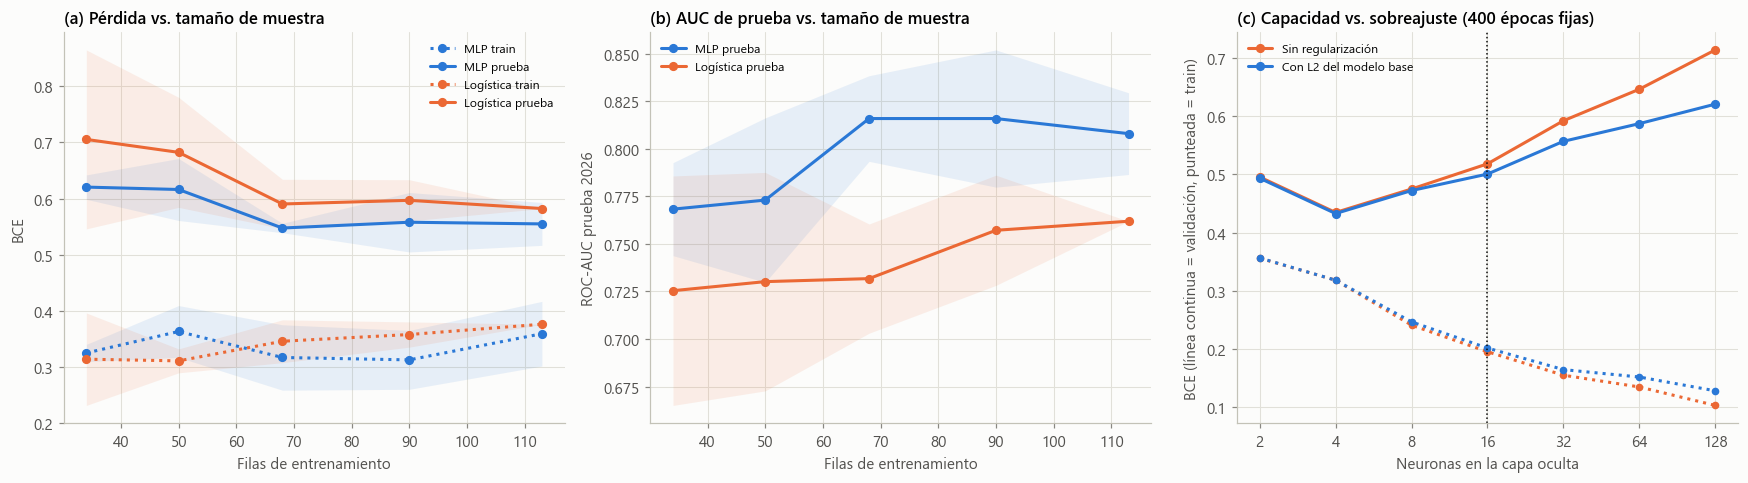

In [37]:
# =============================================================================
# 11.3c-d Diagnóstico sesgo–varianza: tamaño de muestra y capacidad
# =============================================================================
t0 = time.time()
# (c) Curva de aprendizaje por tamaño de muestra: submuestras estratificadas del entrenamiento 2021-2024
FRACCIONES, REPETICIONES = [0.3, 0.45, 0.6, 0.8, 1.0], 3
idx0, idx1 = np.where(ytr == 0)[0], np.where(ytr == 1)[0]
filas = []
for f in FRACCIONES:
    for r in range(REPETICIONES):
        rg = np.random.default_rng(1000 + r)
        sub = np.concatenate([rg.choice(idx0, int(round(f * len(idx0))), replace=False),
                              rg.choice(idx1, int(round(f * len(idx1))), replace=False)])
        _, _, _, pr = entrenar_mlp(Xtr[sub], ytr[sub], Xva, yva, cfg=CFG, semilla=SEED + r, diagnostico=False)
        lr_ = LogisticRegression(C=C_LR, class_weight="balanced", max_iter=5000).fit(Xtr[sub], ytr[sub])
        filas.append({"n": len(sub), "MLP train": bce(ytr[sub], pr(Xtr[sub])), "MLP prueba": bce(yte, pr(Xte)),
                      "Logística train": bce(ytr[sub], lr_.predict_proba(Xtr[sub])[:, 1]),
                      "Logística prueba": bce(yte, lr_.predict_proba(Xte)[:, 1]), "AUC MLP prueba": roc_auc_score(yte, pr(Xte)),
                      "AUC Logística prueba": roc_auc_score(yte, lr_.predict_proba(Xte)[:, 1])})
CURVA_N = pd.DataFrame(filas).groupby("n").agg(["mean", "std"])

# (d) Capacidad: una capa oculta de 2 a 128 neuronas, con y sin regularización, épocas fijas
UNIDADES, EPOCAS_CAP = [2, 4, 8, 16, 32, 64, 128], 400
filas = []
for u in UNIDADES:
    for regimen, cfg_r in [("Sin regularización", ConfigMLP(capas=(u,), l2=0.0, dropout=0.0)),
                           ("Con L2 del modelo base", ConfigMLP(capas=(u,), l2=CFG.l2, dropout=CFG.dropout))]:
        for s in (1, 2):
            _, _, _, pr = entrenar_mlp(Xtr, ytr, cfg=cfg_r, semilla=s, epocas=EPOCAS_CAP, diagnostico=False)
            filas.append({"unidades": u, "régimen": regimen, "semilla": s, "BCE train": bce(ytr, pr(Xtr)), "BCE validación": bce(yva, pr(Xva))})
CAPACIDAD = pd.DataFrame(filas).groupby(["régimen", "unidades"])[["BCE train", "BCE validación"]].mean().reset_index()
print(f"Curvas de tamaño de muestra y capacidad en {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ax = axes[0]; nn = CURVA_N.index.values
for col, color, ls in [("MLP train", COL["mlp"], ":"), ("MLP prueba", COL["mlp"], "-"), ("Logística train", COL["logit"], ":"), ("Logística prueba", COL["logit"], "-")]:
    m_, s_ = CURVA_N[(col, "mean")].values, CURVA_N[(col, "std")].fillna(0).values
    ax.plot(nn, m_, color=color, ls=ls, marker="o", ms=5, label=col); ax.fill_between(nn, m_ - s_, m_ + s_, color=color, alpha=0.1, lw=0)
ax.set_xlabel("Filas de entrenamiento"); ax.set_ylabel("BCE"); ax.set_title("(a) Pérdida vs. tamaño de muestra"); ax.legend(fontsize=8)
ax = axes[1]
for col, color in [("AUC MLP prueba", COL["mlp"]), ("AUC Logística prueba", COL["logit"])]:
    m_, s_ = CURVA_N[(col, "mean")].values, CURVA_N[(col, "std")].fillna(0).values
    ax.plot(nn, m_, color=color, marker="o", ms=5, label=col.replace("AUC ", "")); ax.fill_between(nn, m_ - s_, m_ + s_, color=color, alpha=0.1, lw=0)
ax.set_xlabel("Filas de entrenamiento"); ax.set_ylabel("ROC-AUC prueba 2026"); ax.set_title("(b) AUC de prueba vs. tamaño de muestra"); ax.legend(fontsize=8)
ax = axes[2]
for regimen, color in [("Sin regularización", COL["logit"]), ("Con L2 del modelo base", COL["mlp"])]:
    s = CAPACIDAD[CAPACIDAD["régimen"] == regimen]
    ax.plot(s["unidades"], s["BCE train"], color=color, ls=":", marker="o", ms=4)
    ax.plot(s["unidades"], s["BCE validación"], color=color, marker="o", ms=5, label=regimen)
ax.axvline(CFG.capas[0], color=TINTA, lw=1, ls=":"); ax.set_xscale("log", base=2); ax.set_xticks(UNIDADES, UNIDADES)
ax.set_xlabel("Neuronas en la capa oculta"); ax.set_ylabel("BCE (línea continua = validación, punteada = train)")
ax.set_title(f"(c) Capacidad vs. sobreajuste ({EPOCAS_CAP} épocas fijas)"); ax.legend(fontsize=8)
fig.tight_layout(); guardar(fig, "fig18_sesgo_varianza"); plt.show()

**Diagnóstico sesgo–varianza.**

* **(a–b) Tamaño de muestra.** Al crecer el entrenamiento, la BCE de entrenamiento sube ligeramente (memoriza menos) y
  la de prueba baja (0,62 → 0,55 en el MLP; 0,71 → 0,58 en la logística). Con 113 filas las curvas **no se han
  juntado** (brecha ≈0,2), el patrón de un modelo limitado por **varianza**: más datos ayudarían. El MLP queda por
  debajo de la logística en BCE de prueba y por encima en AUC en todos los tamaños, pero su mejora se aplana entre 68
  y 113 filas. Agregar años de los *mismos* 30 departamentos aporta poca información nueva, porque las filas de un
  mismo departamento están muy correlacionadas. Lo que falta son **unidades nuevas** (municipios), más que años
  nuevos.
* **(c) Capacidad.** Con 400 épocas fijas y sin parada temprana, la BCE de validación es mínima con 4 neuronas (0,43)
  y crece de forma sostenida con la capacidad: 0,50 con 16 y 0,71 con 128, mientras la de entrenamiento baja de 0,36 a
  0,10. Es la firma clásica del sobreajuste: la capacidad extra se usa para memorizar. El L2 de 10⁻³ lo atenúa en
  redes grandes (0,62 frente a 0,71 con 128 neuronas), pero es débil. En el modelo base la regularización efectiva la
  hace la **parada temprana**, que detiene el entrenamiento entre las épocas 45 y 70, antes de que la capacidad se vuelva
  dañina. Esto justifica explorar en la siguiente iteración capas de 4–8 neuronas o un L2 mayor (M7).

## 11.4 ¿Aporta la no linealidad? Red vs. neurona lineal

La Etapa 1 (§6.3) dejó una hipótesis explícita: *la frontera entre perfiles no es un hiperplano, y por eso una red
debería superar a la regresión logística*. La contrastamos de dos formas:

* **Pruebas pareadas** sobre las mismas predicciones fuera de muestra (temporales y espaciales): prueba exacta de
  McNemar sobre los aciertos (Dietterich, 1998) e intervalos bootstrap pareados para la diferencia de AUC y de
  entropía cruzada.
* **Superficies de dependencia parcial** (Friedman, 2001) para los dos pares de interacción planteados en la Etapa 1:
  bosque × distancia y coca × pobreza.

In [38]:
# =============================================================================
# 11.4a Pruebas pareadas MLP vs. logística sobre predicciones fuera de muestra
# =============================================================================
def comparar_pareado(oos, a="MLP", b="Logística", n_boot=2000, semilla=SEED):
    y = oos["y"].values.astype(int); pa, pb = oos[a].values, oos[b].values
    ok_a, ok_b = (pa >= .5) == y, (pb >= .5) == y
    n01, n10 = int(np.sum(ok_a & ~ok_b)), int(np.sum(~ok_a & ok_b))
    p_mcnemar = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if (n01 + n10) else 1.0
    rng = np.random.default_rng(semilla); d_auc, d_bce = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2:
            continue
        d_auc.append(roc_auc_score(y[i], pa[i]) - roc_auc_score(y[i], pb[i])); d_bce.append(bce(y[i], pa[i]) - bce(y[i], pb[i]))
    return {"n": len(y), f"solo {a} acierta": n01, f"solo {b} acierta": n10, "p McNemar (exacta)": p_mcnemar,
            "ΔAUC (MLP − Log.)": roc_auc_score(y, pa) - roc_auc_score(y, pb), "IC95 ΔAUC": np.percentile(d_auc, [2.5, 97.5]).round(3).tolist(),
            "ΔBCE (MLP − Log.)": bce(y, pa) - bce(y, pb), "IC95 ΔBCE": np.percentile(d_bce, [2.5, 97.5]).round(3).tolist()}

PAREADO = pd.DataFrame({"Temporal 2023-2026": comparar_pareado(OOS_T), "Espacial (5 pliegues)": comparar_pareado(OOS_E)}).T
display(PAREADO)

,n,solo MLP acierta,solo Logística acierta,p McNemar (exacta),ΔAUC (MLP − Log.),IC95 ΔAUC,ΔBCE (MLP − Log.),IC95 ΔBCE
Temporal 2023-2026,116,5,5,1.0,0.017539,"[-0.01, 0.045]",-0.011686,"[-0.057, 0.042]"
Espacial (5 pliegues),171,4,7,0.548828,-0.036448,"[-0.064, -0.013]",0.072559,"[0.028, 0.128]"


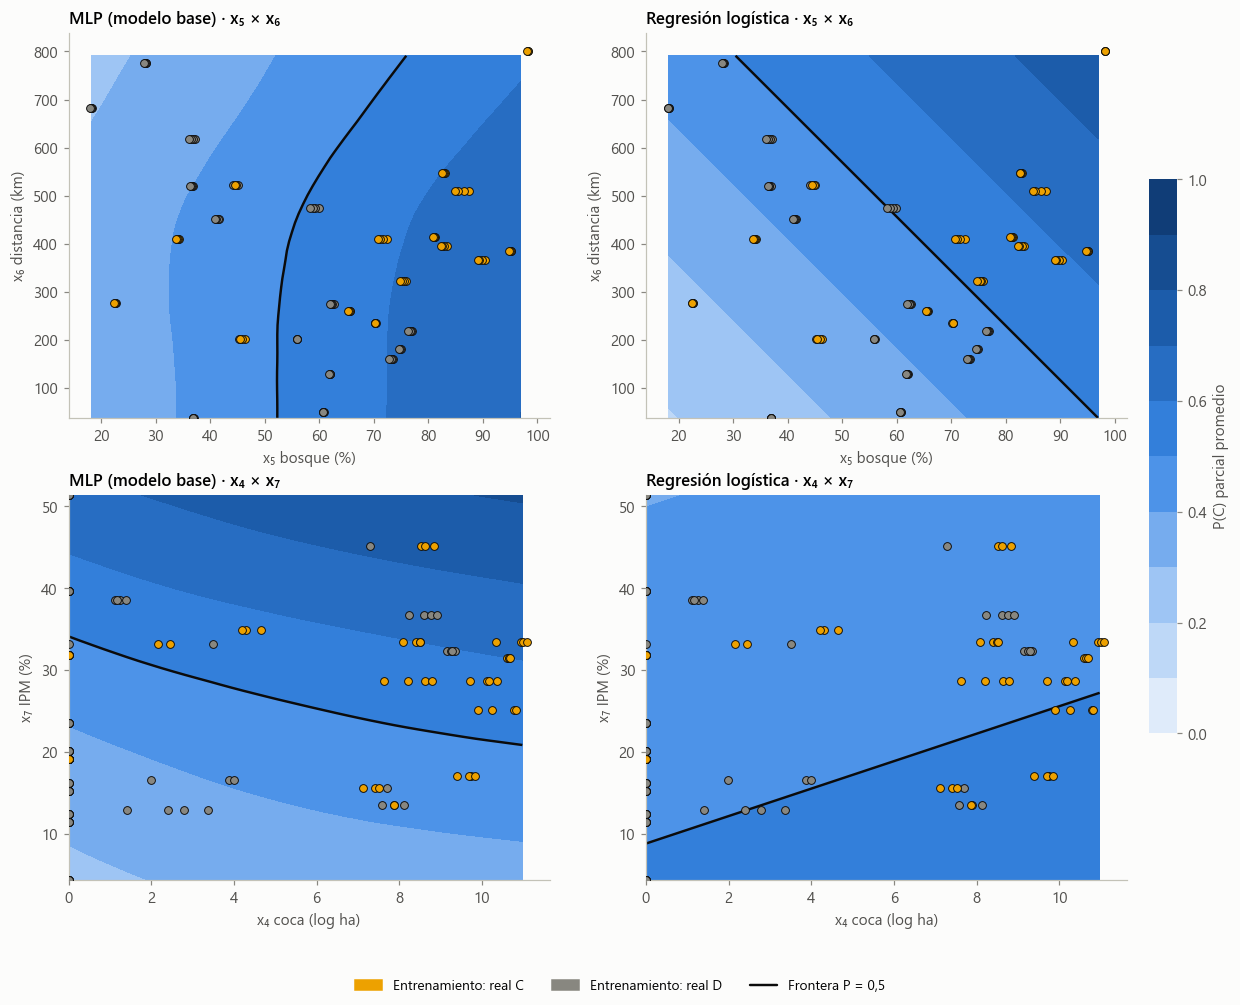

In [39]:
# =============================================================================
# 11.4b Superficies de dependencia parcial (PDP 2D): MLP vs. logística
# =============================================================================
def pdp_2d(pred_fn, esc, fx, fy, n=40):
    """PDP: promedio de P(C) sobre las filas de entrenamiento, fijando (fx, fy) en cada punto de la rejilla."""
    base = datos.loc[m_tr, FEATURES].reset_index(drop=True)
    gx = np.linspace(*datos[fx].quantile([.02, .98]), n); gy = np.linspace(*datos[fy].quantile([.02, .98]), n)
    GX, GY = np.meshgrid(gx, gy)
    rep = pd.concat([base] * (n * n), ignore_index=True)
    rep[fx] = np.repeat(GX.ravel(), len(base)); rep[fy] = np.repeat(GY.ravel(), len(base))
    Z = pred_fn(esc.transform(rep[FEATURES]).astype("float32")).reshape(n * n, len(base)).mean(axis=1).reshape(n, n)
    return gx, gy, Z

pred_lr_fn = lambda X: logit.predict_proba(X)[:, 1]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for fila, (fx, fy) in enumerate([("x5_bosque", "x6_distancia"), ("x4_coca", "x7_ipm")]):
    for colm, (nombre, fn) in enumerate([("MLP (modelo base)", predecir), ("Regresión logística", pred_lr_fn)]):
        ax = axes[fila, colm]
        gx, gy, Z = pdp_2d(fn, escalador, fx, fy)
        cs = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap=CMAP_P, vmin=0, vmax=1)
        ax.contour(gx, gy, Z, levels=[0.5], colors=TINTA, linewidths=1.6)
        for clase, color in [(0, COL["D"]), (1, COL["C"])]:
            s = datos[m_tr & (datos.y == clase).values]
            ax.scatter(s[fx], s[fy], s=26, color=color, edgecolor=TINTA, lw=0.6, zorder=3)
        ax.grid(False); ax.set_xlabel(ETIQ[fx]); ax.set_ylabel(ETIQ[fy])
        ax.set_title(f"{nombre} · {ETIQ[fx].split(' ')[0]} × {ETIQ[fy].split(' ')[0]}")
cb = fig.colorbar(cs, ax=axes, fraction=0.025, pad=0.02); cb.set_label("P(C) parcial promedio"); cb.outline.set_visible(False)
fig.legend(handles=[Patch(color=COL["C"], label="Entrenamiento: real C"), Patch(color=COL["D"], label="Entrenamiento: real D"),
                    Line2D([], [], color=TINTA, lw=1.6, label="Frontera P = 0,5")], loc="lower center", ncol=3, fontsize=9)
guardar(fig, "fig19_dependencia_parcial"); plt.show()

**¿Se confirma la hipótesis de no linealidad de la Etapa 1?**

* **En desempeño, no a esta escala.** En el eje temporal la red y la logística empatan: cada una acierta 5 casos que
  la otra falla (McNemar p = 1,0), y la diferencia de AUC (+0,018) tiene un intervalo que incluye el cero
  [−0,010; 0,045]. En el eje espacial la logística es **significativamente mejor** (ΔAUC −0,036 [−0,064; −0,013];
  ΔBCE +0,073 [0,028; 0,128]), coherente con el diagnóstico de varianza.
* **En la forma, sí.** Las superficies de dependencia parcial muestran que la red aprende fronteras curvas y coherentes
  con las hipótesis de la Etapa 1, donde la logística solo puede trazar rectas:
  * *Bosque × distancia.* Para la red, el bosque es el eje principal, con un umbral cercano al 50 % de cobertura, y
    la distancia solo desplaza ese umbral en los departamentos más alejados. La logística impone una diagonal en la
    que distancia y bosque son sustitutos perfectos.
  * *Coca × pobreza.* Para la red, más pobreza y más coca empujan hacia C, y la frontera se curva: con mucha coca
    basta menos pobreza. Es justo la interacción entre economía ilícita y vulnerabilidad que planteó la Etapa 1. La
    logística traza una frontera con **pendiente contraria** (más IPM, menos C) por el signo negativo que le impuso la
    colinealidad con la distancia (§6.2).
* **Conclusión:** la hipótesis no queda refutada, pero tampoco confirmada. La red *representa* las interacciones que
  la Etapa 1 anticipó, pero con 30 unidades espaciales esa flexibilidad no se traduce todavía en mejor predicción fuera
  de muestra, porque el costo en varianza la compensa. La no linealidad empezará a rendir cuando haya suficientes
  unidades para estimarla, y ese es un argumento cuantitativo a favor de migrar a municipio.

## 11.5 Interpretabilidad y análisis de errores

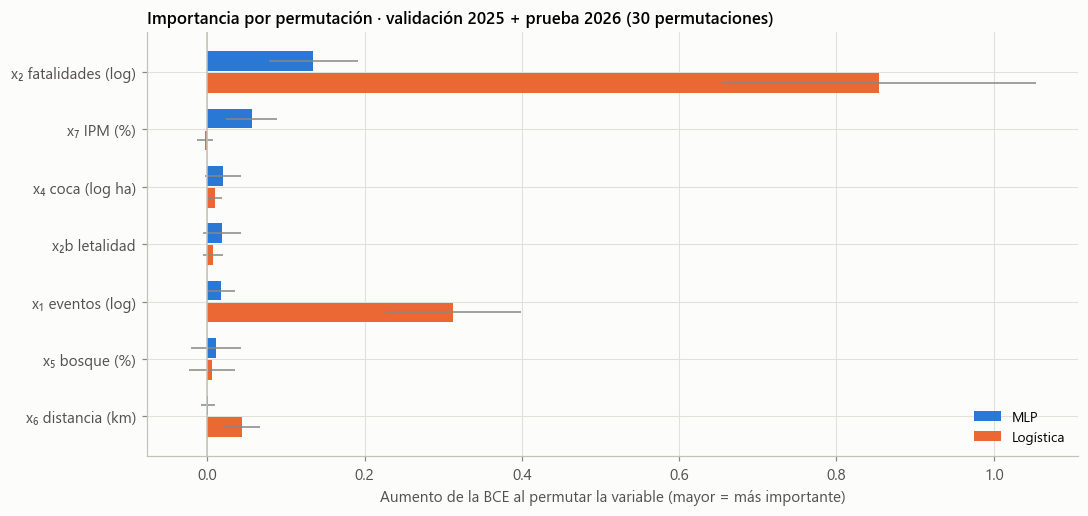

In [40]:
# =============================================================================
# 11.5a Importancia por permutación (aumento de la BCE al romper cada variable) en validación + prueba
# =============================================================================
def importancia_perm(pred_fn, X, y, n_rep=30, semilla=SEED):
    rng = np.random.default_rng(semilla); base = bce(y, pred_fn(X)); res = {}
    for j, f in enumerate(FEATURES):
        d = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j]); d.append(bce(y, pred_fn(Xp)) - base)
        res[ETIQ[f]] = (np.mean(d), np.std(d))
    return pd.DataFrame(res, index=["ΔBCE media", "Desv. est."]).T

X_fuera = np.vstack([Xva, Xte])
IMP = pd.concat({"MLP": importancia_perm(predecir, X_fuera, y_fuera), "Logística": importancia_perm(pred_lr_fn, X_fuera, y_fuera)}, axis=1)
orden_i = IMP[("MLP", "ΔBCE media")].sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.8))
yy = np.arange(len(orden_i)); h = 0.38
ax.barh(yy + h / 2, IMP.loc[orden_i, ("MLP", "ΔBCE media")], xerr=IMP.loc[orden_i, ("MLP", "Desv. est.")], height=h * 0.9,
        color=COL["mlp"], label="MLP", error_kw=dict(ecolor=TENUE, lw=1))
ax.barh(yy - h / 2, IMP.loc[orden_i, ("Logística", "ΔBCE media")], xerr=IMP.loc[orden_i, ("Logística", "Desv. est.")], height=h * 0.9,
        color=COL["logit"], label="Logística", error_kw=dict(ecolor=TENUE, lw=1))
ax.axvline(0, color=EJE, lw=1); ax.set_yticks(yy, orden_i)
ax.set_xlabel("Aumento de la BCE al permutar la variable (mayor = más importante)")
ax.set_title("Importancia por permutación · validación 2025 + prueba 2026 (30 permutaciones)"); ax.legend(fontsize=9, loc="lower right")
fig.tight_layout(); guardar(fig, "fig20_importancia_permutacion"); plt.show()
tabla(IMP, dec=4)

departamento,anio,perfil,s_C,perfil_prev,s_C_prev,eventos,P(C) MLP,predicho,acierto,transición,cerca del umbral
Meta,2025,C,0.67,D,0.42,83,0.17,D,False,True,False
Casanare,2025,C,0.67,C,0.81,27,0.21,D,False,False,False
Magdalena,2025,C,0.56,D,0.40,131,0.28,D,False,True,True
Cesar,2025,C,0.53,D,0.42,137,0.29,D,False,True,True
Córdoba,2025,C,0.55,D,0.48,131,0.32,D,False,True,True
Arauca,2025,C,0.72,C,0.87,247,0.36,D,False,False,False
Valle del Cauca,2025,C,0.52,D,0.44,394,0.47,D,False,True,True
Casanare,2026,C,0.58,C,0.67,19,0.18,D,False,False,True
Cesar,2026,C,0.67,C,0.53,87,0.30,D,False,False,False
Meta,2026,C,0.55,C,0.67,56,0.33,D,False,False,True


,Errores,Aciertos
% que son transición de perfil (t-1 ≠ t),"0,57","0,05"
% con s_C a ±10 pp del umbral,"0,57","0,18"
Mediana de eventos en t,"131,00","72,00"


Transiciones de perfil en validación + prueba: 10 | acertadas por el MLP: 2 | acertadas por la persistencia: 0 (por construcción)


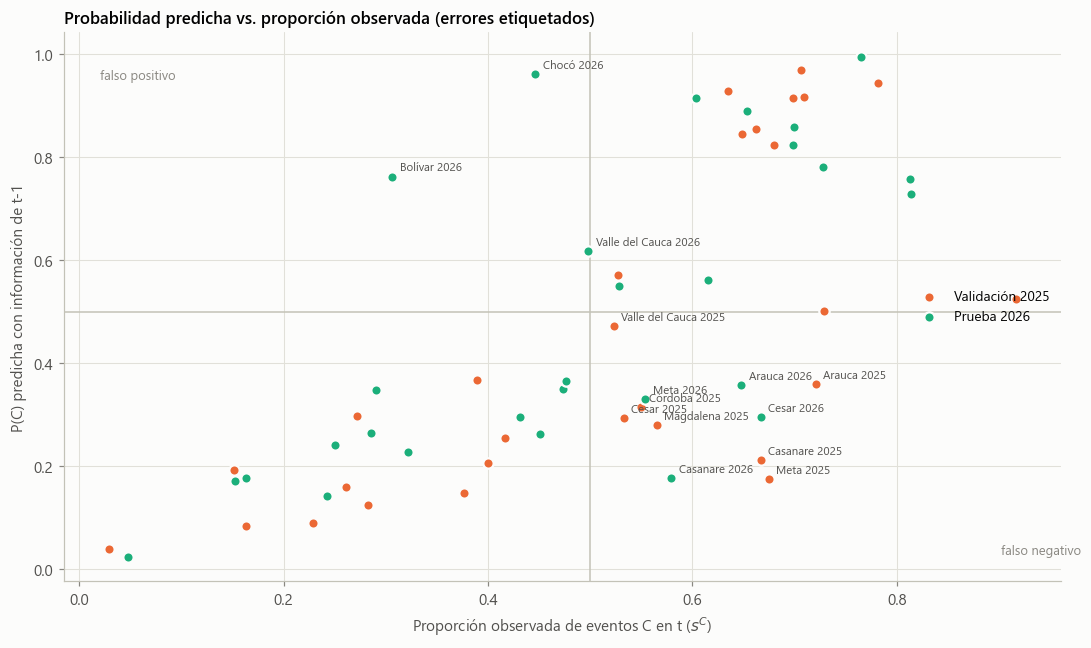

In [41]:
# =============================================================================
# 11.5b Análisis de errores: ¿dónde se equivoca el modelo?
# =============================================================================
cols_err = ["departamento", "anio", "perfil", "s_C", "perfil_prev", "s_C_prev", "eventos"]
fuera = pd.concat([datos.loc[m_va, cols_err], datos.loc[m_te, cols_err]])      # mismo orden que [val, prueba]
fuera["P(C) MLP"] = np.concatenate([P[("MLP fase 1", "Validación")], P[("MLP fase 1", "Prueba")]])
fuera["predicho"] = np.where(fuera["P(C) MLP"] >= .5, "C", "D")
fuera["acierto"] = fuera["predicho"] == fuera["perfil"]
fuera["transición"] = fuera["perfil"] != fuera["perfil_prev"]
fuera["cerca del umbral"] = (fuera["s_C"] - .5).abs() < .10
errores = fuera[~fuera["acierto"]].sort_values(["anio", "P(C) MLP"])
display(errores.style.format({"s_C": "{:.2f}", "s_C_prev": "{:.2f}", "P(C) MLP": "{:.2f}"}).hide(axis="index"))
perfil_err = pd.DataFrame({"Errores": [errores["transición"].mean(), errores["cerca del umbral"].mean(), errores["eventos"].median()],
                           "Aciertos": [fuera.loc[fuera.acierto, "transición"].mean(), fuera.loc[fuera.acierto, "cerca del umbral"].mean(),
                                        fuera.loc[fuera.acierto, "eventos"].median()]},
                          index=["% que son transición de perfil (t-1 ≠ t)", "% con s_C a ±10 pp del umbral", "Mediana de eventos en t"])
tabla(perfil_err, dec=2)
trans_f = fuera[fuera["transición"]]
print(f"Transiciones de perfil en validación + prueba: {len(trans_f)} | acertadas por el MLP: {int(trans_f['acierto'].sum())} "
      f"| acertadas por la persistencia: 0 (por construcción)")

fig, ax = plt.subplots(figsize=(10, 6))
for anio, color, et in [(ANIO_VAL, COL["val"], "Validación 2025"), (ANIO_TEST, COL["test"], "Prueba 2026")]:
    s = fuera[fuera.anio == anio]
    ax.scatter(s["s_C"], s["P(C) MLP"], s=46, color=color, edgecolor=FONDO, lw=1.5, label=et, zorder=3)
ax.axvline(.5, color=EJE, lw=1); ax.axhline(.5, color=EJE, lw=1)
for _, r in errores.iterrows():
    ax.annotate(f"{r['departamento']} {r['anio']}", (r["s_C"], r["P(C) MLP"]), xytext=(5, 4), textcoords="offset points", fontsize=7.5, color=TINTA2)
ax.text(0.02, 0.97, "falso positivo", fontsize=8.5, color=TENUE, va="top"); ax.text(0.98, 0.03, "falso negativo", fontsize=8.5, color=TENUE, ha="right")
ax.set_xlabel("Proporción observada de eventos C en t ($s^C$)"); ax.set_ylabel("P(C) predicha con información de t-1")
ax.set_title("Probabilidad predicha vs. proporción observada (errores etiquetados)"); ax.legend(fontsize=9, loc="center right")
fig.tight_layout(); guardar(fig, "fig21_analisis_errores"); plt.show()

**Lectura del análisis de errores.**

* **Los errores no son aleatorios.** De los 14 errores en validación y prueba, el 57 % son **transiciones de perfil**
  (el departamento cambió respecto al año anterior), frente al 5 % entre los aciertos. Y el 57 % tiene una proporción C
  a menos de 10 puntos del umbral, frente al 18 % de los aciertos. El modelo falla donde la etiqueta es ambigua o donde
  el territorio cambia de régimen.
* **2025, año de escalamiento.** Los 7 errores son departamentos C clasificados como D, y cinco son transiciones D → C
  (Meta, Magdalena, Cesar, Córdoba y Valle del Cauca) en el año de la ruptura de los diálogos. Es un cambio de
  coyuntura nacional que las condiciones estructurales de 2024 no anticipan.
* **Errores estructurales persistentes.** Arauca es C los seis años y el modelo le da P ≈ 0,36. Su perfil convencional
  no se explica por coca o selva (no tiene coca y tiene 34 % de bosque), sino por la presencia del ELN en la frontera
  con Venezuela, una variable que el modelo no tiene: es exactamente $x_3$ (actores armados), pendiente desde la Etapa
  1. El error apunta a la variable faltante.
* **2026, falsos positivos.** Valle del Cauca, Bolívar y Chocó pasaron de C a D en los primeros ocho meses de 2026 y el
  modelo los mantuvo en C.
* **Transiciones acertadas.** De las 10 transiciones en validación y prueba, el MLP anticipa 2; la persistencia,
  ninguna, por construcción. Ese es el nicho de valor de un modelo estructural, y la razón para combinarlo con la
  memoria del perfil en lugar de reemplazar uno por otro.

## 11.6 Síntesis del diagnóstico

| Dimensión | Evidencia principal | Veredicto |
|---|---|---|
| **Convergencia** | BCE monótona y en meseta (pendiente −2×10⁻⁴ por época); gradiente estable; razón de actualización ≈10⁻³ dentro de la banda; equivalencia exacta con Keras | ✅ Converge a un mínimo estable; el límite no es la optimización |
| **Estabilidad** | CV del AUC de prueba 2,8 % entre 10 semillas; época óptima variable (CV 35 %) en un valle plano; 66 % de predicciones unánimes | ✅ Estable en métricas · ⚠️ sensible en casos frontera → ensamble |
| **Generalización temporal** | AUC 0,89 fuera de muestra 2023–2026; degradación entrenamiento → validación → prueba; el reajuste con 2025 mejora | ✅ Aceptable · ⚠️ deriva y cambio de prevalencia (2025) |
| **Generalización espacial** | AUC 0,80 en departamentos nunca vistos (logística 0,84) | ⚠️ Débil: memoriza firmas departamentales (varianza) |
| **Sesgo–varianza** | Brecha entrenamiento–prueba ≈0,2 sin cerrar; sobreajuste creciente con la capacidad | ⚠️ Limitado por varianza: faltan unidades, no capacidad |
| **No linealidad** | Fronteras curvas coherentes con la U1, sin ventaja significativa en desempeño | ⚠️ Presente en la forma, no rentable todavía con n = 171 |
| **Frente a la inercia** | Persistencia AUC 0,96; 57 % de los errores son transiciones | ❌ No la supera sin memoria · ✅ con memoria (E1) la supera en log-loss |

---
# 12. Del modelo a la decisión: perfil proyectado 2027

Cerramos el ciclo con la pregunta de la Etapa 1. Para una salida operativa reentrenamos el modelo con **todas** las
etiquetas disponibles (2021–2026), con la configuración validada y el presupuesto de entrenamiento de §11.2
(560 pasos de gradiente), y promediamos **5 semillas** (el ensamble reduce la varianza medida en §11.2 y en E2). Con la información de 2026 (enero–agosto,
anualizada) proyectamos el perfil de 2027 para los 33 departamentos.

La proyección se acompaña de la **alerta A/B** que exige el hallazgo crítico de la Etapa 1 (§5.4). IED y drones no
llegan a dominar ningún departamento, pero su presencia relativa es una señal de alto impacto que la etiqueta
binaria no captura. Marcamos los departamentos cuya proporción de eventos A+B en 2025–2026 supera el doble del
promedio nacional (con al menos 5 eventos A+B).

> Esta salida es un **insumo analítico ilustrativo**, no una recomendación operativa: resume el patrón aprendido de
> datos públicos agregados y debe contrastarse con inteligencia de campo.

In [42]:
# =============================================================================
# 12.1 Modelo de despliegue (ensamble de 5 semillas, 2021-2026) y proyección 2027
# =============================================================================
escalador_all = StandardScaler().fit(datos[FEATURES])
X_all, y_all = escalador_all.transform(datos[FEATURES]).astype("float32"), datos["y"].values.astype("float32")
SEMILLAS_DESPLIEGUE = [SEED, 7, 11, 23, 31]
ensamble = [entrenar_fijo(X_all, y_all, semilla=s) for s in SEMILLAS_DESPLIEGUE]

base27 = pext[pext["anio"] == 2026].copy()
X27 = escalador_all.transform(calcular_features(base27)[FEATURES]).astype("float32")
P27 = np.array([f(X27) for f in ensamble])

ab = panel[panel["anio"] >= 2025].groupby("depto")[["A", "B", "eventos"]].sum()
ab["s_AB"] = (ab["A"] + ab["B"]) / ab["eventos"]
nacional_AB = (ab["A"].sum() + ab["B"].sum()) / ab["eventos"].sum()
ab["alerta_AB"] = (ab["s_AB"] >= 2 * nacional_AB) & ((ab["A"] + ab["B"]) >= 5)

proy = pd.DataFrame({"depto": base27["depto"].values, "Departamento": base27["depto"].map(NOMBRE).values,
                     "lat": base27["lat"].values, "lon": base27["lon"].values,
                     "Eventos 2026 (anualizados)": (base27["eventos"] / base27["semanas"] * 52).round(0).values,
                     "Perfil 2026 observado": base27["perfil"].fillna("–").values,
                     "P(C) 2027": P27.mean(axis=0), "Desv. entre semillas": P27.std(axis=0)})
proy = proy.merge(ab[["s_AB", "alerta_AB"]], left_on="depto", right_index=True, how="left")
proy["Datos suficientes"] = base27["confiable"].values

def categoria(p):
    return ("C consolidado" if p >= 0.7 else "Transición" if p >= 0.3 else "D consolidado")
ENFASIS = {"C consolidado": "ISR, detección temprana y movilidad protegida",
           "Transición": "Portafolio flexible y monitoreo trimestral del perfil",
           "D consolidado": "Orden público y capacidades mixtas"}
proy["Categoría 2027"] = proy["P(C) 2027"].map(categoria)
proy["¿Coincide con la inercia?"] = np.where(proy["Perfil 2026 observado"] == "–", "–",
                                            np.where((proy["P(C) 2027"] >= .5) == (proy["Perfil 2026 observado"] == "C"), "sí", "revisar"))
proy["Énfasis sugerido"] = proy["Categoría 2027"].map(ENFASIS) + np.where(proy["alerta_AB"], " + evaluar C-UAS / detección de AEI", "")
proy = proy.sort_values("P(C) 2027", ascending=False).reset_index(drop=True)
print(f"Proporción nacional de eventos A+B (2025-2026): {nacional_AB:.1%} → umbral de alerta: {2 * nacional_AB:.1%}")
display(proy[["Departamento", "Perfil 2026 observado", "P(C) 2027", "Desv. entre semillas", "Categoría 2027",
              "¿Coincide con la inercia?", "s_AB", "Énfasis sugerido", "Datos suficientes"]]
        .style.format({"P(C) 2027": "{:.2f}", "Desv. entre semillas": "{:.3f}", "s_AB": "{:.1%}"})
        .background_gradient(subset=["P(C) 2027"], cmap=CMAP_P, vmin=0, vmax=1).hide(axis="index"))

Proporción nacional de eventos A+B (2025-2026): 6.4% → umbral de alerta: 12.7%


Departamento,Perfil 2026 observado,P(C) 2027,Desv. entre semillas,Categoría 2027,¿Coincide con la inercia?,s_AB,Énfasis sugerido,Datos suficientes
Guaviare,C,1.00,0.000,C consolidado,sí,14.4%,"ISR, detección temprana y movilidad protegida + evaluar C-UAS / detección de AEI",True
Vaupés,C,0.92,0.100,C consolidado,sí,0.0%,"ISR, detección temprana y movilidad protegida",False
Nariño,C,0.90,0.025,C consolidado,sí,6.8%,"ISR, detección temprana y movilidad protegida",True
Cauca,C,0.87,0.030,C consolidado,sí,13.4%,"ISR, detección temprana y movilidad protegida + evaluar C-UAS / detección de AEI",True
Caquetá,C,0.86,0.011,C consolidado,sí,9.8%,"ISR, detección temprana y movilidad protegida",True
Antioquia,C,0.84,0.040,C consolidado,sí,6.8%,"ISR, detección temprana y movilidad protegida",True
Norte de Santander,C,0.84,0.026,C consolidado,sí,10.2%,"ISR, detección temprana y movilidad protegida",True
Amazonas,C,0.77,0.107,C consolidado,sí,0.0%,"ISR, detección temprana y movilidad protegida",False
Chocó,D,0.75,0.119,C consolidado,revisar,8.0%,"ISR, detección temprana y movilidad protegida",True
Guainía,C,0.72,0.147,C consolidado,sí,0.0%,"ISR, detección temprana y movilidad protegida",False


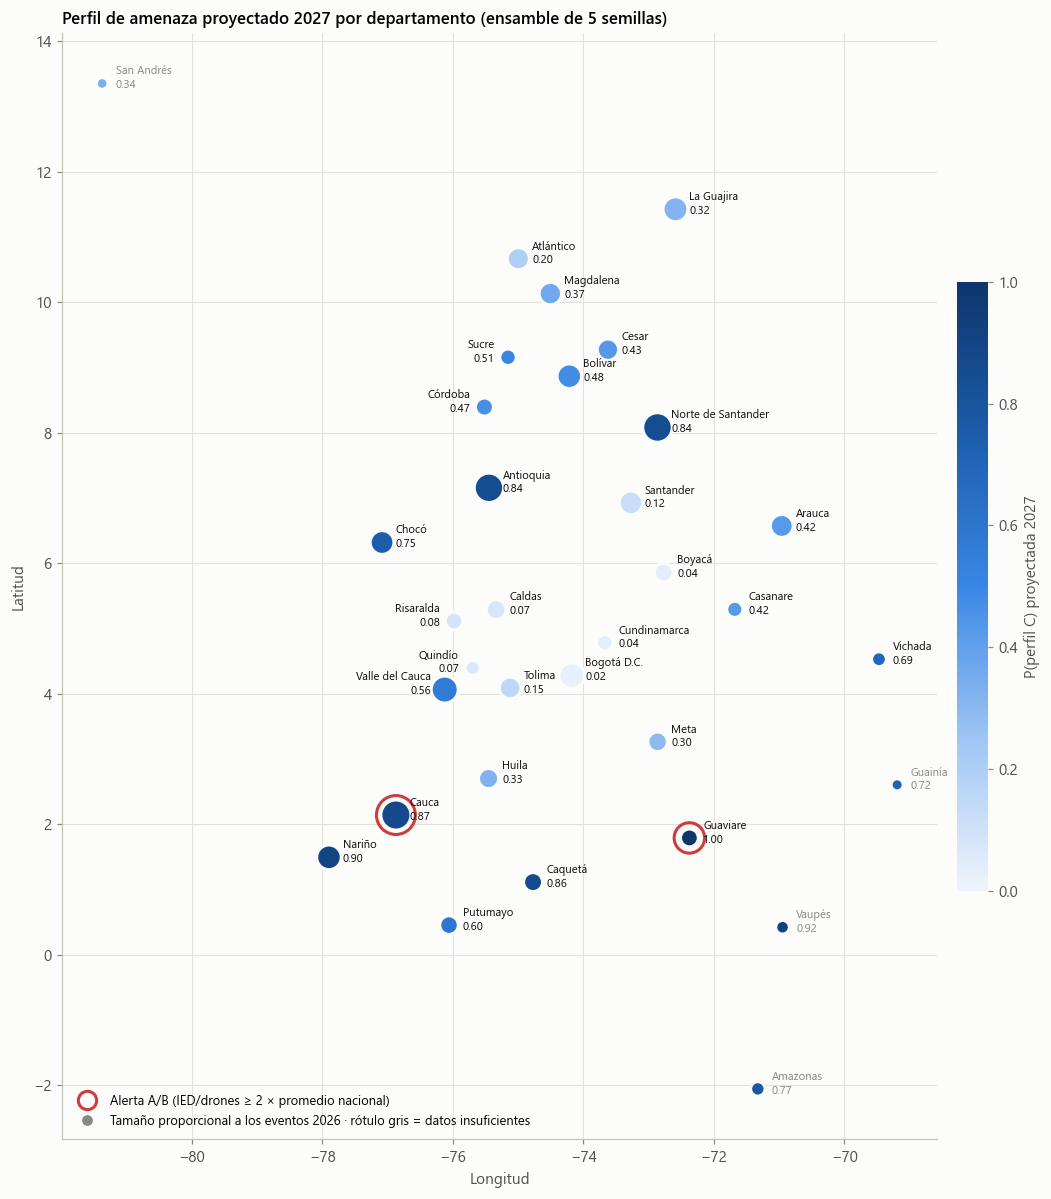

Categoría 2027
Transición       13
C consolidado    10
D consolidado    10
Departamentos donde el modelo estructural contradice el perfil observado en 2026: Chocó, Valle del Cauca, Sucre, Córdoba, Cesar, Arauca, Casanare, San Andrés, Huila, Meta


In [43]:
# =============================================================================
# 12.2 Mapa esquemático (centroides departamentales)
# =============================================================================
fig, ax = plt.subplots(figsize=(10, 11))
tam = 40 + 1.1 * np.sqrt(proy["Eventos 2026 (anualizados)"].clip(lower=1)) * 12
sc = ax.scatter(proy["lon"], proy["lat"], s=tam, c=proy["P(C) 2027"], cmap=CMAP_P, vmin=0, vmax=1, edgecolor=FONDO, lw=2, zorder=3)
alerta = proy[proy["alerta_AB"].fillna(False)]
ax.scatter(alerta["lon"], alerta["lat"], s=tam[alerta.index] + 260, facecolor="none", edgecolor="#d03b3b", lw=2, zorder=2)
a_la_izquierda = {"valle del cauca", "risaralda", "quindio", "sucre", "cordoba"}
for _, r in proy.iterrows():
    izq = r["depto"] in a_la_izquierda
    ax.annotate(f"{r['Departamento']}\n{r['P(C) 2027']:.2f}", (r["lon"], r["lat"]), xytext=(-9 if izq else 9, -3),
                textcoords="offset points", ha="right" if izq else "left",
                fontsize=7.4, color=TINTA if r["Datos suficientes"] else TENUE)
ax.set_aspect("equal"); ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.02); cb.set_label("P(perfil C) proyectada 2027"); cb.outline.set_visible(False)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="none", mec="#d03b3b", mew=2, ms=12, label="Alerta A/B (IED/drones ≥ 2 × promedio nacional)"),
                   Line2D([], [], marker="o", ls="", color=TENUE, ms=6, label="Tamaño proporcional a los eventos 2026 · rótulo gris = datos insuficientes")],
          loc="lower left", fontsize=8.5)
ax.set_title("Perfil de amenaza proyectado 2027 por departamento (ensamble de 5 semillas)")
fig.tight_layout(); guardar(fig, "fig22_mapa_proyeccion_2027"); plt.show()
print(proy["Categoría 2027"].value_counts().to_string())
print(f"Departamentos donde el modelo estructural contradice el perfil observado en 2026: "
      f"{', '.join(proy.loc[proy['¿Coincide con la inercia?'] == 'revisar', 'Departamento'])}")

**Lectura para la decisión.**

* **10 departamentos C consolidados (P ≥ 0,7):** Guaviare, Nariño, Cauca, Caquetá, Antioquia, Norte de Santander y
  Chocó, más Vaupés, Amazonas y Guainía. Estos tres últimos tienen pocos datos y mayor incertidumbre entre semillas
  (desviación ≈0,10–0,15). Coinciden con los corredores históricos del conflicto armado y son la prioridad para
  capacidades ISR, detección temprana y movilidad protegida.
* **10 D consolidados (P < 0,3):** el eje andino y urbano (Bogotá, Cundinamarca, Boyacá, Santander, el Eje Cafetero y
  Tolima), además de Atlántico y Meta.
* **13 en transición (0,3–0,7):** el Caribe (Bolívar, Sucre, Córdoba, Cesar, Magdalena y La Guajira), la Orinoquía
  (Arauca, Casanare y Vichada), Putumayo, Huila, Valle del Cauca y San Andrés. Es la franja donde más vale un monitoreo
  frecuente y un portafolio flexible.
* **Alerta A/B.** Guaviare (14,4 %) y Cauca (13,4 %) superan el umbral de 12,7 % de eventos con explosivos o drones.
  Allí, además del énfasis C, conviene evaluar C-UAS y detección de AEI. Norte de Santander (10,2 %), Caquetá y Arauca
  (9,8 %) quedan cerca y pasan a lista de vigilancia. Esta capa recupera el hallazgo crítico de la Etapa 1: una
  amenaza de bajo volumen y alto impacto que la etiqueta binaria diluye.
* **10 discrepancias con la inercia** (marcadas *revisar*): siete departamentos C en 2026 que el modelo estructural
  ubica por debajo de 0,5 (Arauca, Cesar, Casanare, Córdoba, Huila, Meta y San Andrés) y tres D en 2026 que ubica por
  encima (Chocó, Valle del Cauca y Sucre). En estos casos no conviene decidir solo con el modelo base; §13.2 muestra
  cómo cambian al agregar la memoria del perfil.

---
# 13. Oportunidades de mejora para la siguiente iteración

Las mejoras se derivan del diagnóstico, no de una lista genérica. Antes de proponer, medimos rápidamente el efecto de
las dos mejoras más baratas de probar ya:

* **E1: memoria del perfil.** Agregar $x_8 = s^{C}_{d,t-1}$, la proporción C del año anterior, como predictora. La
  Etapa 1 definió $x_1$ como *"intensidad histórica"*; esta es su versión compositiva, y el diagnóstico muestra que la
  persistencia es la línea base más difícil de batir.
* **E2: ensamble de semillas.** Promediar 5 redes entrenadas con semillas distintas. En §11.2 ya se vio que mejora
  las métricas probabilísticas; aquí se mide su efecto en las validaciones temporal y espacial.

In [44]:
# =============================================================================
# 13.1 Experimentos E1 (memoria del perfil, x8 = s_C del año anterior) y E2 (ensamble de semillas)
# =============================================================================
datos["x8_memoria_C"] = datos["s_C_prev"].fillna(prev_train)
ETIQ["x8_memoria_C"] = "x₈ memoria s_C(t-1)"
t0 = time.time()
SEMILLAS_E2 = (SEED, 1, 2, 3, 4)
VT_E1, OOS_T_E1 = validacion("temporal", columnas=FEATURES + ["x8_memoria_C"])
VE_E1, OOS_E_E1 = validacion("espacial", columnas=FEATURES + ["x8_memoria_C"])
_, OOS_T_E2 = validacion("temporal", semillas=SEMILLAS_E2)
_, OOS_E_E2 = validacion("espacial", semillas=SEMILLAS_E2)
_, OOS_T_E12 = validacion("temporal", columnas=FEATURES + ["x8_memoria_C"], semillas=SEMILLAS_E2)
_, OOS_E_E12 = validacion("espacial", columnas=FEATURES + ["x8_memoria_C"], semillas=SEMILLAS_E2)
print(f"Experimentos E1 y E2 en {time.time() - t0:.0f} s")
filas = []
for nombre_v, base_oos, e1_oos, e2_oos, e12_oos in [("Temporal", OOS_T, OOS_T_E1, OOS_T_E2, OOS_T_E12),
                                                   ("Espacial", OOS_E, OOS_E_E1, OOS_E_E2, OOS_E_E12)]:
    for etiqueta, oos, mod in [("Persistencia", base_oos, "Persistencia"), ("Logística base (x1-x7)", base_oos, "Logística"),
                               ("MLP base (x1-x7)", base_oos, "MLP"), ("MLP base, ensamble 5 semillas (E2)", e2_oos, "MLP"),
                               ("Logística + x8", e1_oos, "Logística"), ("MLP + x8 (E1)", e1_oos, "MLP"),
                               ("MLP + x8, ensamble 5 semillas (E1+E2)", e12_oos, "MLP")]:
        filas.append({"Validación": nombre_v, "Modelo": etiqueta, **{k: v for k, v in metricas(oos["y"], oos[mod]).items() if k in cols_g}})
E1 = pd.DataFrame(filas).set_index(["Validación", "Modelo"])
display(E1.style.format(precision=3, decimal=",").background_gradient(subset=["ROC-AUC", "MCC"], cmap=CMAP_P, vmin=0.4, vmax=1)
        .background_gradient(subset=["Log-loss"], cmap=CMAP_P.reversed(), vmin=0.2, vmax=0.8))

Experimentos E1 y E2 en 41 s


**Lectura de los experimentos.**

* **E1 (memoria del perfil) es la mejora de mayor impacto.** En validación temporal, agregar $x_8$ sube el AUC del MLP
  de 0,89 a 0,93 y baja la log-loss de 0,44 a 0,36; en la espacial, de 0,80 a 0,89 y de 0,58 a 0,45. Con memoria,
  los modelos **superan a la persistencia en log-loss** (0,35–0,36 frente a 0,38 en temporal): combinan la inercia con
  las condiciones estructurales y dan probabilidades mejor calibradas que repetir el perfil. En exactitud y AUC la
  persistencia sigue adelante, así que el margen de mejora está en anticipar transiciones.
* **E2 (ensamble de semillas) corrige la debilidad espacial.** Promediar 5 redes lleva el AUC espacial de 0,80 a 0,85 y
  la log-loss de 0,58 a 0,49. Con eso el MLP **pasa a superar a la logística** también en departamentos nuevos (AUC
  0,85 vs. 0,84; log-loss 0,49 vs. 0,51), lo que confirma el diagnóstico de §11.3: el problema espacial era varianza, y
  el ensamble es la herramienta estándar para reducirla.
* **E1 + E2** da el mejor MLP temporal (exactitud 0,845, log-loss 0,358). La logística con memoria sigue siendo muy
  competitiva (exactitud 0,862, log-loss 0,353). A escala departamental, la información nueva (la memoria) pesa más
  que la flexibilidad del modelo. La ventaja de la red debería aparecer al escalar a municipios, donde habrá unidades
  suficientes para estimar las interacciones.

Discrepancias base vs. inercia: 10 | resueltas al agregar la memoria: 5


Departamento,Perfil 2026 observado,P(C) 2027 base,Datos suficientes,P(C) 2027 con memoria (E1)
Chocó,D,0.75,True,0.65
Valle del Cauca,D,0.56,True,0.62
Sucre,D,0.51,True,0.42
Córdoba,C,0.47,True,0.49
Cesar,C,0.43,True,0.61
Arauca,C,0.42,True,0.59
Casanare,C,0.42,True,0.49
San Andrés,C,0.34,False,0.61
Huila,C,0.33,True,0.55
Meta,C,0.30,True,0.43


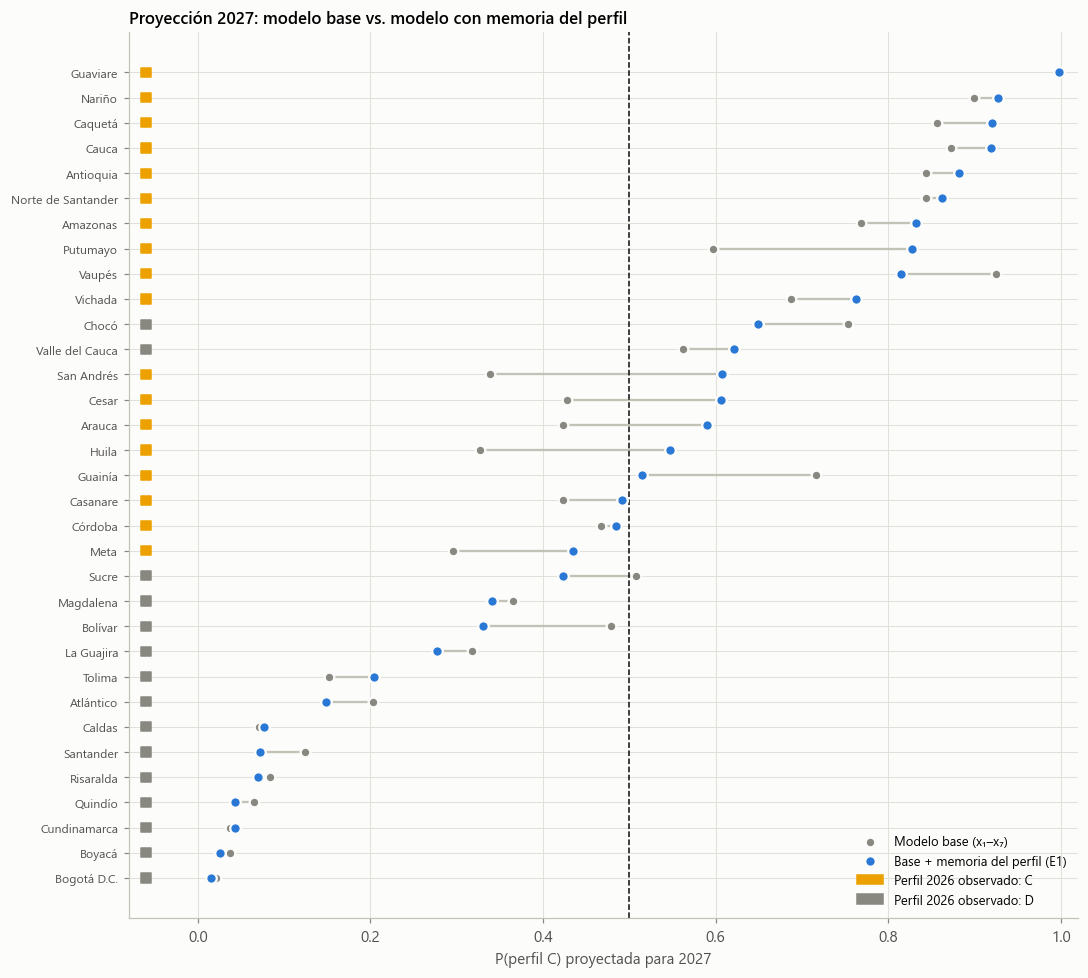

In [45]:
# =============================================================================
# 13.2 Efecto de la memoria en la proyección 2027 (ensamble de 5 semillas, 2021-2026)
# =============================================================================
cols_e1 = FEATURES + ["x8_memoria_C"]
esc_e1 = StandardScaler().fit(datos[cols_e1])
ens_e1 = [entrenar_fijo(esc_e1.transform(datos[cols_e1]).astype("float32"), y_all, semilla=s) for s in SEMILLAS_DESPLIEGUE]
F27 = calcular_features(base27)
F27["x8_memoria_C"] = base27["s_C"].fillna(prev_train).values
P27_e1 = np.mean([f(esc_e1.transform(F27[cols_e1]).astype("float32")) for f in ens_e1], axis=0)
comp27 = (proy[["depto", "Departamento", "Perfil 2026 observado", "P(C) 2027", "¿Coincide con la inercia?", "Datos suficientes"]]
          .merge(pd.DataFrame({"depto": base27["depto"].values, "P(C) 2027 con memoria (E1)": P27_e1}), on="depto")
          .rename(columns={"P(C) 2027": "P(C) 2027 base"}))
revisar = comp27[comp27["¿Coincide con la inercia?"] == "revisar"]
resueltos = int(((revisar["P(C) 2027 con memoria (E1)"] >= .5) == (revisar["Perfil 2026 observado"] == "C")).sum())
print(f"Discrepancias base vs. inercia: {len(revisar)} | resueltas al agregar la memoria: {resueltos}")
display(revisar.drop(columns=["depto", "¿Coincide con la inercia?"]).style.format(
    {"P(C) 2027 base": "{:.2f}", "P(C) 2027 con memoria (E1)": "{:.2f}"}).hide(axis="index"))

orden_c = comp27.sort_values("P(C) 2027 con memoria (E1)").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 9))
yy = np.arange(len(orden_c))
ax.hlines(yy, orden_c["P(C) 2027 base"], orden_c["P(C) 2027 con memoria (E1)"], color=EJE, lw=1.5)
ax.scatter(orden_c["P(C) 2027 base"], yy, s=40, color=COL["D"], edgecolor=FONDO, lw=1.5, zorder=3, label="Modelo base (x₁–x₇)")
ax.scatter(orden_c["P(C) 2027 con memoria (E1)"], yy, s=48, color=COL["mlp"], edgecolor=FONDO, lw=1.5, zorder=3,
           label="Base + memoria del perfil (E1)")
ax.scatter(np.full(len(orden_c), -0.06), yy, marker="s", s=36, clip_on=False, zorder=3,
           color=[COL["C"] if p == "C" else (COL["D"] if p == "D" else GRID) for p in orden_c["Perfil 2026 observado"]])
ax.axvline(0.5, color=TINTA, lw=1, ls="--")
ax.set_yticks(yy, orden_c["Departamento"], fontsize=8); ax.set_xlim(-0.08, 1.02)
ax.set_xlabel("P(perfil C) proyectada para 2027")
ax.set_title("Proyección 2027: modelo base vs. modelo con memoria del perfil")
ax.legend(handles=[*ax.get_legend_handles_labels()[0], Patch(color=COL["C"], label="Perfil 2026 observado: C"),
                   Patch(color=COL["D"], label="Perfil 2026 observado: D")], fontsize=8.5, loc="lower right")
fig.tight_layout(); guardar(fig, "fig23_proyeccion_con_memoria"); plt.show()

**Lectura.** Al incorporar la memoria del perfil, **9 de las 10 discrepancias** con la inercia se mueven en la
dirección del perfil observado y **5 se resuelven**, es decir, cruzan el umbral: Arauca (0,42 → 0,59), Cesar
(0,43 → 0,61), Huila (0,33 → 0,55), Sucre (0,51 → 0,42) y San Andrés (con pocos datos). Córdoba y Casanare quedan justo
en la frontera (0,49), y Meta sube de 0,30 a 0,43. Los dos casos que siguen en C pese a ser D en 2026, Chocó
(0,75 → 0,65) y Valle del Cauca (0,56 → 0,62), tienen una proporción C en 2026 a menos de 5 puntos del umbral (0,45
y 0,50), así que su propia etiqueta observada es ambigua. La memoria no sustituye un criterio por otro: **reconcilia**
la lectura estructural con la inercia. Por eso M1 es la primera prioridad del modelo operativo.

### 13.3 Hoja de ruta priorizada

| # | Mejora | Evidencia que la motiva | Acción concreta (Unidad 3) | Impacto esperado | Prioridad | Responsable |
|---|---|---|---|---|---|---|
| M1 | Memoria y dinámica del perfil | Persistencia AUC 0,96; 57 % de los errores en transiciones; E1: AUC 0,89 → 0,93 | Incorporar $s^C_{t-1}$, $s^C_{t-2}$ y la tendencia de eventos; evaluar con validación temporal | Alto (medido) | Alta | Juan Diego |
| M2 | Ensamble de redes | Varianza entre semillas; E2: AUC espacial 0,80 → 0,85 | Promediar 5–10 redes en el modelo operativo | Medio (medido) | Alta | Juan Diego |
| M3 | Migrar a municipio con el registro de evento individual de ACLED | Brecha espacial (§11.3), curva de aprendizaje sin converger, firmas departamentales | Solicitar el acceso académico a los datos por evento (municipio y actores). La coca SIMCI (datos.gov.co) y el IPM censal 2018 del DANE ya se publican por municipio | Muy alto | Alta | Conjunta |
| M4 | Completar $x_3$ (actores armados) y $x_6$ municipal | Errores persistentes en Arauca (frontera, ELN) no explicados por coca ni bosque | Contar actores distintos por territorio con `actor1/actor2`; distancia a cabecera con cartografía IGAC | Alto | Alta | Laura |
| M5 | Recalibrar probabilidades y elegir el umbral con varios años | Calibración bajo la diagonal; el umbral F2 = 0,17 no se transfiere a 2026 | Platt o *temperature scaling* sobre predicciones fuera de muestra 2023–2025; umbral por costo con varios años | Medio | Media | Juan Diego |
| M6 | Etiqueta ponderada por severidad u objetivo continuo | Hallazgo U1 §5.4 (A/B de bajo volumen y alto impacto); 20 % de las celdas a ±10 pp del umbral | Modelar $s^C$ como regresión o ponderar los eventos por fatalidades para que A/B puedan emerger; reabrir las 4 clases de la U1 | Alto (coherencia con la U1) | Media | Laura |
| M7 | Ajuste conjunto de capacidad, L2 y épocas con validación anidada | Sobreajuste con más de 8 neuronas (§11.3d); época óptima variable (CV 35 %) | Búsqueda bayesiana (KerasTuner u Optuna) con validación temporal anidada | Bajo–medio | Baja | Juan Diego |
| M8 | Refinar el mapeo de subtipos | *Shelling* y *Sexual violence* quedan en D por defecto (§3.4) | Reasignarlos a B y C y documentarlo en el diccionario | Bajo | Baja | Laura |

**Secuencia propuesta para la Unidad 3:** primero los datos (M3, M4), porque cambian la unidad de análisis y todo lo
que sigue. Después la arquitectura con memoria y ensamble (M1, M2) reentrenada a escala municipal. Por último la
calibración, el umbral y la etiqueta por severidad (M5, M6), con M7 y M8 como ajustes finos. Las decisiones de
priorización se toman en conjunto y quedan en la bitácora (§14.2).

---
# 14. Trabajo colaborativo y bitácora de decisiones

## 14.1 Distribución de responsabilidades en la Etapa 2

Mantuvimos la división acordada al cierre de la Etapa 1: Juan Diego lidera la implementación técnica y Laura la
interpretación estratégica y la comunicación. Las decisiones metodológicas se toman en conjunto.

| Frente de trabajo | Responsable | Entregable en este notebook |
|---|---|---|
| Auditoría del export actualizado y conciliación con la Etapa 1 | Juan Diego | §2 |
| Construcción del panel, regla de etiqueta y umbral de confiabilidad | Conjunta | §3 |
| Búsqueda e integración de fuentes externas (SIMCI/ODC, GFW, DANE) | Laura | §4 |
| Diseño del protocolo temporal y de las líneas base | Conjunta | §6 |
| Implementación del MLP, del bucle de entrenamiento y de la búsqueda de hiperparámetros | Juan Diego | §7–§8 |
| Métricas, curvas y diagnóstico técnico | Juan Diego (cálculo) · Laura (interpretación) | §9–§11 |
| Traducción a decisión, alerta A/B y énfasis tecnológico | Laura | §12 |
| Priorización de mejoras y revisión final de coherencia | Conjunta | §13–§15 |

## 14.2 Bitácora de decisiones técnicas

| # | Decisión | Alternativas consideradas | Justificación | Evidencia |
|---|---|---|---|---|
| D1 | Panel departamento–año (171 filas) | Municipio (sin datos gratuitos); departamento–mes (etiquetas muy ruidosas) | Compromiso declarado en la Etapa 1; equilibra tamaño muestral y confiabilidad de la etiqueta | §3 |
| D2 | Predecir $t$ con información de $t-1$ | Predictoras del mismo año | Evita la circularidad con la etiqueta y replica el momento real de la decisión | §1.1 |
| D3 | Umbral de 10 eventos para etiquetar | 5 o 20 eventos | Error estándar de $s^C$ ≤ 0,16; conserva el 88 % de las celdas con eventos | §3.3 |
| D4 | Regla y mapeo de subtipos idénticos a la Etapa 1 | Reasignar *Shelling* y *Sexual violence* | Trazabilidad; la sensibilidad mostró impacto mínimo | §3.4 |
| D5 | $x_3$ pendiente; $x_5$ y $x_6$ con fuente sustituta/proxy | Excluir el modelo hasta tener todas las fuentes | Avanzar con 6 de 7 variables definidas y declarar el faltante | §1.2, §4 |
| D6 | Partición temporal + validación cruzada de origen móvil | Partición aleatoria estratificada | La aleatoria filtra información del futuro y sobreestima el desempeño | §6 |
| D7 | Arquitectura por regla de 1 error estándar | Elegir el mínimo absoluto | Con $n$ pequeño se prefiere el modelo más simple estadísticamente equivalente | §7.2 |
| D8 | Bucle explícito con `tf.GradientTape` | `model.fit` | Diagnósticos por época y ≈6× menos tiempo; equivalencia verificada (diferencia máx. 2×10⁻⁶) | §8 |
| D9 | Reajuste final con 2021–2025 (fase 2) | Usar solo la fase 1 | Incorpora el año más reciente ante el cambio de prevalencia | §10 |
| D10 | Reentrenamientos sin validación con presupuesto fijo de 560 pasos (mediana de 10 semillas) | Usar las 45 épocas de la semilla 42 | La semilla 42 resultó atípica (se detuvo antes que casi todas); la mediana es un criterio más robusto y no usa la prueba | §11.2 |

---
# 15. Conclusiones técnicas

1. **Coherencia con el problema.** El modelo base responde a la pregunta de la Etapa 1 con la misma variable objetivo
   (regla del 50 %, C vs. D), 6 de sus 7 predictoras más la letalidad derivada, y en la unidad de análisis que la Etapa
   1 comprometió (panel departamento–año). El diseño $t-1 \rightarrow t$ reproduce el momento real de la decisión de
   inversión y evita la circularidad entre predictoras y etiqueta.
2. **Viabilidad técnica demostrada.** Un MLP de una capa oculta (145 parámetros), elegido por validación cruzada
   temporal, aprende una señal real: AUC fuera de muestra de 0,83–0,89 frente a 0,50 del azar. Además converge de forma
   estable, es reproducible entre semillas (CV 2,8 %) y está verificado contra la implementación de Keras.
3. **El límite es la generalización, no la optimización.** La red llega al óptimo de validación antes de la meseta de
   entrenamiento, las curvas por tamaño de muestra muestran un modelo limitado por varianza, y la validación espacial
   revela que con 30 departamentos la red memoriza firmas territoriales. Mejorar el optimizador no ayudaría; más
   unidades y mejores predictoras, sí.
4. **La hipótesis de no linealidad sigue abierta.** La red representa interacciones coherentes con la Etapa 1
   (coca × pobreza, bosque × distancia) que la logística no puede trazar, pero a esta escala no se traducen en una
   ventaja predictiva significativa. Es la conclusión honesta con n = 171, y un argumento cuantitativo para migrar a
   municipio.
5. **El hallazgo central es la inercia.** El perfil se repite el 86 % de las veces y la persistencia supera a
   cualquier modelo sin memoria. Las variables de la Etapa 1 explican *dónde* es probable cada perfil, pero no *cuándo
   cambia*. Con la memoria del perfil (E1) los modelos superan a la persistencia en calidad probabilística, y el valor
   diferencial de un modelo estructural pasa a estar en anticipar transiciones. La decisión útil no es repetir el mapa
   del año pasado, sino detectar dónde va a cambiar.
6. **Decisión.** La proyección 2027 separa 10 departamentos C consolidados, 13 en transición y 10 D. Suma una alerta
   A/B para Guaviare y Cauca, que rescata el vector de explosivos y drones que la etiqueta binaria diluye, y marca 10
   discrepancias con la inercia como casos de revisión. Es un insumo para priorizar, no un reemplazo del análisis de
   inteligencia.

---
# 16. Exportación de artefactos

In [46]:
# =============================================================================
# 16.1 Artefactos para el informe y para la siguiente iteración
# =============================================================================
datos.to_csv(DIR_SALIDA / "dataset_modelado_departamento_anio.csv", index=False)
MET.to_csv(DIR_SALIDA / "metricas_modelos.csv")
IC_TEST.to_csv(DIR_SALIDA / "intervalos_confianza_prueba.csv")
res_busq.to_csv(DIR_SALIDA / "busqueda_hiperparametros.csv", index=False)
ESTAB.to_csv(DIR_SALIDA / "estabilidad_semillas.csv")
pd.concat({"temporal": VT, "espacial": VE}).to_csv(DIR_SALIDA / "validacion_temporal_espacial.csv")
E1.to_csv(DIR_SALIDA / "experimento_E1_memoria.csv")
proy.drop(columns=["lat", "lon"]).merge(comp27[["depto", "P(C) 2027 con memoria (E1)"]], on="depto").to_csv(
    DIR_SALIDA / "proyeccion_2027.csv", index=False)
pd.DataFrame({k: v for k, v in HIST.items() if k != "ratio_act" and len(v) == len(HIST["epoca"])}).to_csv(
    DIR_SALIDA / "historial_entrenamiento.csv", index=False)
modelo.save(DIR_SALIDA / "modelo_base_fase1.keras")
modelo_f2.save(DIR_SALIDA / "modelo_reajustado_fase2.keras")
with open(DIR_SALIDA / "configuracion.json", "w", encoding="utf-8") as fh:
    json.dump({"config_mlp": {**asdict(CFG), "capas": list(CFG.capas)}, "C_logistica": C_LR, "mejor_epoca": INFO["mejor_epoca"],
               "umbral_F2_validacion": U_OPT, "min_eventos": MIN_EVENTOS, "features": FEATURES, "semilla": SEED,
               "particion": {"train": ANIOS_TRAIN, "val": ANIO_VAL, "test": ANIO_TEST}}, fh, ensure_ascii=False, indent=2)

archivos = sorted(p for p in DIR_SALIDA.rglob("*") if p.is_file())
display(pd.DataFrame({"Archivo": [str(p.relative_to(DIR_SALIDA)) for p in archivos],
                      "KB": [round(p.stat().st_size / 1024, 1) for p in archivos]}).style.hide(axis="index"))

Archivo,KB
busqueda_hiperparametros.csv,1.400000
configuracion.json,0.700000
dataset_modelado_departamento_anio.csv,55.000000
estabilidad_semillas.csv,1.100000
experimento_E1_memoria.csv,2.400000
figuras\fig01_cobertura_datos.png,381.000000
figuras\fig02_variable_objetivo.png,290.700000
figuras\fig03_predictoras_por_clase.png,298.200000
figuras\fig04_dependencia_correlacion.png,202.500000
figuras\fig05_interacciones_hipotesis.png,149.500000


---
# Anexo A. Material sugerido para el informe PDF (máximo 8 páginas)

El informe entregado (`Informe_U2_Modelo_Base.pdf`, 8 páginas, con su versión editable `.docx`) sigue el orden de la
guía de la actividad. Sus figuras son las del **Anexo B** (`salidas_u2/figuras_informe/`), redibujadas a tamaño de
impresión con los mismos resultados de este notebook.

| Sección del informe | Figuras (Anexo B) | Tablas | Origen en el notebook |
|---|---|---|---|
| 1. Recordatorio sintético del problema | – | Tabla 1: trazabilidad U1 → U2 | §1 |
| 2. Descripción del dataset | Figura 1 (`R1_variable_objetivo`) | Tabla 2: calidad | §2–§5 |
| 3. Arquitectura y configuración | Figura 2 (`R2_arquitectura`) | Tabla 3: configuración | §6–§8 |
| 4. Métricas de entrenamiento y validación | Figura 3 (`R4_metricas_prueba`) | Tabla 4: métricas | §10 |
| 5. Curvas de aprendizaje | Figura 4 (`R3_curvas_aprendizaje`) | – | §9 |
| 6. Diagnóstico técnico | Figuras 5–7 (`R5`, `R6`, `R7`) y 8 (`R8_proyeccion_2027`) | Tabla 5: síntesis | §11–§12 |
| 7. Oportunidades de mejora | – | Tablas 6 (E1/E2) y 7 (hoja de ruta) | §13 |
| 8. Trabajo colaborativo | – | Tabla 8: responsabilidades y decisiones | §14 |

---
# Anexo B. Figuras en tamaño de impresión para el informe

Las figuras del notebook están pensadas para pantalla (14–16 pulgadas de ancho). Al llevarlas a una página carta,
su texto quedaría en 4–5 pt. Esta celda redibuja las figuras que usa el informe con el ancho útil de la página
(6,6 pulgadas) y texto de 7–8 pt, a partir de **los mismos resultados calculados arriba**, sin reentrenar nada.
Se guardan en `salidas_u2/figuras_informe/` a 300 dpi.

In [47]:
# =============================================================================
# Anexo B. Figuras del informe (carta, 6,6" de ancho útil, 300 dpi)
# =============================================================================
DIR_INF = DIR_SALIDA / "figuras_informe"
DIR_INF.mkdir(parents=True, exist_ok=True)
ESTILO_INFORME = {"font.size": 7.2, "axes.titlesize": 7.6, "axes.labelsize": 7, "xtick.labelsize": 6.5,
                  "ytick.labelsize": 6.5, "legend.fontsize": 6.2, "lines.linewidth": 1.25, "axes.linewidth": 0.6,
                  "grid.linewidth": 0.45, "lines.markersize": 3.2, "axes.titlepad": 4}
FIG_INFORME = []

def guardar_inf(fig, nombre):
    fig.savefig(DIR_INF / f"{nombre}.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
    FIG_INFORME.append(nombre)
    plt.close(fig)

with mpl.rc_context(ESTILO_INFORME):
    # ---------- R1. Variable objetivo ----------
    sC_i = panel.pivot(index="depto", columns="anio", values="s_C")
    cf_i = panel.pivot(index="depto", columns="anio", values="confiable")
    pf_i = panel.pivot(index="depto", columns="anio", values="perfil")
    ord_i = sC_i.mean(axis=1).sort_values(ascending=False).index
    sC_i, cf_i, pf_i = sC_i.loc[ord_i], cf_i.loc[ord_i], pf_i.loc[ord_i]
    fig = plt.figure(figsize=(6.6, 3.75))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.45, 1], hspace=0.6, wspace=0.32)
    ax = fig.add_subplot(gs[:, 0])
    im = ax.imshow(sC_i.values, cmap=CMAP_C, vmin=0, vmax=1, aspect="auto")
    for i in range(sC_i.shape[0]):
        for j in range(sC_i.shape[1]):
            if not cf_i.values[i, j]:
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, facecolor=FONDO, edgecolor=GRID, hatch="////", lw=0))
                continue
            ax.text(j, i, pf_i.values[i, j], ha="center", va="center", fontsize=4.8,
                    color="white" if sC_i.values[i, j] > .62 else TINTA)
    ax.set_xticks(range(sC_i.shape[1]), sC_i.columns)
    ax.set_yticks(range(len(ord_i)), [NOMBRE[d] for d in ord_i], fontsize=5.4)
    ax.tick_params(length=0); ax.grid(False)
    ax.set_title("(a) Proporción de eventos C ($s^C$) y perfil")
    cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
    cb.ax.axhline(0.5, color=TINTA, lw=1); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=5.5)
    ax.set_xlabel("Celdas rayadas: < 10 eventos (excluidas)", fontsize=5.8, color=TINTA2)
    ax = fig.add_subplot(gs[0, 1])
    cnt = etiquetables.groupby(["anio", "perfil"]).size().unstack(fill_value=0)[["C", "D"]]
    ax.bar(cnt.index, cnt["D"], color=COL["D"], width=0.6, label="D (mixto)")
    ax.bar(cnt.index, cnt["C"], bottom=cnt["D"], color=COL["C"], width=0.6, label="C (convencional)", edgecolor=FONDO, lw=1)
    for a in cnt.index:
        ax.text(a, cnt.loc[a].sum() + 0.5, f"{cnt.loc[a, 'C'] / cnt.loc[a].sum():.0%}", ha="center", fontsize=5.8, color=TINTA2)
    ax.set_ylim(0, 37); ax.set_title("(b) Departamentos por perfil (% C)"); ax.legend(ncol=2, loc="upper left", fontsize=5.6)
    ax.set_xticks(cnt.index, cnt.index, fontsize=6)
    ax = fig.add_subplot(gs[1, 1])
    ax.hist(etiquetables["s_C"], bins=np.linspace(0, 1, 21), color=COL["C"], edgecolor=FONDO, linewidth=0.8)
    ax.axvline(0.5, color=TINTA, lw=1, ls="--")
    ax.set_title("(c) Distribución de $s^C$ (20 % a ±10 pp del umbral)"); ax.set_xlabel("$s^C_{d,t}$")
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    guardar_inf(fig, "R1_variable_objetivo")

    # ---------- R2. Arquitectura ----------
    fig, ax = plt.subplots(figsize=(3.0, 2.25)); ax.axis("off"); ax.grid(False)
    tam = [len(FEATURES), CFG.capas[0], 1]; xs = [0, 2.2, 4.0]
    pos = [[(x, y) for y in np.linspace(-(n - 1) / 2, (n - 1) / 2, n) * (0.42 if n > 8 else 0.62)] for x, n in zip(xs, tam)]
    for a_, b_ in zip(pos[:-1], pos[1:]):
        for (x1, y1) in a_:
            for (x2, y2) in b_:
                ax.plot([x1, x2], [y1, y2], color=GRID, lw=0.35, zorder=1)
    for capa, color in zip(pos, [COL["D"], COL["mlp"], COL["C"]]):
        for (x, y) in capa:
            ax.scatter(x, y, s=22, color=color, edgecolor=FONDO, lw=0.8, zorder=3)
    for (x, y), f in zip(pos[0], FEATURES):
        ax.text(x - 0.18, y, ETIQ[f], ha="right", va="center", fontsize=5.3, color=TINTA2)
    ax.text(xs[2] + 0.15, 0, "P(C | x$_{t-1}$)", ha="left", va="center", fontsize=6.2)
    tope = max(abs(y) for _, y in pos[1])
    for x, t in zip(xs, ["Entrada\n7 variables", f"Oculta\n{CFG.capas[0]} ReLU · He\nL2 = {CFG.l2:g}", "Salida\nsigmoide"]):
        ax.text(x, -tope - 0.45, t, ha="center", va="top", fontsize=5.6, color=TINTA2)
    ax.set_xlim(-2.2, 5.3); ax.set_ylim(-tope - 1.6, tope + 0.3)
    guardar_inf(fig, "R2_arquitectura")

    # ---------- R3. Curvas de aprendizaje ----------
    ep_i = np.array(HIST["epoca"]); be_i = INFO["mejor_epoca"]
    cortes_i = [e for e, a, b in zip(ep_i[1:], HIST["lr"][:-1], HIST["lr"][1:]) if b < a]
    fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.05))
    ax = axes[0]
    ax.plot(ep_i, HIST["perdida_obj"], color=COL["train"], lw=0.8, alpha=0.35, label="Objetivo (BCE pond. + L2)")
    ax.plot(ep_i, HIST["bce_tr"], color=COL["train"], label="Entrenamiento")
    ax.plot(ep_i, HIST["bce_va"], color=COL["val"], label="Validación 2025")
    ax.axhline(H0, color=TENUE, lw=0.8, ls="--", label="Predictor constante")
    ax.set_title("(a) Entropía cruzada (BCE)"); ax.set_xlabel("Época")
    ax.legend(loc="upper right", fontsize=5.4, frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    ax = axes[1]
    ax.plot(ep_i, HIST["acc_tr"], color=COL["train"], label="Entrenamiento"); ax.plot(ep_i, HIST["acc_va"], color=COL["val"], label="Validación 2025")
    ax.axhline(1 - prev_train, color=TENUE, lw=0.8, ls="--"); ax.text(ep_i[-1], 1 - prev_train + 0.006, "clase mayoritaria", ha="right", va="bottom", fontsize=5.4, color=TINTA2)
    ax.set_title("(b) Exactitud (umbral 0,5)"); ax.set_xlabel("Época"); ax.legend(loc="lower right", fontsize=5.6)
    ax = axes[2]
    ax.plot(ep_i, HIST["auc_tr"], color=COL["train"], label="Entrenamiento"); ax.plot(ep_i, HIST["auc_va"], color=COL["val"], label="Validación 2025")
    ax.set_title("(c) ROC-AUC"); ax.set_xlabel("Época"); ax.legend(loc="lower right", fontsize=5.6)
    for a_ in axes:
        a_.axvline(be_i, color=TINTA, lw=0.8, ls=":")
        for c in cortes_i:
            a_.axvline(c, color=TENUE, lw=0.5, ls="--")
    axes[0].text(be_i + 2, axes[0].get_ylim()[0] + 0.02, f"mejor época = {be_i}", fontsize=5.6)
    fig.tight_layout(w_pad=1.2); guardar_inf(fig, "R3_curvas_aprendizaje")

    # ---------- R4. Métricas en prueba: ROC, calibración y matriz de confusión ----------
    fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.1), gridspec_kw={"width_ratios": [1, 1, 0.8]})
    ax = axes[0]
    for nombre, color, ls in [("MLP fase 2", COL["mlp"], "-"), ("MLP fase 1", COL["mlp"], ":"), ("Logística fase 2", COL["logit"], "-"), ("Persistencia", COL["pers"], "--")]:
        p = P[(nombre, "Prueba")]; fpr, tpr, _ = roc_curve(yte, p)
        ax.plot(fpr, tpr, color=color, ls=ls, label=f"{nombre} ({roc_auc_score(yte, p):.2f})")
    ax.plot([0, 1], [0, 1], color=EJE, lw=0.7); ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad C")
    ax.set_title("(a) ROC en prueba 2026 (AUC)"); ax.legend(fontsize=5.3, loc="lower right")
    ax = axes[1]; ax.plot([0, 1], [0, 1], color=EJE, lw=0.7)
    for nombre, color in [("MLP fase 1", COL["mlp"]), ("Logística fase 1", COL["logit"])]:
        p = np.concatenate([P[(nombre, "Validación")], P[(nombre, "Prueba")]])
        fr, mp = calibration_curve(y_fuera, p, n_bins=5, strategy="quantile")
        ax.plot(mp, fr, marker="o", color=color, mec=FONDO, mew=0.8, label=f"{nombre} (Brier {brier_score_loss(y_fuera, p):.3f})")
    ax.set_xlabel("P(C) media predicha"); ax.set_ylabel("Fracción observada de C")
    ax.set_title("(b) Calibración (validación + prueba)"); ax.legend(fontsize=5.3, loc="upper left")
    ax = axes[2]
    cm = confusion_matrix(yte.astype(int), (P[("MLP fase 2", "Prueba")] >= .5).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap=CMAP_P, vmin=0, vmax=cm.max() * 1.3); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center", fontsize=6.5,
                    color="white" if cm[i, j] > cm.max() * 0.65 else TINTA)
    ax.set_xticks([0, 1], ["D", "C"]); ax.set_yticks([0, 1], ["D", "C"]); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    ax.set_title("(c) MLP fase 2 · prueba")
    fig.tight_layout(w_pad=1.2); guardar_inf(fig, "R4_metricas_prueba")

    # ---------- R5. Convergencia y estabilidad ----------
    rat_i = np.array(HIST["ratio_act"]); capas_i = [c.name for c in modelo.layers if hasattr(c, "kernel")]
    fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.0))
    ax = axes[0]
    ax.plot(ep_i, HIST["norma_grad"], color=COL["mlp"], lw=0.8, alpha=0.6)
    ax.plot(ep_i, pd.Series(HIST["norma_grad"]).rolling(15, min_periods=1).mean(), color=TINTA, lw=1.1, label="media móvil 15 ép.")
    ax.set_yscale("log"); ax.set_title("(a) Norma global del gradiente"); ax.set_xlabel("Época")
    ax.legend(fontsize=5.6, frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    ax = axes[1]
    for j, (nombre, color) in enumerate(zip(capas_i, [COL["mlp"], COL["logit"]])):
        ax.plot(ep_i, rat_i[:, j], color=color, lw=0.9, label=nombre)
    ax.axhspan(1e-4, 1e-2, color=GRID, alpha=0.5, lw=0); ax.set_yscale("log")
    ax.set_title("(b) Razón de actualización ‖ΔW‖/‖W‖"); ax.set_xlabel("Época")
    ax.legend(fontsize=5.6, loc="lower left", frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    for a_ in axes[:2]:
        a_.axvline(be_i, color=TINTA, lw=0.8, ls=":")
        for c in cortes_i:
            a_.axvline(c, color=TENUE, lw=0.5, ls="--")
    ax = axes[2]
    for c in curvas_va:
        ax.plot(range(1, len(c) + 1), c, color=COL["mlp"], lw=0.6, alpha=0.5)
        k = int(np.argmin(c)); ax.scatter(k + 1, c[k], s=9, color=COL["val"], zorder=3)
    ax.set_ylim(0.3, 1.0); ax.set_title("(c) BCE de validación, 10 semillas"); ax.set_xlabel("Época")
    fig.tight_layout(w_pad=1.2); guardar_inf(fig, "R5_convergencia_estabilidad")

    # ---------- R6. Generalización y sesgo–varianza ----------
    fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.1))
    ax = axes[0]
    for mod, color, ls in [("MLP", COL["mlp"], "-"), ("Logística", COL["logit"], "-"), ("Persistencia", COL["pers"], "--")]:
        s = VT[VT.Modelo == mod]
        ax.plot(s["Partición"], s["ROC-AUC"], color=color, ls=ls, marker="o", mec=FONDO, mew=0.8, label=mod)
    ax.set_title("(a) AUC por año predicho (temporal)"); ax.set_xlabel("Año (entrenando con los anteriores)"); ax.legend(fontsize=5.6, loc="lower left")
    ax = axes[1]; nn_i = CURVA_N.index.values
    for col, color, ls, et in [("MLP prueba", COL["mlp"], "-", "MLP prueba"), ("MLP train", COL["mlp"], ":", "MLP entren."),
                               ("Logística prueba", COL["logit"], "-", "Log. prueba"), ("Logística train", COL["logit"], ":", "Log. entren.")]:
        ax.plot(nn_i, CURVA_N[(col, "mean")].values, color=color, ls=ls, marker="o", label=et)
    ax.set_ylim(0.25, 0.92); ax.set_title("(b) BCE vs. tamaño de muestra"); ax.set_xlabel("Filas de entrenamiento")
    ax.legend(fontsize=5.2, loc="upper right", ncol=2, columnspacing=0.8, handlelength=1.8, frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    ax = axes[2]
    for regimen, color, et in [("Sin regularización", COL["logit"], "Sin regularización"), ("Con L2 del modelo base", COL["mlp"], "Con L2 = 10⁻³")]:
        s = CAPACIDAD[CAPACIDAD["régimen"] == regimen]
        ax.plot(s["unidades"], s["BCE train"], color=color, ls=":", marker="o", ms=2.5)
        ax.plot(s["unidades"], s["BCE validación"], color=color, marker="o", label=et)
    ax.axvline(CFG.capas[0], color=TINTA, lw=0.8, ls=":"); ax.set_xscale("log", base=2); ax.set_xticks(UNIDADES, UNIDADES)
    ax.set_title("(c) Capacidad, 400 épocas fijas"); ax.set_xlabel("Neuronas en la capa oculta"); ax.set_ylim(0.05, 0.98)
    manejadores = ax.get_legend_handles_labels()[0] + [Line2D([], [], color=TENUE, ls="-", label="validación"),
                                                        Line2D([], [], color=TENUE, ls=":", label="entrenamiento")]
    ax.legend(handles=manejadores, fontsize=5.2, loc="upper left", ncol=2, columnspacing=0.8, handlelength=1.8,
              frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    fig.tight_layout(w_pad=1.2); guardar_inf(fig, "R6_generalizacion")

    # ---------- R7. Superficies de dependencia parcial ----------
    def pdp_completo(pred_fn, fx, fy, n=35):
        base = datos.loc[m_tr, FEATURES].reset_index(drop=True)
        gx = np.linspace(datos[fx].min(), datos[fx].max(), n); gy = np.linspace(datos[fy].min(), datos[fy].max(), n)
        GX, GY = np.meshgrid(gx, gy)
        rep = pd.concat([base] * (n * n), ignore_index=True)
        rep[fx] = np.repeat(GX.ravel(), len(base)); rep[fy] = np.repeat(GY.ravel(), len(base))
        Z = pred_fn(escalador.transform(rep[FEATURES]).astype("float32")).reshape(n * n, len(base)).mean(axis=1).reshape(n, n)
        return gx, gy, Z
    fig, axes = plt.subplots(1, 4, figsize=(6.6, 1.85))
    for k, ((fx, fy), (nombre, fn)) in enumerate([(("x5_bosque", "x6_distancia"), ("MLP", predecir)), (("x5_bosque", "x6_distancia"), ("Logística", pred_lr_fn)),
                                                (("x4_coca", "x7_ipm"), ("MLP", predecir)), (("x4_coca", "x7_ipm"), ("Logística", pred_lr_fn))]):
        ax = axes[k]; gx, gy, Z = pdp_completo(fn, fx, fy)
        cs = ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11), cmap=CMAP_P, vmin=0, vmax=1)
        ax.contour(gx, gy, Z, levels=[0.5], colors=TINTA, linewidths=1)
        for clase, color in [(0, COL["D"]), (1, COL["C"])]:
            s = datos[m_tr & (datos.y == clase).values]
            ax.scatter(s[fx], s[fy], s=6, color=color, edgecolor=TINTA, lw=0.25, zorder=3)
        ax.grid(False); ax.set_xlabel(ETIQ[fx], fontsize=6); ax.set_ylabel(ETIQ[fy], fontsize=6)
        ax.set_title(f"({'abcd'[k]}) {nombre}", fontsize=7)
    fig.subplots_adjust(wspace=0.6, right=0.9)
    cax = fig.add_axes([0.925, 0.18, 0.012, 0.68])
    cb = fig.colorbar(cs, cax=cax); cb.set_label("P(C)", fontsize=6); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=5.5)
    guardar_inf(fig, "R7_dependencia_parcial")

    # ---------- R8. Mapa esquemático de la proyección 2027 ----------
    fig, ax = plt.subplots(figsize=(3.25, 3.75))
    tam_i = 8 + 2.2 * np.sqrt(proy["Eventos 2026 (anualizados)"].clip(lower=1))
    sc_i = ax.scatter(proy["lon"], proy["lat"], s=tam_i, c=proy["P(C) 2027"], cmap=CMAP_P, vmin=0, vmax=1,
                      edgecolor=FONDO, lw=0.8, zorder=3)
    al_i = proy[proy["alerta_AB"].fillna(False)]
    ax.scatter(al_i["lon"], al_i["lat"], s=tam_i[al_i.index] + 70, facecolor="none", edgecolor="#d03b3b", lw=1.1, zorder=2)
    izq_i = {"valle del cauca", "risaralda", "quindio", "sucre", "cordoba", "choco", "narino", "cauca"}
    for _, r in proy.iterrows():
        izq = r["depto"] in izq_i
        dx = 8 if bool(r["alerta_AB"]) else 4
        ax.annotate(f"{r['Departamento']} {r['P(C) 2027']:.2f}".replace(".", ","), (r["lon"], r["lat"]),
                    xytext=(-dx if izq else dx, -1.5), textcoords="offset points", ha="right" if izq else "left",
                    fontsize=4.6, color=TINTA if r["Datos suficientes"] else TENUE)
    ax.set_aspect("equal"); ax.set_xlim(-82.2, -66.2); ax.set_ylim(-4.6, 14.2)
    ax.tick_params(labelsize=5); ax.set_xlabel("Longitud", fontsize=5.5); ax.set_ylabel("Latitud", fontsize=5.5)
    cb = fig.colorbar(sc_i, ax=ax, fraction=0.035, pad=0.02); cb.set_label("P(perfil C) 2027", fontsize=5.5)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=5)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="none", mec="#d03b3b", mew=1.1, ms=6, label="Alerta A/B (IED/drones)"),
                       Line2D([], [], marker="o", ls="", color=TENUE, ms=3, label="Rótulo gris: pocos datos")],
              loc="lower left", fontsize=4.6, frameon=True, facecolor=FONDO, edgecolor="none", framealpha=1)
    guardar_inf(fig, "R8_proyeccion_2027")

print(f"Figuras del informe guardadas en {DIR_INF}/:", ", ".join(FIG_INFORME))

Figuras del informe guardadas en salidas_u2\figuras_informe/: R1_variable_objetivo, R2_arquitectura, R3_curvas_aprendizaje, R4_metricas_prueba, R5_convergencia_estabilidad, R6_generalizacion, R7_dependencia_parcial, R8_proyeccion_2027


---
# Referencias

ACLED. (2024). *ACLED codebook*. Armed Conflict Location & Event Data Project. https://acleddata.com

Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213. https://doi.org/10.1016/j.ins.2011.12.028

Bishop, C. M., & Bishop, H. (2024). *Deep learning: Foundations and concepts*. Springer.

Centro Nacional de Memoria Histórica. (2022). *Presencia diferenciada del Estado colombiano*. CNMH.

Departamento Administrativo Nacional de Estadística. (2019). *Pobreza multidimensional por departamentos 2018: Resultados* [Presentación]. DANE. https://www.dane.gov.co

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923. https://doi.org/10.1162/089976698300017197

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.

Hansen, M. C., Potapov, P. V., Moore, R., Hancher, M., Turubanova, S. A., Tyukavina, A., … Townshend, J. R. G. (2013). High-resolution global maps of 21st-century forest cover change. *Science, 342*(6160), 850–853. https://doi.org/10.1126/science.1244693

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2.ª ed.). Springer.

He, K., Zhang, X., Ren, S., & Sun, J. (2015). Delving deep into rectifiers: Surpassing human-level performance on ImageNet classification. En *Proceedings of the IEEE International Conference on Computer Vision* (pp. 1026–1034).

Hornik, K. (1991). Approximation capabilities of multilayer feedforward networks. *Neural Networks, 4*(2), 251–257. https://doi.org/10.1016/0893-6080(91)90009-T

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. En *International Conference on Learning Representations*. https://arxiv.org/abs/1412.6980

Ministerio de Justicia y del Derecho – Observatorio de Drogas de Colombia. (2026). *Detección de cultivos de coca (hectáreas)* [Conjunto de datos]. Datos Abiertos Colombia. https://www.datos.gov.co/d/acs4-3wgp

Prechelt, L. (1998). Early stopping — but when? En G. B. Orr & K.-R. Müller (Eds.), *Neural networks: Tricks of the trade* (pp. 55–69). Springer. https://doi.org/10.1007/3-540-49430-8_3

Raleigh, C., Linke, A., Hegre, H., & Karlsen, J. (2010). Introducing ACLED: An armed conflict location and event dataset. *Journal of Peace Research, 47*(5), 651–660. https://doi.org/10.1177/0022343310378914

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., … Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research, 15*, 1929–1958.

United Nations Office on Drugs and Crime. (2024). *Colombia: Monitoreo de territorios afectados por cultivos ilícitos 2023*. UNODC–SIMCI.

World Resources Institute. (2025). *Global Forest Watch: Colombia tree cover loss by subnational region* [Conjunto de datos]. https://www.globalforestwatch.org

---

**Declaración de uso de inteligencia artificial.** *[El equipo debe completar esta declaración describiendo con
honestidad qué herramientas de IA usó y para qué, en el mismo espíritu de la declaración de la Etapa 1, y confirmar
que ejecutó, revisó y comprende cada sección antes de entregar.]*

In [48]:
print(f"Ejecución completa. Figuras exportadas: {len(FIGURAS)} en {DIR_FIG}/")

Ejecución completa. Figuras exportadas: 23 en salidas_u2\figuras/
